# Predicting Next-Day Cross-Sectional Equity Returns
## A depth-first study of **daily price & volume (OHLCV)** as a return-predictive data source

**Author:** Rishit &nbsp;|&nbsp; **Universe:** ~1,000 most-liquid US equities &nbsp;|&nbsp; **Sample:** 2005–2026 &nbsp;|&nbsp; **Data cost:** \$0 (free)

---

### How to read this notebook

This is a **complete research record**, not a highlight reel. It documents every decision, the alternatives rejected,
and the limitations of what was chosen, so it can answer questions from the basic ("what is one row?") to the
uncomfortable ("did the pipeline manufacture the signal?").

The narrative avoids words such as *proved*, *caused* and *ceiling*. Several tests failed, the only extra feature that
helps is a known low-volatility factor, and the most interesting diagnostic shows the signal is earned overnight. Where
the data can't identify a cause, the notebook gives a best guess and the test that would settle it.

> **Faculty-review additions.** The original core specification is frozen. New sensitivity and implementation cells are
> explicitly labeled *post-review*: momentum-horizon sensitivity, individual 3/5/10 reversal diagnostics, prediction-vs-
> attribution clarification for ML, expanded portfolio statistics, and a close→open implementation test. None of these
> is used to retune the original signal.

**Structure**
1. **Economic thesis** — why price/volume might carry next-day cross-sectional information, and who is on the other side.
2. **Raw data** — one observation, coverage, timing, and where quality is weakest.
3. **Data cleaning** — issues found and fixed, source-specific checks, and a universe-composition audit.
4. **Feature engineering** — raw fields → one score per stock per day; scaling, outliers, missing data; standalone ICs and post-review horizon sensitivities.
5. **Statistical foundations** — properties of the data that shape what any model can achieve.
6. **Beyond the core signal** — extra signals and anomalies (standalone and incremental tests), plus ML prediction-vs-attribution diagnostics.
7. **Evaluation** — criteria, walk-forward results by period, block-bootstrap uncertainty.
8. **Robustness, falsification, and the overnight finding** — attacks on the signal, universe composition, the overnight
   split by leg, index-rebalance closes, and volume/dispersion tests.
9. **Tradeability** — a full daily long-short backtest, transaction-cost sensitivity, and a stylized close→open/open→close implementation test.
10. **Limitations & next steps.**
11. **Appendix** — a reproducibility check of every number quoted in the text.


---
## 0. Executive summary

| | |
|---|---|
| **Data** | Daily OHLCV from Stooq (free). About 20.6M raw rows, 1962–2026; the research sample is a point-in-time top-1,000 liquid universe, 2005–2026. `panel.parquet` was assembled outside this notebook, so §3.4a audits security type. |
| **Signal** | Equal-weight blend of the cross-sectional ranks of (a) a market-demeaned 12–1 cumulative-return proxy ("momentum") and (b) a 3/5/10-session reversal composite formed with a one-day skip. |
| **Core result** | Walk-forward Spearman IC **+0.0131** (IR 1.09, 4,943 days), 21-session block-bootstrap 95% CI **[+0.0083, +0.0178]**. Momentum carries most of it (standalone IC **+0.0129**). Reversal is weaker (**+0.0071**) but nearly uncorrelated with momentum (**−0.017**), so the blend has the best IR (1.20). The 2022–26 period is strongest (**+0.0203**), but it was seen during development, and much of that edge is universe composition: in the top 250 names the IC barely changes between eras (§8.1b). |
| **Where it is earned** | Almost entirely overnight. Momentum: close→open IC **+0.0350** vs open→close **+0.0013** (not significant). Reversal: **+0.0137** vs **−0.0003**. This reproduces Lou, Polk & Skouras (2019), who find momentum and short-term reversal profits accrue overnight in CRSP data. Index-rebalance closes show no detectable spike, though with 22 Russell and 85 S&P events that test is weak. |
| **Liquidity-pressure tests** | Reversal is stronger after high abnormal volume: high − low **+0.0082** [+0.0051, +0.0115]. It is also stronger after high cross-sectional dispersion (**+0.0156** [+0.0057, +0.0253]), and that survives dropping the crisis years and ranking dispersion within each year (+0.0220, positive in 18 of 22 years). My prior was that the dispersion effect lived in crises; it doesn't. With past-only thresholds, the version you could trade, it shrinks to **+0.0105** [+0.0012, +0.0194]. |
| **Timing and bounce** | Reversal IC is **0.0109** using day `T`'s return, **0.0070** with the tradeable one-day skip and **0.0068** with two. Day `T`, where bid-ask bounce lives, carries about a third of reversal IC and is excluded by design; the rest doesn't decay. Rank lag-1 dependence is most negative in the most-liquid quintile (about −0.022 vs −0.014 in the least liquid), which is not the illiquid-bounce pattern. |
| **Extra features** | Only a low-volatility family adds information beyond momentum + reversal: idiosyncratic volatility (unique IC **+0.0109**) and MAX (**+0.0091**) both survive a correction for seven candidates, and they are correlated at 0.68, so this is one finding. Skewness doesn't survive the correction (p = 0.19); gap-fade, intraday reversal, close location and vol term structure add nothing. |
| **ML** | **Prediction and attribution are separate questions.** Raw walk-forward GBM has the strongest OOS IC (**+0.0173**). Neutralizing volatility, size and prior-day move is an attribution diagnostic, not a recommendation to discard predictive information: after that diagnostic, GBM's gain over momentum + reversal is **+0.0010 [−0.0002, +0.0023]**. |
| **Universe audit** | No obvious ETFs are present; current ETF flags touch about 0.2% of universe rows, and dropping them leaves the IC at +0.0132. The universe's depth changes a lot: the top 1,000 was about 54% of eligible names in 2005 and 14% in 2026, and the 1,000th name's trailing ADV rose from about \$2M to about \$89M. That explains much of the stronger recent IC: with fixed weights, 2022–26 minus 2005–17 is **+0.0074** in the top 1,000, **+0.0042** at constant depth and **+0.0006** in the top 250 (§8.1b). |
| **Tradeability** | The core daily decile book has gross Sharpe about **0.54** and break-even about **4.6 bps** per dollar traded, before impact and borrow. §9 reports full portfolio diagnostics and then tests close→open and open→close books directly, using the same pre-return weights and an explicit round-trip turnover convention. |
| **Biggest caveat** | Survivorship: the free feed mostly lacks dead stocks. Its size is unknown; the likely direction inflates reversal and deflates momentum. |

**The one-paragraph story.** Daily OHLCV carries a small but statistically detectable amount of next-day
cross-sectional information. Most of it is slow momentum; short-horizon reversal adds a nearly independent piece that is **consistent with** a liquidity-provision interpretation,
with stronger reversal after abnormal volume and after high dispersion. Both are realized close→open,
the same pattern Lou, Polk & Skouras (2019) document in CRSP data, which makes a vendor artifact less likely. The
stronger IC in 2022–26 largely reflects a more liquid universe: in the top 250 names it barely changed. The one extra OHLCV feature with unique information is low volatility, a known factor, and the ML models mostly rediscover it.
Survivorship is the largest unresolved bias, and the right next step is to replicate this frozen design on a
survivorship-safe common-stock dataset.

> **Scope.** The assignment values reasoning over indiscriminate model complexity. The notebook now includes a full
> portfolio backtest and a stylized overnight implementation test, but keeps the original signal frozen and labels all
> post-review additions explicitly. §11 checks every hard-coded headline number quoted in the text against the run.


---
## Setup

Mount Drive and set the data path. The raw input `panel.parquet` is read from `DRIVE`. Every intermediate panel this
notebook writes (continuous, clean, features, walk-forward) goes to its own subfolder `OUT` with a small manifest, and
each later section reads it through `load_stage`, which stops if the file was written by a different notebook version,
has changed since it was written, or lacks a required column. Any section can be re-run from its saved input without
recomputing everything upstream, and an older notebook writing to the same Drive can't feed this one stale data.


In [2]:
# --- Colab setup ---
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats
from scipy.stats import spearmanr
import warnings
import math
warnings.filterwarnings("ignore")

DRIVE = "/content/drive/MyDrive/NYSE stocks data"

# ---- house plotting style: clean, high-contrast, presentation-grade ----
plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 120, "font.size": 11,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.labelsize": 10.5, "legend.fontsize": 9.5,
    "figure.facecolor": "white", "axes.facecolor": "white",
})
# consistent palette
C_GOOD, C_BAD, C_NEU = "#1a9850", "#d73027", "#4575b4"
C_MOM, C_REV, C_COMBO = "#762a83", "#e08214", "#1b7837"
print("Setup complete. DRIVE =", DRIVE)
import os, json, uuid, datetime

# ---- Run-isolated intermediate files ---------------------------------------------------------
# The raw input (panel.parquet) stays in DRIVE. Every file this notebook WRITES goes to OUT, a folder
# used only by this version, so an older notebook writing to DRIVE can never overwrite it mid-run.
RUN_TAG = "trexquant_ohlcv_v11_faculty_review"
OUT = f"{DRIVE}/{RUN_TAG}"
os.makedirs(OUT, exist_ok=True)
SESSION_ID = uuid.uuid4().hex[:12]

# Columns each stage must contain. A missing column means a stale or foreign file, so reading stops.
_CONT = ["ticker","date","open","high","low","close","vol","bad_obs","ret_raw_adj","split_like",
         "ret_actual","ret_feature"]
REQUIRED = {
    "panel_continuous": _CONT,
    "panel_clean": _CONT + ["stale60","elig","dollar_vol","adv60","liq_rank","in_universe"],
    "panel_feat": _CONT + ["elig","dollar_vol","adv60","in_universe","mom","rev","fwd_ret",
                           "mom_r","rev_r","signal_r","fwd_xs"],
    "panel_live": ["ticker","date","mom_r","rev_r","fwd_ret","fwd_xs","combo","combo_r"],
}

def save_stage(df, name):
    """Write a stage to OUT with a manifest recording who wrote it, when, and its shape."""
    path = f"{OUT}/{name}.parquet"
    df.to_parquet(path)
    meta = dict(stage=name, run_tag=RUN_TAG, session=SESSION_ID, rows=int(len(df)),
                columns=[str(c) for c in df.columns],
                written_utc=datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M:%S"))
    with open(f"{OUT}/{name}.manifest.json", "w") as fh:
        json.dump(meta, fh)
    print(f"[save_stage] {name}: {len(df):,} rows, {df.shape[1]} columns → {path}")

def load_stage(name):
    """Read a stage written by THIS notebook version and verify it before use."""
    path, mpath = f"{OUT}/{name}.parquet", f"{OUT}/{name}.manifest.json"
    assert os.path.exists(path) and os.path.exists(mpath), \
        f"{name} has not been built by {RUN_TAG} yet: run the cells above first."
    meta = json.load(open(mpath))
    assert meta["run_tag"] == RUN_TAG, f"{name} was written by {meta['run_tag']}, not {RUN_TAG}."
    df = pd.read_parquet(path)
    assert len(df) == meta["rows"], \
        f"{name}: {len(df):,} rows on disk but {meta['rows']:,} in its manifest. The file changed after it was written."
    missing = [c for c in REQUIRED.get(name, []) if c not in df.columns]
    assert not missing, f"{name} is missing required columns {missing}: stale or foreign file."
    if meta["session"] != SESSION_ID:
        print(f"[load_stage] note: {name} was written by an earlier session ({meta['written_utc']} UTC). "
              "Fine while iterating; do Restart and Run all before submitting.")
    return df

RESULTS = {}   # headline numbers, recorded as cells run and checked against the text in §11
print("Intermediate files go to OUT =", OUT)

# ---- market-date adjacency helpers ----
# A groupby().shift() means "previous/next observed row", not necessarily the
# previous/next market session. These helpers let every target/diagnostic
# explicitly require adjacency on the market-wide date calendar.
def make_market_date_maps(dates):
    cal = pd.Index(pd.to_datetime(pd.Series(dates).dropna().unique())).sort_values()
    prev_map = pd.Series(cal[:-1].to_numpy(), index=cal[1:]) if len(cal) > 1 else pd.Series(dtype="datetime64[ns]")
    next_map = pd.Series(cal[1:].to_numpy(), index=cal[:-1]) if len(cal) > 1 else pd.Series(dtype="datetime64[ns]")
    return prev_map, next_map

def prev_adjacent_mask(frame, prev_map, ticker_col="ticker", date_col="date"):
    prev_date = frame.groupby(ticker_col, sort=False)[date_col].shift(1)
    return prev_date.eq(frame[date_col].map(prev_map))

def next_adjacent_mask(frame, next_map, ticker_col="ticker", date_col="date"):
    next_date = frame.groupby(ticker_col, sort=False)[date_col].shift(-1)
    return next_date.eq(frame[date_col].map(next_map))

# ---- statistics helpers used from §6 onward ----
def daily_ic(frame, x, y, minn=50, date_col="date"):
    # Per-date Spearman rank IC, vectorized. Average ranks for ties, so each date's value equals
    # scipy.stats.spearmanr. A date needs >= minn names and more than two distinct x values.
    d = frame[[date_col, x, y]].dropna()
    g = d.groupby(date_col)
    d = d[(g[x].transform("size") >= minn) & (g[x].transform("nunique") > 2)]
    if d.empty:
        return pd.Series(dtype=float)
    rx = d.groupby(date_col)[x].rank()
    ry = d.groupby(date_col)[y].rank()
    rx = rx - rx.groupby(d[date_col]).transform("mean")
    ry = ry - ry.groupby(d[date_col]).transform("mean")
    num = (rx * ry).groupby(d[date_col]).sum()
    den = np.sqrt((rx**2).groupby(d[date_col]).sum() * (ry**2).groupby(d[date_col]).sum())
    ic = (num / den).replace([np.inf, -np.inf], np.nan).dropna()
    ic.index = pd.to_datetime(ic.index)
    return ic.sort_index()

def block_boot_means(x, block=21, B=2000, seed=42):
    # Bootstrap distribution of the mean of a date-ordered series, resampling
    # non-overlapping 21-session blocks so serial dependence inside a block is kept.
    x = np.asarray(pd.Series(x).dropna(), dtype=float)
    n = len(x)
    if n < block:
        return np.full(B, np.nan)
    blocks = [x[i:i+block] for i in range(0, n-block+1, block)]
    need = math.ceil(n/block)
    rng = np.random.default_rng(seed)
    out = np.empty(B)
    for b in range(B):
        out[b] = np.concatenate([blocks[j] for j in rng.integers(0, len(blocks), size=need)])[:n].mean()
    return out

def block_mean_ci(series, block=21, B=2000, seed=42):
    # (mean, lo95, hi95) for a daily IC series or a PAIRED daily IC difference.
    x = pd.Series(series).dropna()
    if len(x) < block:
        return (np.nan, np.nan, np.nan)
    lo, hi = np.quantile(block_boot_means(x, block, B, seed), [0.025, 0.975])
    return (float(x.mean()), float(lo), float(hi))

def block_boot_diff(values, labels, hi_lab, lo_lab, block=21, B=2000, seed=42):
    # CI for mean(values | hi_lab) - mean(values | lo_lab) when the two groups fall on DIFFERENT dates
    # (e.g. dispersion terciles). Resamples contiguous date blocks and recomputes both means.
    v = np.asarray(values, dtype=float); l = np.asarray(labels).astype(str)
    ok = ~np.isnan(v); v, l = v[ok], l[ok]
    n = len(v)
    point = v[l == hi_lab].mean() - v[l == lo_lab].mean()
    starts = np.arange(0, n-block+1, block)
    need = math.ceil(n/block)
    rng = np.random.default_rng(seed)
    out = np.full(B, np.nan)
    for b in range(B):
        idx = np.concatenate([np.arange(s, s+block) for s in rng.choice(starts, size=need)])[:n]
        vv, ll = v[idx], l[idx]
        if (ll == hi_lab).any() and (ll == lo_lab).any():
            out[b] = vv[ll == hi_lab].mean() - vv[ll == lo_lab].mean()
    lo, hi = np.nanquantile(out, [0.025, 0.975])
    return (float(point), float(lo), float(hi))

Mounted at /content/drive
Setup complete. DRIVE = /content/drive/MyDrive/NYSE stocks data
Intermediate files go to OUT = /content/drive/MyDrive/NYSE stocks data/trexquant_ohlcv_v11_faculty_review


---
# 1. Economic thesis
### *Why should yesterday's prices predict tomorrow's cross-sectional returns? Who is on the other side?*

We state the thesis first and then try to break it. The data source is **daily OHLCV**. Two distinct, well-documented
mechanisms make it carry next-day *cross-sectional* information. They operate at different horizons and are driven by
different market participants — which is exactly why combining them helps.

### Hypothesis A — Short-horizon reversal (a liquidity-provision premium)

**Mechanism.** When a stock makes a large idiosyncratic move over 1–10 days, a meaningful part of that move is
*price pressure*, not information. Someone with a **non-price mandate** — an index fund rebalancing, a mutual fund
meeting redemptions, a risk desk cutting exposure — demands immediacy and pushes the price away from fair value.
Whoever supplies that immediacy (a market maker, a stat-arb desk) absorbs inventory risk and must be compensated. That
compensation is earned as the price **mean-reverts** once the pressure abates.

- **Prediction:** stocks that *underperformed* their peers over the last few days *outperform* tomorrow (cross-sectionally).
- **Who is on the other side:** the impatient / forced trader. They are not irrational — they have a mandate (track the
  benchmark, meet redemptions) that makes them price-insensitive. **You are paid to provide the liquidity they demand.**
- **Why it is not fully arbitraged:** it is capacity-constrained and heavily competed — which is precisely why the edge
  is *thin*, not zero.

### Hypothesis B — Cross-sectional momentum (an underreaction premium)

**Mechanism.** Information diffuses into prices **gradually**. Analysts update slowly, investors are inattentive, and the
disposition effect (selling winners too early) delays repricing. A stock's longer-horizon return history (excluding the most recent month, which can reverse) can therefore carry
information about continuation. Our implementation is a **market-demeaned cumulative simple-return proxy** over a
12–1-style window, not an exact compounded total return. We use a **market-demeaned** version
(subtract the cross-sectional mean each day) — not a beta- or factor-residualized one, and we call it that throughout.

- **Prediction:** stocks with strong market-demeaned long-horizon return accumulation *outperform* tomorrow (cross-sectionally).
- **Who is on the other side:** investors who **underreact** to gradual fundamental shifts and news.
- **Why it persists:** it is a behavioral bias that is slow to correct and painful to arbitrage (momentum crashes deter
  arbitrageurs).

### Why combine them

The two mechanisms are **economically orthogonal** — one is short-horizon pressure-reversal, the other longer-horizon
information-continuation. Their cross-sectional signal correlation and each leg's standalone IC are **reported in
Section 4.2**; empirically the two are roughly independent, so the combination tends to have a higher information ratio
than either alone.

> **Where the data pushed back.** Two results didn't go the way the thesis led me to expect. Momentum, not reversal,
> carries most of the next-day IC (§4.2). And I expected reversal's dependence on dispersion to be a crisis phenomenon;
> it survives removing 2008–09, 2020 and 2022 and holds within most individual years (§8.4). §6.0 shows the year-to-year
> instability of one-day reversal that motivated those tests.


---
# 2. Raw data — deep understanding
### *One observation, coverage, history, availability timing, and where quality is weakest*

Before any modeling, we characterize the data itself. The reviewing panel will ask: *what is one row? how many stocks?
how far back? when is a row knowable relative to the event? and where is the data worst?* We answer each with numbers.


### 2.1 What does one observation look like?

One row = **one stock on one trading day**. The raw Stooq file has columns
`<TICKER>,<PER>,<DATE>,<TIME>,<OPEN>,<HIGH>,<LOW>,<CLOSE>,<VOL>,<OPENINT>`. We use `ticker, date, open, high, low,
close, volume`.

A known split check (AAPL's 4:1 split in 2020) shows that the historical price series is **back-adjusted consistently
across that split**. That check does **not** independently establish Stooq's dividend treatment or whether open and close
are adjusted identically around every corporate action. Because the overnight analysis depends on that convention, we
keep it as an explicit vendor-level limitation rather than asserting more than the data check proves.


One observation (AAPL, first rows):


,ticker,date,open,high,low,close,vol
52752,AAPL,1984-09-07,0.099172,0.100390,0.097975,0.099172,99242379.0
52753,AAPL,1984-09-10,0.099172,0.099477,0.096788,0.098584,77028276.0
52754,AAPL,1984-09-11,0.099477,0.102175,0.099477,0.100390,181637249.0


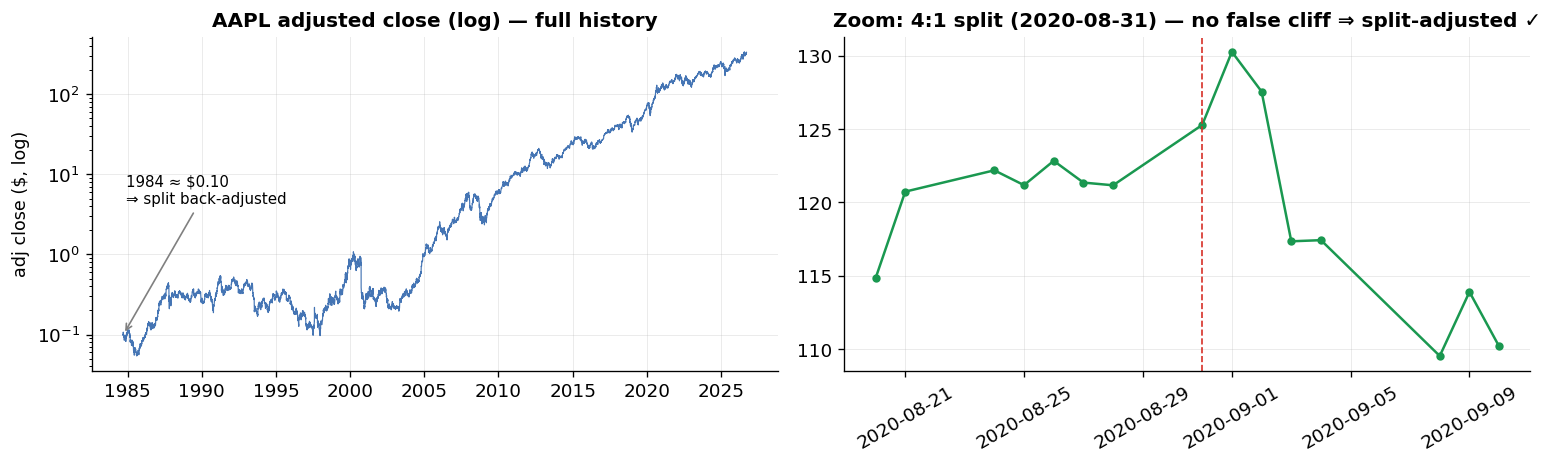

Split check: the close is continuous across the 2020 4:1 split. Dividend treatment and open-vs-close
adjustment are not established by this check (see §3.3 and the OHLC-range check in §8.3).


In [3]:
# Load the RAW panel and show one stock's observations + the adjustment check
raw = pd.read_parquet(f"{DRIVE}/panel.parquet").sort_values(["ticker","date"])
print("One observation (AAPL, first rows):")
display(raw[raw.ticker=="AAPL"].head(3)[["ticker","date","open","high","low","close","vol"]])

# Adjustment verification plot: AAPL full history (log) + zoom on the 2020 4:1 split
aapl = raw[raw.ticker=="AAPL"].copy()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(aapl.date, aapl.close, lw=0.7, color=C_NEU)
ax[0].set_yscale("log"); ax[0].set_title("AAPL adjusted close (log) — full history")
ax[0].set_ylabel("adj close ($, log)")
ax[0].annotate("1984 ≈ $0.10\n⇒ split back-adjusted", xy=(aapl.date.iloc[10], 0.1),
               xytext=(0.05,0.5), textcoords="axes fraction", fontsize=9,
               arrowprops=dict(arrowstyle="->", color="gray"))
win = aapl[(aapl.date>="2020-08-20") & (aapl.date<="2020-09-10")]
ax[1].plot(win.date, win.close, marker="o", ms=4, color=C_GOOD)
ax[1].axvline(pd.Timestamp("2020-08-31"), color=C_BAD, ls="--", lw=1)
ax[1].set_title("Zoom: 4:1 split (2020-08-31) — no false cliff ⇒ split-adjusted ✓")
ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()
print("Split check: the close is continuous across the 2020 4:1 split. Dividend treatment and open-vs-close")
print("adjustment are not established by this check (see §3.3 and the OHLC-range check in §8.3).")

### 2.2 Vendor-observed cross-section, history length, and sample start

The full raw panel has about **20.6M rows, ~9,500 tickers, 1962–2026**, but the count of tickers observed by the vendor is
**not the same thing as the number of US-listed operating companies**. The sharp jump around 2005 and the long climb
thereafter can reflect vendor backfill/history availability, survivor composition, ETFs/other security types, and actual
listing changes. Therefore the plot below is used for one narrow purpose: it shows when the vendor-observed cross-section
is deep enough to construct a ~1,000-name liquid universe. It must **not** be interpreted as a clean market-listing curve.

Raw panel: 20,609,355 rows | 9,530 tickers | 1962-01-02 → 2026-09-18


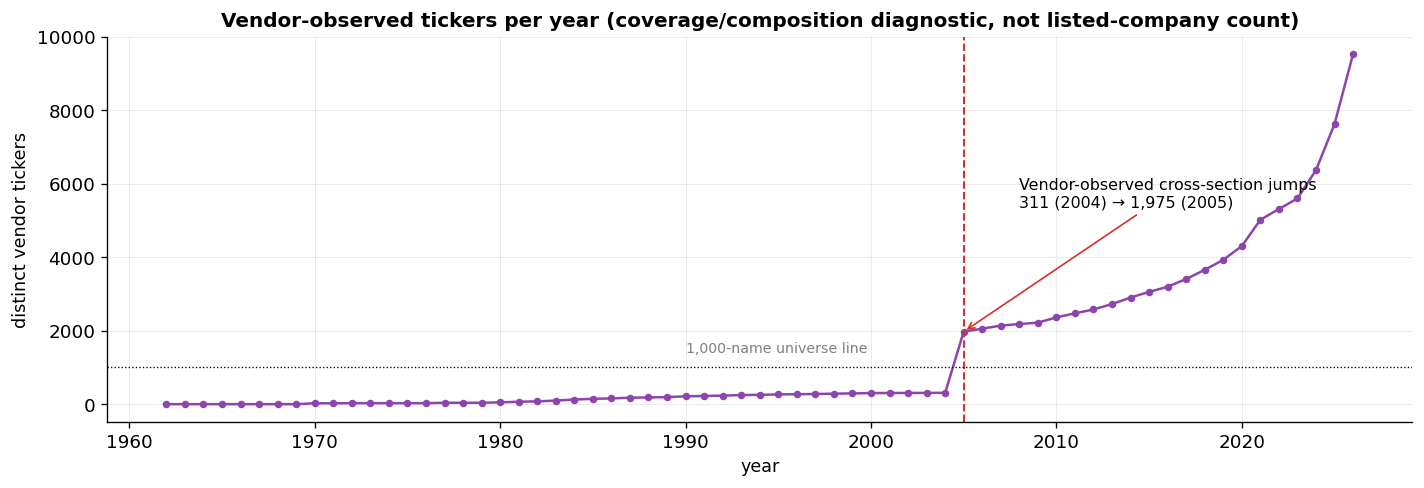

DECISION: start 2005 because the vendor-observed cross-section is then deep enough for a top-1000 construction.
§3.4a separately measures eligible-name depth and the ADV of the 1,000th-ranked name through time.


In [4]:
raw["year"] = raw.date.dt.year
names_yr = raw.groupby("year")["ticker"].nunique()
print(f"Raw panel: {len(raw):,} rows | {raw.ticker.nunique():,} tickers | "
      f"{raw.date.min().date()} → {raw.date.max().date()}")

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(names_yr.index, names_yr.values, marker="o", ms=3.5, color="#8e44ad")
ax.axvline(2005, color=C_BAD, ls="--", lw=1.2)
ax.axhline(1000, color="k", ls=":", lw=0.8)
_n04, _n05 = int(names_yr.get(2004, 0)), int(names_yr.get(2005, 0))
ax.annotate(f"Vendor-observed cross-section jumps\n{_n04:,} (2004) → {_n05:,} (2005)",
            xy=(2005, _n05), xytext=(2008, _n05 + 0.45*(names_yr.max() - _n05)), fontsize=9.5,
            arrowprops=dict(arrowstyle="->", color=C_BAD))
ax.annotate("1,000-name universe line", xy=(1990, 1000), xytext=(1990,1400), fontsize=8.5, color="gray")
ax.set_title("Vendor-observed tickers per year (coverage/composition diagnostic, not listed-company count)")
ax.set_xlabel("year"); ax.set_ylabel("distinct vendor tickers")
plt.tight_layout(); plt.show()
print("DECISION: start 2005 because the vendor-observed cross-section is then deep enough for a top-1000 construction.")
print("WARNING: the curve is not a market-listing curve; the jump/climb can reflect survivorship, backfill and security-type mix.")
print("§3.4a separately measures eligible-name depth and the ADV of the 1,000th-ranked name through time.")

RESULTS.update(raw_rows_m=len(raw)/1e6, raw_tickers=int(raw.ticker.nunique()), names_2004=_n04, names_2005=_n05)


### 2.2a Source provenance and security type

This notebook starts from a prebuilt `panel.parquet`; the original Stooq download/folder manifest is **not embedded here**.
That means the notebook cannot infer from OHLCV alone whether every symbol is an operating-company common stock, ETF,
ETN, closed-end fund, preferred, or another listed instrument. §3.4a therefore runs two explicit checks: (i) a hardcoded
sanity list of highly liquid ETFs, and (ii) a **diagnostic-only** comparison to the current Nasdaq Trader ETF flags when
internet access is available. A current security master is not historically point-in-time, so it is not silently used to
rewrite the primary historical universe. A production rebuild should use a historical security master or documented
stock-only source folders.

### 2.3 When is a row available, relative to the event?

These are **end-of-day (EOD) bars**: a day-`T` row is finalized after that day's close. Two consequences shape the design:

- **The tradeable convention is a one-day skip.** You cannot trade on a close you have not yet seen. So we form the signal
  from information through day `T−1` and trade at the close of day `T` to earn the `T`→`T+1` return. This one-day skip is a
  deliberate design choice, and we test its effect explicitly with a **0-, 1-, and 2-day skip** (Section 4.4) — which
  also measures how much of the reversal IC sits in the untradeable day-`T` return.
- **Label shuffle is only a sanity check.** Shuffling next-day returns within each date should produce IC ≈ 0 almost
  regardless of how the features were built. It can catch a broken IC implementation, but it **cannot rule out lookahead**.
  The actual timing-leak checks are the adjacent-session target construction and the explicit 0/1/2-day skip test.

Contrast with the source we rejected — FINRA short interest — which is bi-monthly on an ~8-day publication lag,
structurally mismatched to a daily target. OHLCV's zero-lag, full-cross-section availability is why it fits this problem.


### 2.4 Where is coverage weakest? (Quality issues, previewed)

Coverage degrades exactly where it matters for historical cross-sectional research. The liquid-universe restriction
helps with some problems, but it does **not** magically repair the source.

| Weakest coverage / quality | Why it matters | Treatment here |
|---|---|---|
| **Delisted / dead names** | A vendor may omit or incompletely represent historical failures, creating survivorship bias | **Unresolved.** Point-in-time selection is performed only within names present in the feed; §3.5 measures an *observed vendor exit fraction*, not the true delisting rate. |
| **Small-caps, recent IPOs** | Thin history, gaps, wider spreads | Largely reduced by the top-1,000 liquidity screen; missing history is never imputed. |
| **Warrants / units / rights** | They are not common equities and can have very different return dynamics | A 5+ character suffix heuristic removes many derivative-like symbols. This is explicitly treated as a heuristic, not a security master. |
| **Reverse splits / bad prints** | Can create impossible-looking one-day returns and contaminate both features and targets | Suspicious observations/return pairs are invalidated while preserving the date timeline. |
| **Corporate-action adjustment conventions** | Especially important for close→open decomposition | Split consistency is spot-checked; dividend/open-vs-close conventions remain vendor-level uncertainty. |

The central caveat is therefore simple: **survivorship and identifier quality can bias the level of every historical
result, and the current feed cannot tell us its magnitude.** §3.5 argues the likely direction for each leg.


### 2.5 Statistical shape of the target (one plot that frames everything)

Before cleaning, look at the distribution of daily **cross-sectional excess returns** (each stock's return minus the
universe mean that day) — this is literally what we are trying to predict. It is extremely **fat-tailed and
non-normal**, which directly dictates a downstream feature-engineering choice (rank-transform, not z-score).


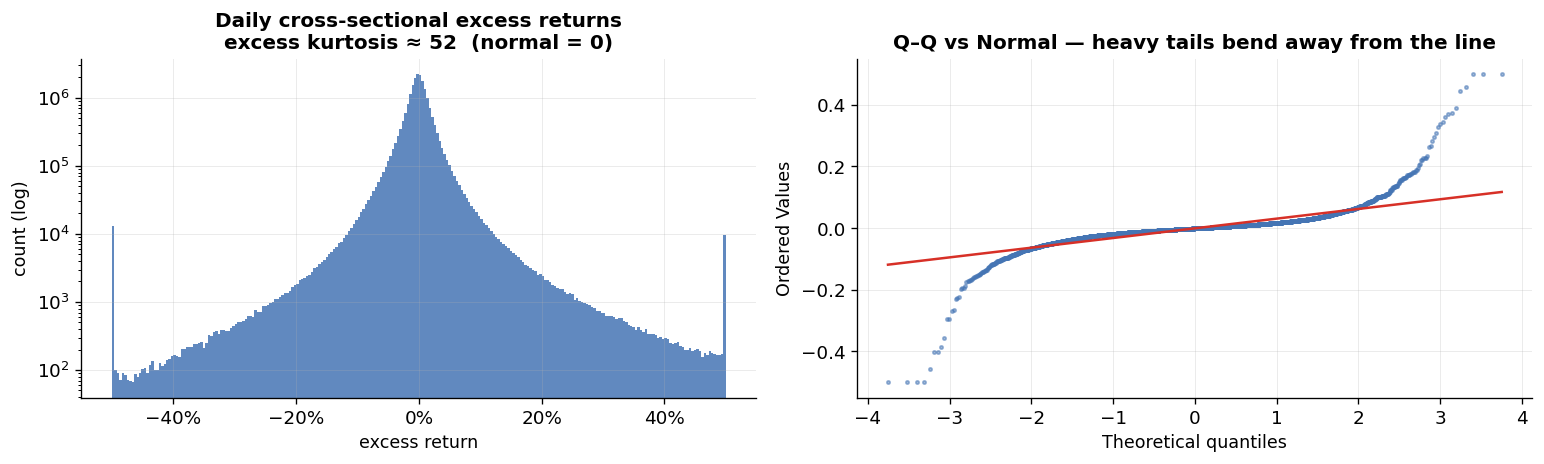

KEY TAKEAWAY: returns are NOT Gaussian. Excess kurtosis ≈ 52 (pre-clean, clipped at ±50% for display)
means extreme cross-sectional moves are far more common than a normal model assumes. ⇒ We will RANK-transform
signals (robust to tails), not z-score (which lets a few extreme names dominate). Justified in Section 4.


In [5]:
# Cross-sectional excess return distribution on the RAW (pre-clean, finite) data
tmp = raw.copy()
tmp["ret"] = tmp.groupby("ticker")["close"].pct_change()
tmp = tmp.replace([np.inf,-np.inf], np.nan)
tmp["mkt"] = tmp.groupby("date")["ret"].transform("mean")
xs = (tmp["ret"] - tmp["mkt"]).dropna()
xs = xs.clip(-0.5, 0.5)  # for display only

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(xs, bins=250, color=C_NEU, alpha=0.85)
ax[0].set_yscale("log")
ax[0].set_title(f"Daily cross-sectional excess returns\nexcess kurtosis ≈ {stats.kurtosis(xs):.0f}  (normal = 0)")
ax[0].set_xlabel("excess return"); ax[0].set_ylabel("count (log)")
ax[0].xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
# QQ-plot vs normal
from scipy.stats import probplot
probplot(xs.sample(8000, random_state=1), dist="norm", plot=ax[1])
ax[1].set_title("Q–Q vs Normal — heavy tails bend away from the line")
ax[1].get_lines()[0].set(marker="o", ms=2, color=C_NEU, alpha=0.5)
ax[1].get_lines()[1].set(color=C_BAD, lw=1.5)
plt.tight_layout(); plt.show()
kurt = stats.kurtosis(xs)
print(f"KEY TAKEAWAY: returns are NOT Gaussian. Excess kurtosis ≈ {kurt:.0f} (pre-clean, clipped at ±50% for display)")
print("means extreme cross-sectional moves are far more common than a normal model assumes. ⇒ We will RANK-transform")
print("signals (robust to tails), not z-score (which lets a few extreme names dominate). Justified in Section 4.")

---
# 3. Data cleaning & audit
### *Every issue found, quantified, fixed — plus data-quality checks specific to the Stooq feed*

**Architecture principle:** cleaning must not delete rows from the middle of a price series before returns and rolling
features are computed (that turns a multi-day gap into a fake one-day return). So filters become **point-in-time
eligibility flags**, not row deletions:

> continuous history → returns → rolling/lagged features → next-trading-day target → eligibility flag → ranks → research.


### 3.1 Diagnose the extreme returns that contaminate the target

Unclipping returns for P&L (correct) exposes rows the price-level glitch filter misses: **reverse splits** and **bad
prints** create huge one-day *returns*. We list the largest moves first, then filter symmetrically (below *and* above the
rolling median) and with a return-based rule.


In [6]:
raw = pd.read_parquet(f"{DRIVE}/panel.parquet").sort_values(["ticker","date"]).copy()
raw["date"] = pd.to_datetime(raw["date"])

# "One-day" means the immediately following market session, not merely the
# next observed row for that ticker.
prev_map, _ = make_market_date_maps(raw["date"])
adj_prev = prev_adjacent_mask(raw, prev_map)
prev_close = raw.groupby("ticker", sort=False)["close"].shift(1)
raw["ret_raw"] = (raw["close"] / prev_close - 1).where(adj_prev)

tmp = raw.replace([np.inf,-np.inf], np.nan).dropna(subset=["ret_raw"])
print("=== TOP 20 largest adjacent-session returns in RAW data (target contamination) ===")
top = tmp.nlargest(20,"ret_raw")[["ticker","date","close","ret_raw"]].copy()
top["prev_close"] = prev_close.reindex(top.index)
print(top.to_string(index=False))
print("\n=== BOTTOM 10 (largest negative adjacent-session returns) ===")
print(tmp.nsmallest(10,"ret_raw")[["ticker","date","close","ret_raw"]].to_string(index=False))
print(f"\nCounts: >+300% one-day moves = {(tmp['ret_raw']>3).sum():,} ; "
      f">+900% = {(tmp['ret_raw']>9).sum():,} ; <-90% = {(tmp['ret_raw']<-0.9).sum():,}")

RESULTS["top20_moves_jul_sep_2026"] = int((top["date"] >= "2026-07-01").sum())


=== TOP 20 largest adjacent-session returns in RAW data (target contamination) ===
ticker       date       close     ret_raw  prev_close
 ZVZZT 2023-11-08 127191.8000 3643.464183     34.9000
 ZVZZT 2024-02-07 199999.9900 3130.360420     63.8700
  LGCL 2026-09-01      4.3500  122.931624      0.0351
   FGL 2026-09-01     17.2300  112.355263      0.1520
  BRKH 2026-09-03     10.0000   95.618357      0.1035
  GOSS 2026-09-11     10.7300   74.351124      0.1424
  BRKH 2026-08-25     10.0000   73.074074      0.1350
 ZVZZT 2023-05-09    683.6100   52.574451     12.7600
   ALP 2026-09-09      5.4141   49.270195      0.1077
   OMH 2026-08-31      3.2400   45.285714      0.0700
  LIMN 2026-08-21      5.1600   44.825933      0.1126
  SMTK 2026-08-21      4.4100   42.024390      0.1025
  GRML 2026-08-24      8.5500   41.180562      0.2027
  TPST 2023-10-11    127.0100   39.725302      3.1187
  BURU 2026-09-02      1.4500   39.277778      0.0360
  BRKH 2026-07-14      9.9500   37.269231      0.2600

### 3.2 Rebuild the clean panel — preserve the timeline, invalidate bad observations

The key rule is **never delete an interior date and then let `pct_change()` bridge the gap**. That would turn a multi-day
move into a fake one-day return. We therefore:

1. Drop only **entire securities** that are clearly exchange-test / derivative-like / known-corrupt symbols.
2. Keep the remaining date rows in place and mark suspicious **observations** with a `bad_obs` flag.
3. Compute a return only when the current and previous observations are valid **and** their dates are adjacent market
   sessions.
4. Null suspicious return-level events rather than compressing the time axis.
5. Maintain two return columns: `ret_actual` for the target/P&L and `ret_feature` (winsorized) for robust feature
   construction.

The `|return| > 150%` rule is deliberately labeled a **conservative data-quality heuristic**, not an economic statement:
a genuine stock can move more than 150% in a day. In a production dataset we would verify those events against a second
vendor / corporate-action master instead of classifying them from OHLCV alone.


In [7]:
n0 = len(raw)
raw = raw.drop_duplicates(subset=["ticker","date"], keep="first").sort_values(["ticker","date"]).copy()
raw["date"] = pd.to_datetime(raw["date"])
tkr = raw["ticker"].astype(str)

# (1) remove WHOLE securities only: exchange-test + known-corrupt + heuristic derivative suffixes
is_test = tkr.str.match(r"^Z[A-Z]ZZT$") | tkr.isin(["XTIA","TOVX"])
is_warr = (tkr.str.len()>=5) & tkr.str.match(r"^[A-Z]{4,}(W|WS)$")
is_unit = (tkr.str.len()>=5) & tkr.str.match(r"^[A-Z]{4,}U$")
is_rght = (tkr.str.len()>=5) & tkr.str.match(r"^[A-Z]{4,}(R|RT)$")
drop_security = is_warr | is_unit | is_rght | is_test
removed = sorted(raw.loc[drop_security, "ticker"].unique())
print(f"Whole-security filter removes {len(removed)} tickers "
      f"({100*len(removed)/raw['ticker'].nunique():.1f}% of all). Sample: {removed[:30]}")
raw = raw.loc[~drop_security].copy()

# Market calendar used to distinguish an adjacent session from the next observed ticker row.
prev_map, next_map = make_market_date_maps(raw["date"])
adj_prev = prev_adjacent_mask(raw, prev_map)
adj_next = next_adjacent_mask(raw, next_map)

# (2) flag suspicious PRICE OBSERVATIONS; do not delete their rows.
abs_bad = (~np.isfinite(raw["close"])) | (raw["close"] <= 0.10) | (raw["close"] >= 100000)
raw["pmed"] = raw.groupby("ticker", sort=False)["close"].transform(
    lambda s: s.rolling(60, min_periods=20).median()
)
roll_bad = (
    ((raw["close"] > 10*raw["pmed"]) | (raw["close"] < raw["pmed"]/10))
    & raw["pmed"].notna()
)
raw["bad_obs"] = (abs_bad | roll_bad).fillna(True)
print(f"Flagged price observations: absolute={int(abs_bad.sum()):,}, rolling-median={int(roll_bad.sum()):,}")

# (3) adjacent-session raw return only when BOTH endpoint observations are valid.
prev_close = raw.groupby("ticker", sort=False)["close"].shift(1)
prev_bad = raw.groupby("ticker", sort=False)["bad_obs"].shift(1).fillna(True).astype(bool)
ret_raw = raw["close"] / prev_close - 1
ret_raw = ret_raw.where(adj_prev & ~raw["bad_obs"] & ~prev_bad)
ret_raw = ret_raw.replace([np.inf,-np.inf], np.nan)
raw["ret_raw_adj"] = ret_raw

# Split-like price ratios that can slip through a generic |return| rule: 2-for-1, 3-for-1, 4-for-1 and inverses.
# This is a DIAGNOSTIC FLAG, not an automatic deletion: genuine news moves can land near a round ratio.
ratio = (1.0 + ret_raw).where((1.0 + ret_raw) > 0)
canonical_ratios = np.array([0.25, 1/3, 0.50, 2.0, 3.0, 4.0], dtype=float)
dist_to_split = pd.concat(
    [((ratio / q) - 1).abs().rename(str(q)) for q in canonical_ratios], axis=1
).min(axis=1)
raw["split_like"] = ret_raw.notna() & (dist_to_split <= 0.01)   # within 1% of a canonical split ratio

# (4) return-level data heuristics. For a sharp move immediately reversed next session,
# null BOTH legs of the suspicious pair.
next_ret = ret_raw.groupby(raw["ticker"], sort=False).shift(-1)
pair_start = (
    adj_next
    & (((ret_raw > 1.0) & (next_ret < -0.4)) | ((ret_raw < -0.5) & (next_ret > 1.0)))
)
pair_end = pair_start.groupby(raw["ticker"], sort=False).shift(1).fillna(False).astype(bool)
extreme = ret_raw.abs() > 1.5   # conservative data-quality heuristic; see markdown above
bad_return = pair_start | pair_end | extreme

raw["ret_actual"] = ret_raw.mask(bad_return)
raw["ret_feature"] = raw["ret_actual"].clip(-0.5, 0.5)  # features only; target/P&L stays unclipped
raw = raw.drop(columns=["pmed"])
save_stage(raw, "panel_continuous")

chk = raw["ret_actual"].dropna()
print(f"\nContinuous panel retained: {len(raw):,} rows ({n0:,} raw before whole-security filtering), "
      f"{raw['ticker'].nunique():,} tickers.")
print(f"Return heuristics nulled: bad-pair legs={int((pair_start|pair_end).sum()):,}, "
      f"|ret|>150%={int(extreme.sum()):,}.")
print(f"Canonical split-like adjacent returns flagged for audit (NOT auto-deleted): {int(raw['split_like'].sum()):,}.")
print(f"Post-clean ret_actual: kurtosis={stats.kurtosis(chk):.1f}, skew={stats.skew(chk):+.2f}, "
      f"max={chk.max():.2f}, min={chk.min():.2f}")


Whole-security filter removes 676 tickers (7.1% of all). Sample: ['AACBR', 'AACBU', 'AACIU', 'AACIW', 'AACOU', 'AACOW', 'AACPR', 'AACPU', 'AACPW', 'ABLVW', 'ACAAU', 'ACAAW', 'ACGCU', 'ACGCW', 'ACONW', 'ADACU', 'ADACW', 'ADSEW', 'AEAQU', 'AEAQW', 'AENTW', 'AERTW', 'AESPR', 'AESPU', 'AESPW', 'AFJKR', 'AFJKU', 'AFRIW', 'AIIOW', 'AIRJW']
Flagged price observations: absolute=136,303, rolling-median=4,482
[save_stage] panel_continuous: 20,385,519 rows, 13 columns → /content/drive/MyDrive/NYSE stocks data/trexquant_ohlcv_v11_faculty_review/panel_continuous.parquet

Continuous panel retained: 20,385,519 rows (20,609,355 raw before whole-security filtering), 8,854 tickers.
Return heuristics nulled: bad-pair legs=468, |ret|>150%=823.
Canonical split-like adjacent returns flagged for audit (NOT auto-deleted): 349.
Post-clean ret_actual: kurtosis=103.8, skew=+3.22, max=1.50, min=-0.95


### 3.3 Stooq data-quality checks (turning caveats into tests)

Depth on one source means knowing what was actually verified. We run source-internal diagnostics, while refusing to
promote them into a vendor specification they cannot establish:

1. **Split consistency / volume behavior.** Inspect AAPL around the 2020 4:1 split. A short-window volume ratio is
   descriptive only; trading activity itself changes, so it does not by itself prove the vendor's volume-adjustment rule.
2. **Reverse-split / bad-print candidates.** Inspect extreme moves as a contamination diagnostic.
3. **Ticker identity sanity check (FB / META).** Use the histories to demonstrate why ticker strings are not stable
   security identifiers and why a production security master is preferable.
4. **Unresolved vendor convention.** OHLCV alone does not independently prove dividend treatment or identical
   open/close adjustment around every corporate action. That uncertainty matters most for the overnight decomposition.


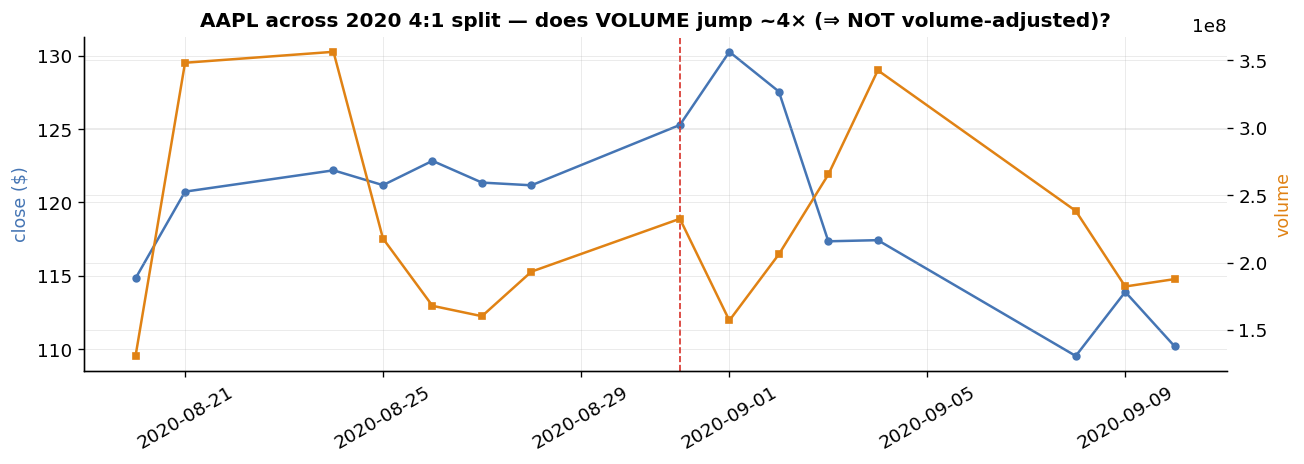

AAPL median volume pre-split 193,260,092 vs post 219,299,618 (ratio 1.13).
  Descriptive only: a short-window volume ratio does NOT by itself identify the vendor's general adjustment rule.

Candidate reverse-split / huge-up rows (>+90% in a day): 2,436
ticker       date   close        ret
  SNYR 2021-12-31  0.0100        inf
  LGCL 2026-09-01  4.3500 122.931624
   FGL 2026-09-01 17.2300 112.355263
  BRKH 2026-09-03 10.0000  95.618357
  GOSS 2026-09-11 10.7300  74.351124
  BRKH 2026-08-25 10.0000  73.074074
   ALP 2026-09-09  5.4141  49.270195
   OMH 2026-08-31  3.2400  45.285714
  FB: 44 rows, 2026-07-01 → 2026-09-18
  META: 3,604 rows, 2012-05-18 → 2026-09-18

Feed-calendar holes since 2005 (under half the usual tickers, or under half with a valid one-day return): 8 date(s)
            tickers  valid_ret_share  typical_tickers
date                                                 
2011-02-17      528            0.966           2337.0
2011-02-18     2343            0.218           2338.

In [8]:
cont = load_stage("panel_continuous")

# (1) volume adjustment check on AAPL 2020 split
aapl = cont[cont["ticker"]=="AAPL"].copy()
win = aapl[(aapl["date"]>="2020-08-20")&(aapl["date"]<="2020-09-10")]
fig, ax1 = plt.subplots(figsize=(11,4))
ax1.plot(win["date"],win["close"],marker="o",ms=4,color=C_NEU,label="close (adj)")
ax1.set_ylabel("close ($)",color=C_NEU); ax1.axvline(pd.Timestamp("2020-08-31"),color=C_BAD,ls="--",lw=1)
ax2=ax1.twinx(); ax2.plot(win["date"],win["vol"],marker="s",ms=4,color="#e08214",label="volume")
ax2.set_ylabel("volume",color="#e08214")
ax1.set_title("AAPL across 2020 4:1 split — does VOLUME jump ~4× (⇒ NOT volume-adjusted)?")
ax1.tick_params(axis="x",rotation=30)
plt.tight_layout(); plt.show()
vpre=win[win["date"]<"2020-08-31"]["vol"].median(); vpost=win[win["date"]>="2020-08-31"]["vol"].median()
print(f"AAPL median volume pre-split {vpre:,.0f} vs post {vpost:,.0f} (ratio {vpost/vpre:.2f}).")
print("  Descriptive only: a short-window volume ratio does NOT by itself identify the vendor's general adjustment rule.")

# (2) reverse-split scan: big UP one-day move ~ a clean ratio (1:2, 1:5, 1:10 reverse)
cont["ret"]=cont.groupby("ticker")["close"].pct_change()
rev_splits = cont[(cont["ret"]>0.9)].dropna(subset=["ret"])
print(f"\nCandidate reverse-split / huge-up rows (>+90% in a day): {len(rev_splits):,}")
print(rev_splits.nlargest(8,"ret")[["ticker","date","close","ret"]].to_string(index=False))

# (3) FB / META continuity
for t in ["FB","META"]:
    s=cont[cont["ticker"]==t]
    if len(s): print(f"  {t}: {len(s):,} rows, {s['date'].min().date()} → {s['date'].max().date()}")
    else: print(f"  {t}: NOT in data")

# (4) Feed calendar. The market calendar used for adjacency is the set of dates in the feed, so a date on which most
# tickers are missing or unusable voids the one-day return across it for every ticker that is missing.
_c = cont.loc[cont["date"] >= "2005-01-01", ["ticker", "date", "ret_actual"]]
_not_first = _c.groupby("ticker", sort=False).cumcount() > 0          # a ticker's first row never has a return
per_day = pd.DataFrame({
    "tickers": _c.groupby("date")["ticker"].size(),
    "valid_ret_share": _c.loc[_not_first, "ret_actual"].notna().groupby(_c.loc[_not_first, "date"]).mean(),
})
per_day["typical_tickers"] = per_day["tickers"].rolling(21, center=True, min_periods=5).median()
holes = per_day[(per_day["tickers"] < 0.5 * per_day["typical_tickers"]) | (per_day["valid_ret_share"] < 0.5)]
print(f"\nFeed-calendar holes since 2005 (under half the usual tickers, or under half with a valid one-day return): "
      f"{len(holes)} date(s)")
if len(holes):
    print(holes.round({"valid_ret_share": 3, "typical_tickers": 0}).to_string())
del _c, _not_first

RESULTS["aapl_split_volume_ratio"] = float(vpost / vpre)
RESULTS["feed_calendar_holes"] = int(len(holes))


**What these Stooq checks actually support.**

- **AAPL split check:** the close series is visually continuous around the 2020 split. The short-window median-volume ratio
  in the check above is about **1.13×**, but that is not enough to infer a general volume-adjustment convention because
  trading activity changes endogenously around splits.
- **Dividend/open adjustment remains unverified.** A split sanity check does not establish dividend treatment or prove
  that every open and close has identical adjustment handling. This is especially relevant for close→open returns.
- **Extreme-return contamination is real.** The raw feed contains implausibly large moves and low-priced instrument noise.
  The cleaning pipeline therefore preserves the time axis and invalidates suspect endpoints/returns rather than deleting
  an interior date and letting `pct_change()` bridge it.
- **FB/META illustrates identifier risk, not clean rename continuity.** In this feed, `META` carries history back
  to 2012 while an `FB` symbol also appears separately in 2026. That is exactly why ticker text alone cannot be treated as
  a permanent security identifier.
- **Recent data looks unrevised.** 14 of the 20 largest raw one-day moves in §3.1 are dated July–September 2026, the
  last weeks of the feed. The likely cause is revision lag: recent reverse splits not yet back-adjusted. All of them
  exceed the |return| > 150% rule and are nulled.
- **Suffix filter remains a heuristic.** The 5+ character `W/U/R/RT` rules catch many derivative-like symbols but can
  still create false positives/negatives. The correct production fix is security-type metadata and stable identifiers.
- **The feed's calendar has holes.** The market calendar here is the set of dates in the feed, so on a date where most
  tickers are missing or unusable, every affected ticker's one-day return across it is voided. The check above finds four
  holes since 2005 (each appears twice: the thin date and the session after it). Three are 2026 US market holidays
  (Memorial Day on May 25, Juneteenth on June 19, and the July 3 Independence Day holiday) on which two or three tickers
  carry stray rows. The fourth, 2011-02-17, is a real session on which only 528 of about 2,300 tickers print. They cost a
  few days of data rather than add bias, but §9 skips the dates before them because the data has no next session to
  trade into. An exchange calendar would remove all four.


### 3.4 Point-in-time eligibility flags + trailing stale filter

In [9]:
raw = load_stage("panel_continuous").sort_values(["ticker","date"]).copy()
raw["date"] = pd.to_datetime(raw["date"])
prev_map, _ = make_market_date_maps(raw["date"])
adj_prev = prev_adjacent_mask(raw, prev_map)

prev_close = raw.groupby("ticker", sort=False)["close"].shift(1)
raw["flat"] = ((raw["close"] == prev_close) & adj_prev & ~raw["bad_obs"]).astype(float)
raw.loc[~adj_prev | raw["bad_obs"], "flat"] = np.nan
raw["stale60"] = raw.groupby("ticker", sort=False)["flat"].transform(
    lambda s: s.rolling(60, min_periods=40).mean().shift(1)
)

raw["elig"] = (
    (raw["close"] >= 1.0)
    & (raw["vol"] > 0)
    & (raw["close"] > 0)
    & (~raw["bad_obs"])
    & raw["ret_actual"].notna()
    & ((raw["stale60"] < 0.30) | raw["stale60"].isna())
    & (raw["date"] >= "2005-01-01")
    & (raw["date"] <= "2026-09-18")
)

raw["dollar_vol"] = (raw["close"] * raw["vol"]).where(~raw["bad_obs"])
raw["adv60"] = raw.groupby("ticker", sort=False)["dollar_vol"].transform(
    lambda s: s.rolling(60, min_periods=40).median().shift(1)
)
raw["liq_rank"] = raw.loc[raw["elig"]].groupby("date")["adv60"].rank(
    ascending=False, method="first"
)
raw["in_universe"] = raw["elig"] & (raw["liq_rank"] <= 1000)

dc = raw.loc[raw["in_universe"]].groupby("date")["ticker"].count()
raw.loc[raw["date"].isin(dc[dc < 100].index), "in_universe"] = False

save_stage(raw, "panel_clean")
cnt = raw.loc[raw["in_universe"]].groupby("date")["ticker"].count()
print(f"Saved panel_clean.parquet. Universe/day mean {cnt.mean():.0f}, min {cnt.min()}, max {cnt.max()}.")
print(f"Eligible rows: {raw['elig'].mean()*100:.1f}%.")


[save_stage] panel_clean: 20,385,519 rows, 20 columns → /content/drive/MyDrive/NYSE stocks data/trexquant_ohlcv_v11_faculty_review/panel_clean.parquet
Saved panel_clean.parquet. Universe/day mean 990, min 302, max 1000.
Eligible rows: 90.2%.


### 3.4a Universe-composition audit: ETFs, time-varying top-1,000 depth, and split-like events

Three questions can materially change the interpretation even if the signal code is perfect:

1. **Are ETFs/ETNs in the intended equity universe?** OHLCV alone cannot identify security type. The cell checks obvious
   liquid ETFs and, when available, the current Nasdaq Trader ETF flags. The current directory is **diagnostic only**,
   because applying today's classification historically would itself create a point-in-time problem.
2. **How deep is “top 1,000” in each era?** We report the eligible-name count, fraction selected, and the trailing-ADV of
   the 1,000th-ranked name by year. This is the right context for comparing early and recent IC.
3. **Do canonical split ratios remain inside the in-universe data?** We report the flagged position dates by month and
   carry a split-clean sensitivity into §8 rather than automatically declaring every round-ratio move bad data.

Obvious ETF sanity tickers present anywhere in panel: none
Obvious-ETF in-universe position-days: 0 (0.000% of universe rows); unique tickers=0
Current Nasdaq-Trader ETF flags intersect 35 in-universe tickers and 0.216% of historical universe rows (diagnostic only; NOT point-in-time).


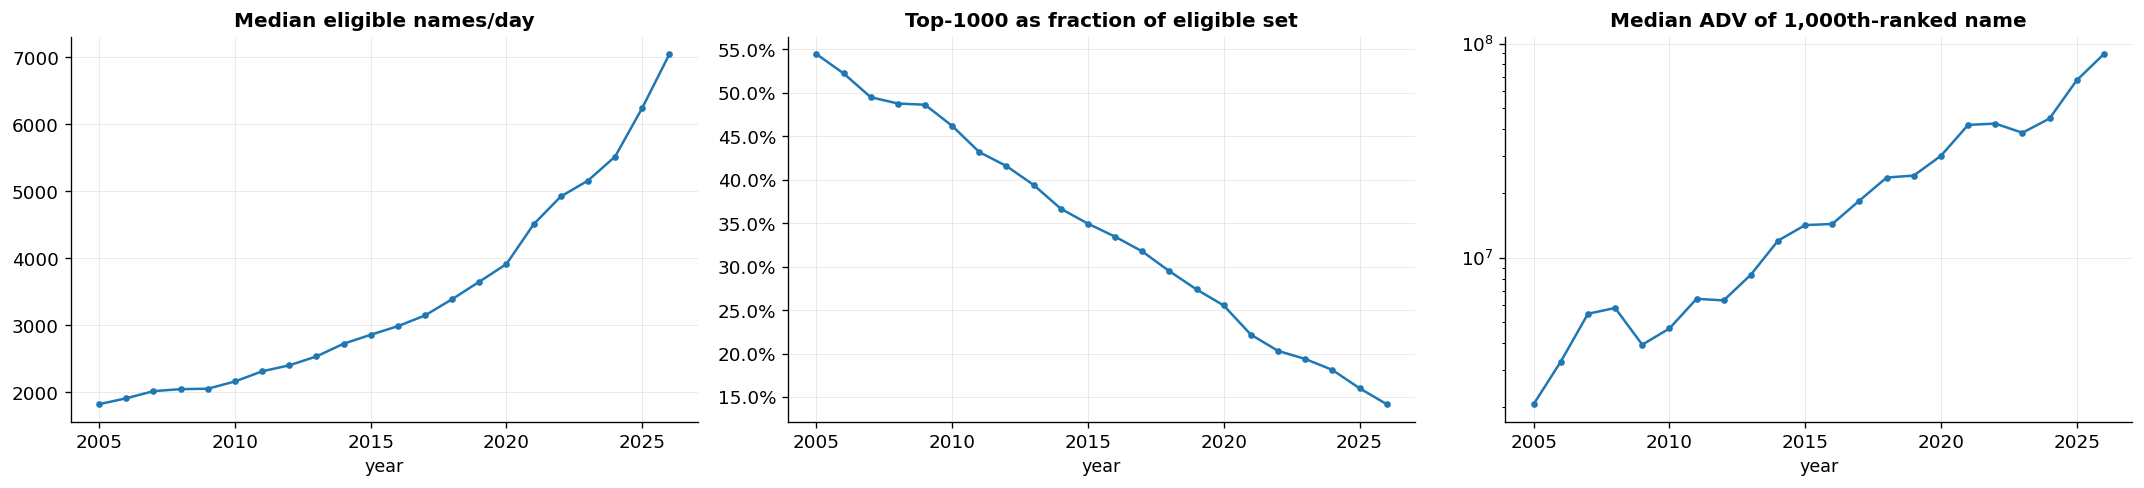

,eligible_names,selected_names,fraction_selected,adv_1000
year,,,,
2017,3149.0,1000.0,0.318,18511870.0
2018,3392.0,1000.0,0.295,23704108.0
2019,3652.0,1000.0,0.274,24215291.0
2020,3916.0,1000.0,0.255,29958194.0
2021,4508.5,1000.0,0.222,41746479.0
2022,4923.0,1000.0,0.203,42357230.0
2023,5159.5,1000.0,0.194,38360210.0
2024,5518.0,1000.0,0.181,44735806.0
2025,6244.0,1000.0,0.160,67466650.0


In-universe canonical split-like adjacent returns: 5 rows across 5 tickers.
Most recent monthly counts:
month
2008-10    1
2014-09    1
2016-10    1
2021-02    1
2026-05    1
Freq: M


,ticker,date,ret_raw_adj,close,adv60
5382334,DIN,2008-10-28,1.019697,12.4173,5.638680e+06
4915216,CVEO,2014-09-29,-0.495878,152.2700,2.053439e+07
5061674,CYH,2016-10-27,-0.496510,5.0500,4.102754e+07
18196277,TLRY,2021-02-11,-0.496792,321.6000,2.590131e+08
15119419,PRIM,2026-05-06,-0.501133,101.2300,1.020205e+08


Depth: the top 1,000 is 54% of eligible names in 2005 and 14% in 2026; the 1,000th name's ADV goes from $2.1M to $89.4M.


In [10]:
# ---- A. ETF / security-type sanity audit ----
OBVIOUS_ETFS = {
    "SPY","QQQ","TQQQ","SQQQ","TLT","IWM","DIA","GLD","SLV","HYG","LQD","EEM","EFA",
    "XLF","XLK","XLE","XLY","XLP","XLI","XLU","XLV","XLB","XLC","XBI","SMH","SOXX",
    "ARKK","VXX","UVXY","SH","PSQ","SDS","SPXU","UPRO","SOXL","SOXS","LABU","LABD",
    "GDX","GDXJ","USO","UNG","KRE","KWEB","FXI","EWJ","VGK","VTI","VOO","IVV","AGG","BND"
}
raw_tickers = set(raw["ticker"].astype(str).unique())
obvious_present = sorted(raw_tickers & OBVIOUS_ETFS)
u = raw.loc[raw["in_universe"]].copy()
obvious_u = u[u["ticker"].isin(OBVIOUS_ETFS)]
print("Obvious ETF sanity tickers present anywhere in panel:", obvious_present or "none")
print(f"Obvious-ETF in-universe position-days: {len(obvious_u):,} "
      f"({len(obvious_u)/max(len(u),1):.3%} of universe rows); unique tickers={obvious_u['ticker'].nunique()}")
if len(obvious_u):
    display(obvious_u.groupby("ticker").agg(days=("date","size"), median_adv=("adv60","median")).sort_values("median_adv",ascending=False).head(30))
    print("WARNING: the intended 'equity' universe contains obvious ETF symbols. Primary results require a stock-only rebuild or a security-master filter.")

# Optional CURRENT security-master diagnostic from Nasdaq Trader. Do not use it as a historical primary filter.
CURRENT_ETF_TICKERS = set()
try:
    nq = pd.read_csv("https://www.nasdaqtrader.com/dynamic/SymDir/nasdaqlisted.txt", sep="|")
    ot = pd.read_csv("https://www.nasdaqtrader.com/dynamic/SymDir/otherlisted.txt", sep="|")
    if {"Symbol","ETF"}.issubset(nq.columns):
        CURRENT_ETF_TICKERS |= set(nq.loc[nq["ETF"].eq("Y"), "Symbol"].dropna().astype(str))
    if {"ACT Symbol","ETF"}.issubset(ot.columns):
        CURRENT_ETF_TICKERS |= set(ot.loc[ot["ETF"].eq("Y"), "ACT Symbol"].dropna().astype(str))
    pd.Series(sorted(CURRENT_ETF_TICKERS), name="ticker").to_csv(f"{OUT}/current_etf_audit_tickers.csv", index=False)
    cur_u = u[u["ticker"].isin(CURRENT_ETF_TICKERS)]
    print(f"Current Nasdaq-Trader ETF flags intersect {cur_u['ticker'].nunique()} in-universe tickers and "
          f"{len(cur_u)/max(len(u),1):.3%} of historical universe rows (diagnostic only; NOT point-in-time).")
except Exception as e:
    print("Current ETF-directory diagnostic unavailable:", type(e).__name__, str(e)[:180])

# ---- B. How deep is top-1000 through time? ----
daily_depth = pd.DataFrame({
    "eligible_n": raw.loc[raw["elig"]].groupby("date")["ticker"].nunique(),
    "universe_n": raw.loc[raw["in_universe"]].groupby("date")["ticker"].nunique(),
})
r1000 = raw.loc[raw["elig"] & raw["liq_rank"].eq(1000), ["date","adv60"]].dropna().drop_duplicates("date").set_index("date")["adv60"]
daily_depth["adv_1000"] = r1000
daily_depth["fraction_selected"] = daily_depth["universe_n"] / daily_depth["eligible_n"]
annual_depth = daily_depth.assign(year=daily_depth.index.year).groupby("year").agg(
    eligible_names=("eligible_n","median"),
    selected_names=("universe_n","median"),
    fraction_selected=("fraction_selected","median"),
    adv_1000=("adv_1000","median"),
)
fig, ax = plt.subplots(1,3,figsize=(18,4.2))
ax[0].plot(annual_depth.index, annual_depth["eligible_names"], marker="o", ms=3); ax[0].set_title("Median eligible names/day")
ax[1].plot(annual_depth.index, annual_depth["fraction_selected"], marker="o", ms=3); ax[1].set_title("Top-1000 as fraction of eligible set"); ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax[2].plot(annual_depth.index, annual_depth["adv_1000"], marker="o", ms=3); ax[2].set_yscale("log"); ax[2].set_title("Median ADV of 1,000th-ranked name")
for a in ax: a.set_xlabel("year")
plt.tight_layout(); plt.show()
display(annual_depth.tail(10).round({"fraction_selected":3,"adv_1000":0}))

# ---- C. Canonical split-like events inside the actual research universe ----
split_u = raw.loc[raw["in_universe"] & raw.get("split_like", False)].copy()
print(f"In-universe canonical split-like adjacent returns: {len(split_u):,} rows across {split_u['ticker'].nunique()} tickers.")
if len(split_u):
    split_u["month"] = split_u["date"].dt.to_period("M")
    by_month = split_u.groupby("month").size()
    print("Most recent monthly counts:")
    print(by_month.tail(24).to_string())
    display(split_u[["ticker","date","ret_raw_adj","close","adv60"]].sort_values("date").tail(40))

# ---- record headline numbers (checked against the text in §11) ----
RESULTS["obvious_etfs_in_panel"] = len(obvious_present)
if CURRENT_ETF_TICKERS:
    _cur = u["ticker"].isin(CURRENT_ETF_TICKERS)
    RESULTS["current_etf_row_share"] = float(_cur.mean())
    RESULTS["current_etf_tickers_in_universe"] = int(u.loc[_cur, "ticker"].nunique())
_y0, _y1 = int(annual_depth.index.min()), int(annual_depth.index.max())
RESULTS.update(
    top1000_frac_first_year=float(annual_depth.loc[_y0, "fraction_selected"]),
    top1000_frac_last_year=float(annual_depth.loc[_y1, "fraction_selected"]),
    adv1000_first_year_musd=float(annual_depth.loc[_y0, "adv_1000"]) / 1e6,
    adv1000_last_year_musd=float(annual_depth.loc[_y1, "adv_1000"]) / 1e6,
    split_like_in_universe=int(len(split_u)),
)
print(f"Depth: the top 1,000 is {RESULTS['top1000_frac_first_year']:.0%} of eligible names in {_y0} and "
      f"{RESULTS['top1000_frac_last_year']:.0%} in {_y1}; the 1,000th name's ADV goes from "
      f"${RESULTS['adv1000_first_year_musd']:.1f}M to ${RESULTS['adv1000_last_year_musd']:.1f}M.")


**What the audit found.**

- **Security type.** None of the obvious ETF tickers is in the panel, and today's Nasdaq Trader ETF flags match 35
  tickers that make up about 0.2% of universe rows. Current flags aren't point-in-time, so this is a diagnostic rather
  than a filter; §8.1 shows the IC without those tickers. ETF contamination is negligible.
- **Universe depth.** The top 1,000 is about 54% of eligible names in 2005 and 14% in 2026, and the 1,000th name's
  trailing ADV rises from about \$2M to about \$89M. Early-sample "liquid" names are far smaller than recent ones, which
  matters for comparing eras (§8.1b) and for trading costs in 2005–08.
- **Split-like moves.** Only 5 in-universe returns sit within 1% of a 2:1, 3:1 or 4:1 ratio in 21 years, and they look
  like real moves (TLRY on 2021-02-11, for example), so they stay in; §8.1 shows the IC with them removed.


### 3.5 Survivorship — quantified only as far as this feed allows

The vendor-observed names-per-year curve is itself a warning: a jump from a few hundred names to nearly two thousand in
one year, followed by a long climb toward ~9,500, is too large to read mechanically as the evolution of operating-company
listings. It can reflect backfill, current-survivor history, ETFs/other security types, and changes in vendor coverage.
That means survivorship/composition bias plausibly has a **time profile**: the early sample may be much more incomplete
than the recent sample.

A point-in-time top-1,000 universe prevents the obvious error of selecting today's winners retrospectively, but it does
**not** restore securities absent from the source. It also reaches a different depth through time: §3.4a shows the top
1,000 covering about half of eligible names early on and 14% at the end, and §8.1b tests what that does to era comparisons.

The source lets us measure only the fraction of ticker histories whose **last vendor observation** occurs well before the
panel end. That is an observed exit fraction, not a true historical delisting rate. A survivor-biased vendor can omit a
failed security entirely, so the feed cannot benchmark its own missing-history problem.

**Likely direction, by leg.** Missing dead stocks may **inflate reversal** because recent losers bought by the strategy are,
in this feed, known survivors. They may **deflate momentum** because shorted past losers can omit their terminal failures.
These are hypotheses to test on a survivorship-safe security master, not corrections applied to the current numbers.

In [11]:
raw2 = pd.read_parquet(f"{DRIVE}/panel.parquet")
last = raw2.groupby("ticker")["date"].max()
end = raw2["date"].max()
exited = int((last < end - pd.Timedelta(days=15)).sum())
active = int((last >= end - pd.Timedelta(days=15)).sum())
rate = 100 * exited / (active + exited)

print(f"Observed vendor exit fraction = {rate:.1f}%.")
print("Do NOT read this as a true delisting rate; missing failed securities may never appear in the feed.")
print("Point-in-time universe construction prevents modern-list leakage within the vendor, but survivorship remains unresolved.")


Observed vendor exit fraction = 2.8%.
Do NOT read this as a true delisting rate; missing failed securities may never appear in the feed.
Point-in-time universe construction prevents modern-list leakage within the vendor, but survivorship remains unresolved.


---
# 4. Feature engineering
### *Full observed history → one number per stock per day; scaling, outliers, missing data*

Time-series features are computed **before** the point-in-time universe filter. The next-day target is stricter still:
`shift(-1)` is accepted only when the shifted row is the **actual next market session**. This prevents a missing ticker
observation from silently turning a multi-day return into a one-day target.

**The two signals**
- **Long-horizon momentum proxy (12–1 style):** rolling **sum of market-demeaned daily simple feature returns** over 231
  sessions, shifted 21 sessions. In calendar language, it uses roughly eleven months of return history ending about one
  month before the forecast date. This is a cumulative simple-return proxy, **not an exact compounded 12–1 total return**.
- **Reversal (composite):** negative mean of rolling 3/5/10-session sums of feature returns, with a one-session skip.
  The three horizons intentionally span roughly half a trading week, one week, and two weeks. They are averaged to avoid
  selecting a single short-horizon decay rate in-sample.

**Timing.** The reversal signal on date `T` uses returns through `T−1`; the target is the adjacent-session close-to-close
return `T→T+1`. Additional skip tests explicitly check sensitivity to this convention.

**Scaling:** cross-sectional **rank-transform** to [−1,1] each day. **Outliers:** features use `ret_feature` (±50%
winsorized), while targets/P&L use `ret_actual` (unclipped after data-quality invalidation). **Missing:** never imputed.


> **Post-review discipline.** §4.2a–§4.2b add horizon sensitivities requested by faculty. They are diagnostics only: the
> 231-day/21-day-skip momentum and 3/5/10 reversal composite above remain the frozen core specification regardless of
> which post-review alternative looks strongest.


In [12]:
panel = load_stage("panel_clean").sort_values(["ticker","date"]).copy()
panel["date"] = pd.to_datetime(panel["date"])
g = panel.groupby("ticker", sort=False)

panel["mkt_feat"] = panel.groupby("date")["ret_feature"].transform("mean")
panel["ret_resid_feat"] = panel["ret_feature"] - panel["mkt_feat"]
panel["mom"] = g["ret_resid_feat"].transform(
    lambda s: s.rolling(231, min_periods=120).sum().shift(21)
)
for h in [3,5,10]:
    panel[f"rev{h}"] = -g["ret_feature"].transform(lambda s: s.rolling(h).sum().shift(1))
panel["rev"] = panel[["rev3","rev5","rev10"]].mean(axis=1)

# Adjacent-market-session target: never let shift(-1) jump across a missing ticker date.
_, next_map = make_market_date_maps(panel["date"])
adj_next = next_adjacent_mask(panel, next_map)
panel["fwd_ret"] = g["ret_actual"].shift(-1).where(adj_next)

df = panel.loc[panel["in_universe"]].copy()
def xs_rank(s, by):
    r = s.groupby(by).rank(pct=True)
    return (r - 0.5) * 2

df["mom_r"] = xs_rank(df["mom"], df["date"])
df["rev_r"] = xs_rank(df["rev"], df["date"])
df["signal"] = 0.5*df["mom_r"] + 0.5*df["rev_r"]
df["signal_r"] = xs_rank(df["signal"], df["date"])
df["fwd_xs"] = df["fwd_ret"] - df.groupby("date")["fwd_ret"].transform("mean")
save_stage(df, "panel_feat")

print("Features built before universe filtering; target requires the actual next market session.")
print(f"Signal coverage: {df['signal_r'].notna().mean()*100:.1f}% of in-universe rows.")


[save_stage] panel_feat: 5,404,412 rows, 33 columns → /content/drive/MyDrive/NYSE stocks data/trexquant_ohlcv_v11_faculty_review/panel_feat.parquet
Features built before universe filtering; target requires the actual next market session.
Signal coverage: 97.7% of in-universe rows.


### 4.2 Standalone signal ICs and their correlation (reported, not asserted)

We report each signal's standalone Spearman IC by year **and** the cross-sectional correlation between momentum and
reversal — the independence claim the write-up rests on. This also reveals which years each leg struggles in
(e.g. momentum-crash years).


Standalone Spearman IC (full sample, for reference):
  momentum  : IC=+0.0129  IR= 1.02  years+=18/22
  reversal  : IC=+0.0071  IR= 0.70  years+=18/22
  combo     : IC=+0.0132  IR= 1.20  years+=19/22

Cross-sectional correlation(momentum, reversal) = -0.017  (near 0 ⇒ roughly independent)


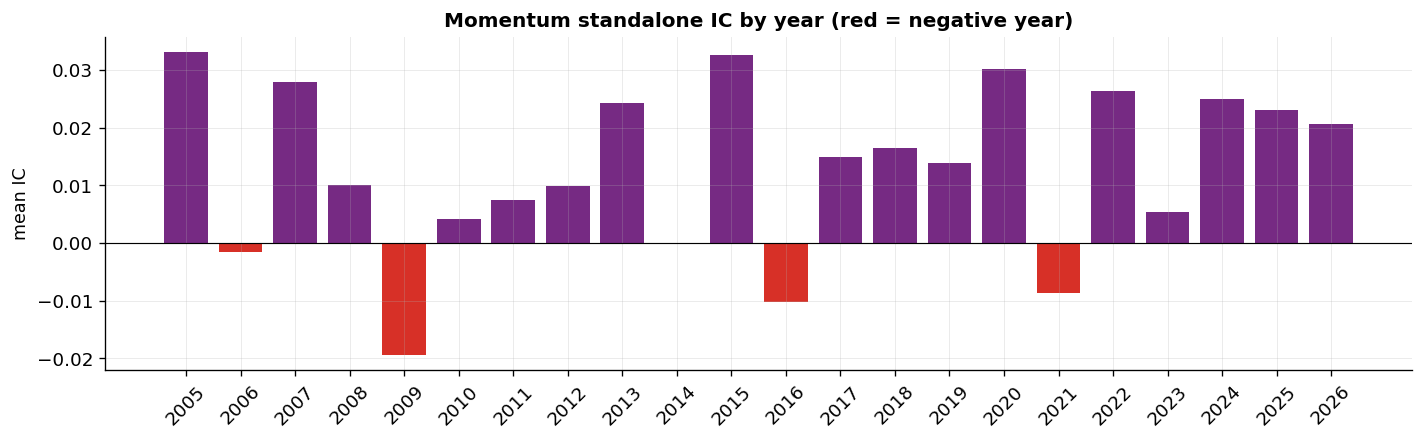

Negative momentum-IC years: 2006 (-0.0016), 2009 (-0.0194), 2016 (-0.0101), 2021 (-0.0086)
2009 is the documented post-crisis momentum crash; other negative years are reported here, not labeled.


In [13]:
from scipy.stats import spearmanr
feat=load_stage("panel_feat")
def spic(frame,col,tgt="fwd_xs"):
    d=frame.dropna(subset=[col,tgt])
    return d.groupby("date").apply(lambda x: spearmanr(x[col],x[tgt]).correlation if len(x)>=50 and x[col].nunique()>2 else np.nan).dropna()
ic_mom=spic(feat,"mom_r"); ic_rev=spic(feat,"rev_r"); ic_combo=spic(feat,"signal_r")
def summ(ic,name):
    yr=ic.groupby(ic.index.year).mean()
    print(f"  {name:10s}: IC={ic.mean():+.4f}  IR={ic.mean()/ic.std()*np.sqrt(252):5.2f}  years+={int((yr>0).sum())}/{yr.notna().sum()}")
print("Standalone Spearman IC (full sample, for reference):")
summ(ic_mom,"momentum"); summ(ic_rev,"reversal"); summ(ic_combo,"combo")
# cross-sectional correlation of the two signals
cc=feat[["mom_r","rev_r"]].dropna().corr().iloc[0,1]
print(f"\nCross-sectional correlation(momentum, reversal) = {cc:+.3f}  (near 0 ⇒ roughly independent)")
# per-year momentum IC to show crash years
mom_yr=ic_mom.groupby(ic_mom.index.year).mean()
fig,ax=plt.subplots(figsize=(12,3.8))
ax.bar(mom_yr.index.astype(str),mom_yr.values,color=[C_MOM if v>0 else C_BAD for v in mom_yr.values])
ax.axhline(0,color="k",lw=0.7); ax.set_title("Momentum standalone IC by year (red = negative year)")
ax.set_ylabel("mean IC"); ax.tick_params(axis="x",rotation=45)
plt.tight_layout(); plt.show()
neg = mom_yr[mom_yr < 0]
print("Negative momentum-IC years:", ", ".join(f"{y} ({v:+.4f})" for y, v in neg.items()) or "none")
print("2009 is the documented post-crisis momentum crash; other negative years are reported here, not labeled.")

RESULTS.update(ic_mom=float(ic_mom.mean()), ic_rev=float(ic_rev.mean()), ic_combo=float(ic_combo.mean()),
               ir_combo=float(ic_combo.mean()/ic_combo.std()*np.sqrt(252)), corr_mom_rev=float(cc))

_yp = lambda s: int((s.groupby(s.index.year).mean() > 0).sum())
RESULTS.update(ir_mom=float(ic_mom.mean()/ic_mom.std()*np.sqrt(252)), ir_rev=float(ic_rev.mean()/ic_rev.std()*np.sqrt(252)),
               years_pos_mom=_yp(ic_mom), years_pos_rev=_yp(ic_rev), years_pos_combo=_yp(ic_combo))


**Result.** Standalone momentum has mean Spearman IC **+0.0129** (IR 1.02; positive in 18/22 years),
standalone reversal **+0.0071** (IR 0.70; positive in 18/22 years), and the equal blend **+0.0132** (IR 1.20;
positive in 19/22 years). The cross-sectional correlation between the two signal ranks is **−0.017**, so in this sample
they carry largely different cross-sectional information.

That is evidence of **complementarity**, not proof that the economic mechanisms are causally independent. Negative years
are periods to investigate, not excuses to retroactively rename every loss a "known crash regime."


### 4.2a Post-review momentum-horizon sensitivity — diagnostic only

**Added after faculty review; not used to retune the core signal.** The core momentum specification remains the
231-session market-demeaned accumulation with a 21-session skip.

The cleanest way to answer “why such a long formation window for a one-day target?” is to vary the **formation length
while holding the 21-session skip fixed**. That isolates the horizon question from the separate choice to exclude the
most recent month. The alternatives below use 21, 63, 126 and 231 sessions of market-demeaned feature returns, all ending
21 sessions before the forecast date. Minimum-history requirements preserve approximately the same coverage fraction as
the core rule.

The table reports standalone daily rank IC, IR, positive years, signal coverage, and a **paired block-bootstrap difference
versus the frozen 231-session core**. A shorter window doing better would be a useful next hypothesis, not permission to
retroactively replace the core specification.

,skip_sessions,mean_IC,lo95,hi95,IR,positive_years,years,signal_coverage,delta_vs_231,delta_lo95,delta_hi95
formation_sessions,,,,,,,,,,,
21,21,0.0050,0.0012,0.0087,0.52,16,22,1.000,-0.0079,-0.0129,-0.0025
63,21,0.0067,0.0027,0.0106,0.62,18,22,0.997,-0.0062,-0.0103,-0.0018
126,21,0.0095,0.0047,0.0139,0.80,18,22,0.990,-0.0034,-0.0061,-0.0005
231,21,0.0129,0.0074,0.0174,1.02,18,22,0.979,0.0000,NaN,NaN


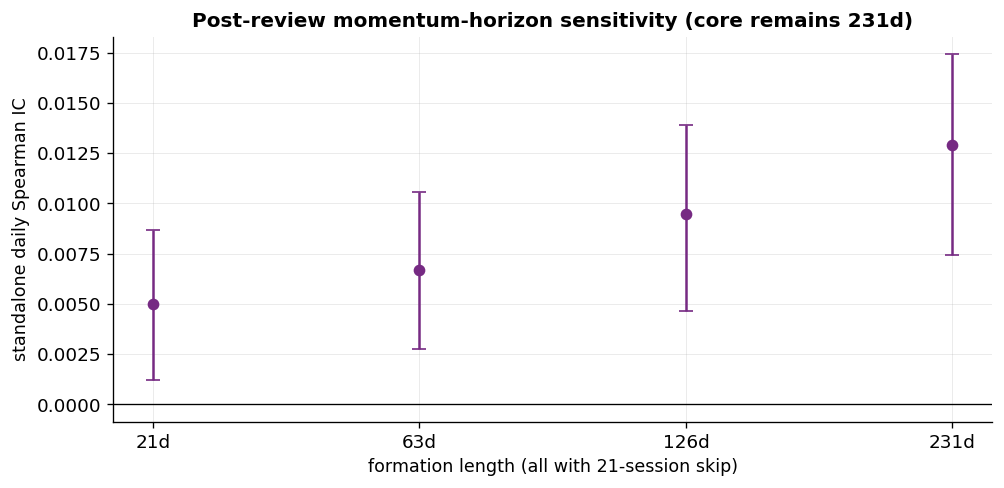

Interpretation rule: this table diagnoses horizon sensitivity; it does NOT select a replacement specification.


In [14]:
# Post-review sensitivity: vary momentum formation length, HOLDING the 21-session skip fixed.
# This cell is diagnostic only and does not modify panel_feat, panel_live, or the frozen core specification.

sens = load_stage("panel_clean").sort_values(["ticker", "date"]).copy()
sens["date"] = pd.to_datetime(sens["date"])

# Rebuild the same market-demeaned feature return used by the core signal, on full observed history.
sens["mkt_feat"] = sens.groupby("date")["ret_feature"].transform("mean")
sens["ret_resid_feat"] = sens["ret_feature"] - sens["mkt_feat"]
gsens = sens.groupby("ticker", sort=False)

# Same adjacent-next-session target as the core notebook.
_, _next_map = make_market_date_maps(sens["date"])
_adj_next = next_adjacent_mask(sens, _next_map)
sens["fwd_ret_sens"] = gsens["ret_actual"].shift(-1).where(_adj_next)

# Core uses 120 valid observations out of 231 (~52%); mirror that coverage rule across horizons.
LOOKBACKS = [21, 63, 126, 231]
MIN_OBS = {21: 11, 63: 33, 126: 65, 231: 120}
SKIP = 21

for lb in LOOKBACKS:
    sens[f"mom_{lb}_skip{SKIP}"] = gsens["ret_resid_feat"].transform(
        lambda s, lb=lb: s.rolling(lb, min_periods=MIN_OBS[lb]).sum().shift(SKIP)
    )

su = sens.loc[sens["in_universe"]].copy()
su["fwd_xs"] = su["fwd_ret_sens"] - su.groupby("date")["fwd_ret_sens"].transform("mean")

mom_ic_sens = {}
rows = []
for lb in LOOKBACKS:
    col = f"mom_{lb}_skip{SKIP}"
    rcol = f"{col}_r"
    su[rcol] = (su.groupby("date")[col].rank(pct=True) - 0.5) * 2
    ic_s = daily_ic(su, rcol, "fwd_xs")
    mom_ic_sens[lb] = ic_s
    yr = ic_s.groupby(ic_s.index.year).mean()
    mu, lo, hi = block_mean_ci(ic_s)
    rows.append({
        "formation_sessions": lb,
        "skip_sessions": SKIP,
        "mean_IC": mu,
        "lo95": lo,
        "hi95": hi,
        "IR": mu / ic_s.std() * np.sqrt(252) if ic_s.std() > 0 else np.nan,
        "positive_years": int((yr > 0).sum()),
        "years": int(yr.notna().sum()),
        "signal_coverage": float(su[rcol].notna().mean()),
    })

mom_horizon_tab = pd.DataFrame(rows).set_index("formation_sessions")

# Paired comparison with the frozen 231-session specification on common dates.
core_ic_sens = mom_ic_sens[231]
for lb in LOOKBACKS:
    if lb == 231:
        mom_horizon_tab.loc[lb, ["delta_vs_231", "delta_lo95", "delta_hi95"]] = [0.0, np.nan, np.nan]
        continue
    ix = mom_ic_sens[lb].index.intersection(core_ic_sens.index)
    d = mom_ic_sens[lb].reindex(ix) - core_ic_sens.reindex(ix)
    dm, dlo, dhi = block_mean_ci(d)
    mom_horizon_tab.loc[lb, ["delta_vs_231", "delta_lo95", "delta_hi95"]] = [dm, dlo, dhi]

display(mom_horizon_tab.round({
    "mean_IC": 4, "lo95": 4, "hi95": 4, "IR": 2, "signal_coverage": 3,
    "delta_vs_231": 4, "delta_lo95": 4, "delta_hi95": 4
}))

fig, ax = plt.subplots(figsize=(8.5, 4.2))
x = np.arange(len(mom_horizon_tab))
y = mom_horizon_tab["mean_IC"].to_numpy()
elo = (mom_horizon_tab["mean_IC"] - mom_horizon_tab["lo95"]).clip(lower=0).to_numpy()
ehi = (mom_horizon_tab["hi95"] - mom_horizon_tab["mean_IC"]).clip(lower=0).to_numpy()
ax.errorbar(x, y, yerr=[elo, ehi], fmt="o", capsize=4, color=C_MOM)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels([f"{lb}d" for lb in mom_horizon_tab.index])
ax.set_xlabel("formation length (all with 21-session skip)")
ax.set_ylabel("standalone daily Spearman IC")
ax.set_title("Post-review momentum-horizon sensitivity (core remains 231d)")
plt.tight_layout()
plt.show()

print("Interpretation rule: this table diagnoses horizon sensitivity; it does NOT select a replacement specification.")
RESULTS["postreview_mom_horizon_table_built"] = True


### 4.2b Post-review reversal-horizon decomposition — diagnostic only

The core reversal signal averages 3-, 5- and 10-session reversal to diversify uncertainty about the exact decay horizon.
Those windows correspond roughly to **half a week, one week and two weeks**. The cell below shows each leg separately so
the composite cannot hide dependence on one arbitrary horizon.

Again, this is a post-review diagnostic. The 3/5/10 composite remains frozen even if one individual horizon happens to
have the largest in-sample IC.

,mean_IC,lo95,hi95,IR,positive_years,years,coverage,delta_vs_composite,delta_lo95,delta_hi95
signal,,,,,,,,,,
rev3,0.0080,0.0046,0.0112,0.82,18,22,0.998,0.0009,-0.0017,0.0035
rev5,0.0090,0.0055,0.0127,0.90,19,22,0.996,0.0020,0.0003,0.0038
rev10,0.0040,0.0004,0.0076,0.40,16,22,0.993,-0.0029,-0.0045,-0.0010
rev_3_5_10_composite,0.0071,0.0037,0.0103,0.70,18,22,0.998,0.0000,NaN,NaN


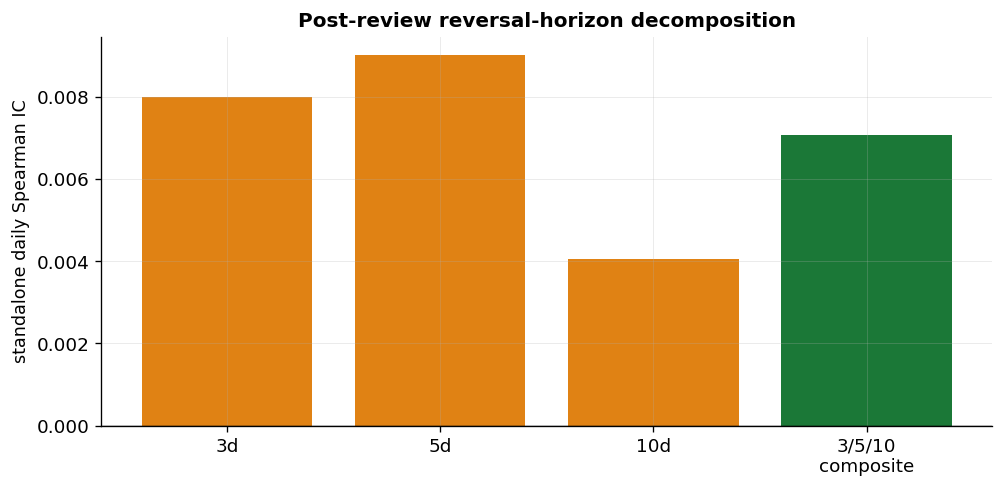

Interpretation rule: broad strength across legs supports a short-horizon family; one standout leg is not retuned into the core.


In [15]:
# Post-review diagnostic: show the 3d, 5d and 10d reversal legs separately.
rr = load_stage("panel_feat").copy()

REV_COLS = ["rev3", "rev5", "rev10"]
missing_rev = [c for c in REV_COLS if c not in rr.columns]
assert not missing_rev, f"panel_feat is missing {missing_rev}; rerun §4 feature engineering."

rev_ic_parts = {}
rows = []
for col in REV_COLS:
    rcol = f"{col}_r_postreview"
    rr[rcol] = (rr.groupby("date")[col].rank(pct=True) - 0.5) * 2
    ic_s = daily_ic(rr, rcol, "fwd_xs")
    rev_ic_parts[col] = ic_s
    yr = ic_s.groupby(ic_s.index.year).mean()
    mu, lo, hi = block_mean_ci(ic_s)
    rows.append({
        "signal": col,
        "mean_IC": mu,
        "lo95": lo,
        "hi95": hi,
        "IR": mu / ic_s.std() * np.sqrt(252) if ic_s.std() > 0 else np.nan,
        "positive_years": int((yr > 0).sum()),
        "years": int(yr.notna().sum()),
        "coverage": float(rr[rcol].notna().mean()),
    })

# Frozen composite for direct comparison.
comp_ic = daily_ic(rr, "rev_r", "fwd_xs")
yr = comp_ic.groupby(comp_ic.index.year).mean()
mu, lo, hi = block_mean_ci(comp_ic)
rows.append({
    "signal": "rev_3_5_10_composite",
    "mean_IC": mu,
    "lo95": lo,
    "hi95": hi,
    "IR": mu / comp_ic.std() * np.sqrt(252) if comp_ic.std() > 0 else np.nan,
    "positive_years": int((yr > 0).sum()),
    "years": int(yr.notna().sum()),
    "coverage": float(rr["rev_r"].notna().mean()),
})

rev_horizon_tab = pd.DataFrame(rows).set_index("signal")

# Paired differences of each leg versus the composite.
for col in REV_COLS:
    ix = rev_ic_parts[col].index.intersection(comp_ic.index)
    d = rev_ic_parts[col].reindex(ix) - comp_ic.reindex(ix)
    dm, dlo, dhi = block_mean_ci(d)
    rev_horizon_tab.loc[col, ["delta_vs_composite", "delta_lo95", "delta_hi95"]] = [dm, dlo, dhi]
rev_horizon_tab.loc["rev_3_5_10_composite", ["delta_vs_composite", "delta_lo95", "delta_hi95"]] = [0.0, np.nan, np.nan]

display(rev_horizon_tab.round({
    "mean_IC": 4, "lo95": 4, "hi95": 4, "IR": 2, "coverage": 3,
    "delta_vs_composite": 4, "delta_lo95": 4, "delta_hi95": 4
}))

fig, ax = plt.subplots(figsize=(8.5, 4.2))
plot_tab = rev_horizon_tab
x = np.arange(len(plot_tab))
ax.bar(x, plot_tab["mean_IC"].values, color=[C_REV, C_REV, C_REV, C_COMBO])
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(["3d", "5d", "10d", "3/5/10\ncomposite"])
ax.set_ylabel("standalone daily Spearman IC")
ax.set_title("Post-review reversal-horizon decomposition")
plt.tight_layout()
plt.show()

print("Interpretation rule: broad strength across legs supports a short-horizon family; one standout leg is not retuned into the core.")
RESULTS["postreview_rev_horizon_table_built"] = True


### 4.3 Rank-transform vs raw (scaling justification)

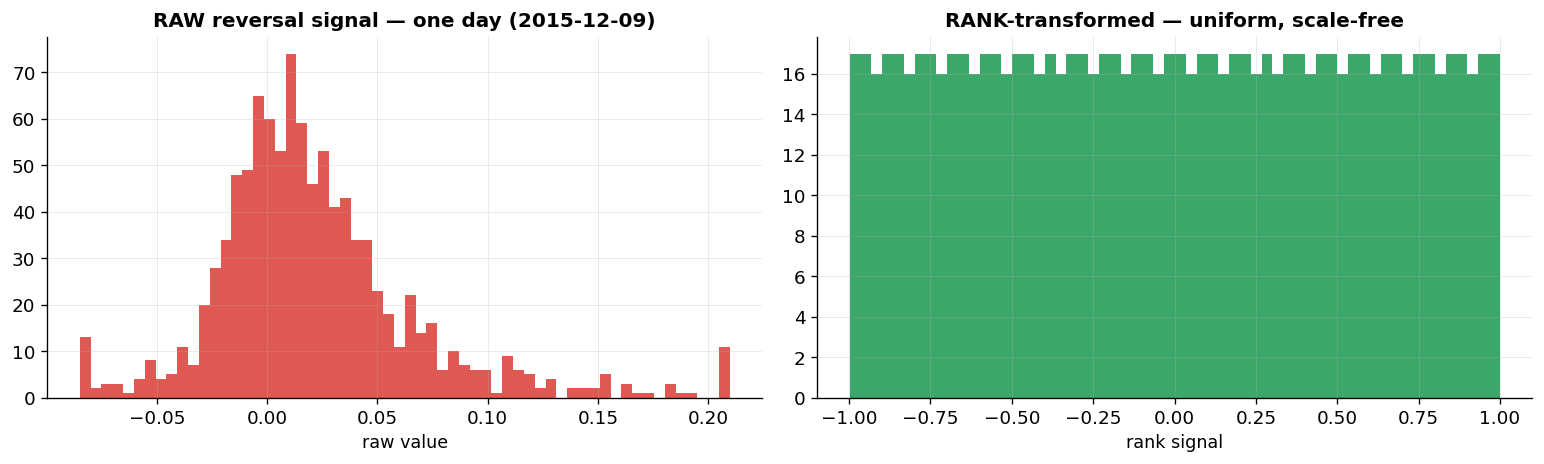

Rank-transform ⇒ scale-free & tail-robust cross-sectional signal.


In [16]:
d0=feat.dropna(subset=["rev"]).copy()
day=d0.loc[(d0["date"]-d0["date"].quantile(0.5)).abs().idxmin(),"date"]; sub=d0[d0["date"]==day]
fig,ax=plt.subplots(1,2,figsize=(13,4))
ax[0].hist(sub["rev"].clip(sub["rev"].quantile(.01),sub["rev"].quantile(.99)),bins=60,color=C_BAD,alpha=0.8)
ax[0].set_title(f"RAW reversal signal — one day ({pd.Timestamp(day).date()})"); ax[0].set_xlabel("raw value")
ax[1].hist(sub["rev_r"],bins=60,color=C_GOOD,alpha=0.85)
ax[1].set_title("RANK-transformed — uniform, scale-free"); ax[1].set_xlabel("rank signal")
plt.tight_layout(); plt.show()
print("Rank-transform ⇒ scale-free & tail-robust cross-sectional signal.")

### 4.4 IC at 0-, 1-, 2-day skip (timing design, and where bounce lives)

Skip-0 forms reversal from returns through day `T` and predicts `T→T+1`. It can't be traded at the day-`T` close it
uses, and the day-`T` return is where bid-ask bounce and closing-print noise live. Skip-1 is the tradeable convention
(information through `T−1`); skip-2 drops one more day. The skip-0 → skip-1 gap measures how much of the reversal IC
sits in that single day; the skip-1 → skip-2 gap measures whether the multi-day part decays.

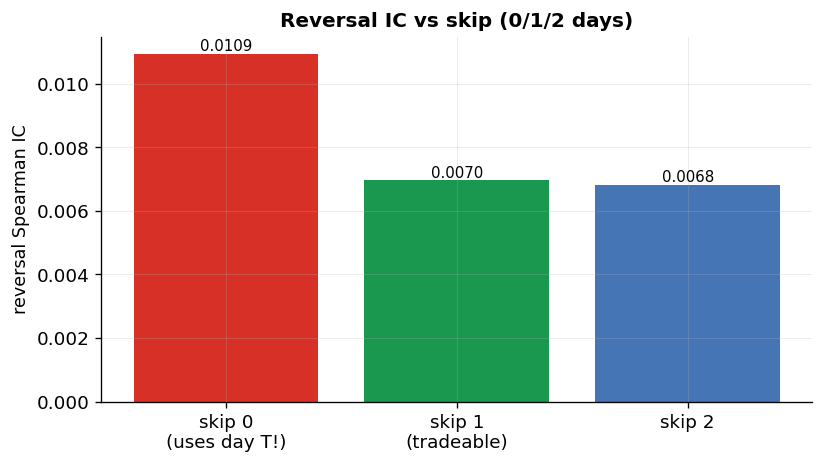

Reversal IC: skip-0=+0.0109, skip-1=+0.0070 (tradeable), skip-2=+0.0068.
The day-T return carries 36% of the skip-0 reversal IC. Bid-ask bounce and closing-print noise live there, and the skip-1 design excludes it.
Beyond day T, the multi-day reversal changes by -0.0001 from skip-1 to skip-2.


In [17]:
p=load_stage("panel_clean").sort_values(["ticker","date"])
gg=p.groupby("ticker")
_, next_map = make_market_date_maps(p["date"])
adj_next = next_adjacent_mask(p, next_map)
p["fwd_ret"] = gg["ret_actual"].shift(-1).where(adj_next)
res={}
for skip in [0,1,2]:
    # reversal signal formed with the given skip: -sum of 3/5/10d cum returns shifted by `skip`
    revs=[]
    for h in [3,5,10]:
        revs.append(-gg["ret_feature"].transform(lambda s:s.rolling(h).sum().shift(skip)))
    p["rv"]=sum(revs)/3
    f=p[p["in_universe"]].copy()
    f["rv_r"]=(f.groupby("date")["rv"].rank(pct=True)-0.5)*2
    f["fwd_xs"]=f["fwd_ret"]-f.groupby("date")["fwd_ret"].transform("mean")
    d=f.dropna(subset=["rv_r","fwd_xs"])
    ic=d.groupby("date").apply(lambda x: spearmanr(x["rv_r"],x["fwd_xs"]).correlation if len(x)>=50 else np.nan).dropna()
    res[skip]=ic.mean()
fig,ax=plt.subplots(figsize=(7,4))
ax.bar([f"skip {k}\n{'(uses day T!)' if k==0 else ('(tradeable)' if k==1 else '')}" for k in res],
       list(res.values()),color=[C_BAD,C_GOOD,C_NEU])
ax.set_ylabel("reversal Spearman IC"); ax.set_title("Reversal IC vs skip (0/1/2 days)")
for i,(k,v) in enumerate(res.items()): ax.text(i,v,f"{v:.4f}",ha="center",va="bottom",fontsize=9)
plt.tight_layout(); plt.show()
share_T = 1 - res[1]/res[0] if res[0] else np.nan
print(f"Reversal IC: skip-0={res[0]:+.4f}, skip-1={res[1]:+.4f} (tradeable), skip-2={res[2]:+.4f}.")
print(f"The day-T return carries {share_T:.0%} of the skip-0 reversal IC. Bid-ask bounce and closing-print noise live "
      "there, and the skip-1 design excludes it.")
print(f"Beyond day T, the multi-day reversal changes by {res[2]-res[1]:+.4f} from skip-1 to skip-2.")

RESULTS.update(skip0=float(res[0]), skip1=float(res[1]), skip2=float(res[2]))


---
# 5. Statistical foundations
### *Properties of the data that shape what any model can achieve — numbers printed from the data*



### 5.1 Distribution of the target (kurtosis, skew, normality)

Cross-sectional excess forward return (post-clean target):
  N=5,399,571  std=0.0227  skew=+0.76  excess_kurt=+51.7
  Jarque-Bera p=0.0e+00 → normality REJECTED


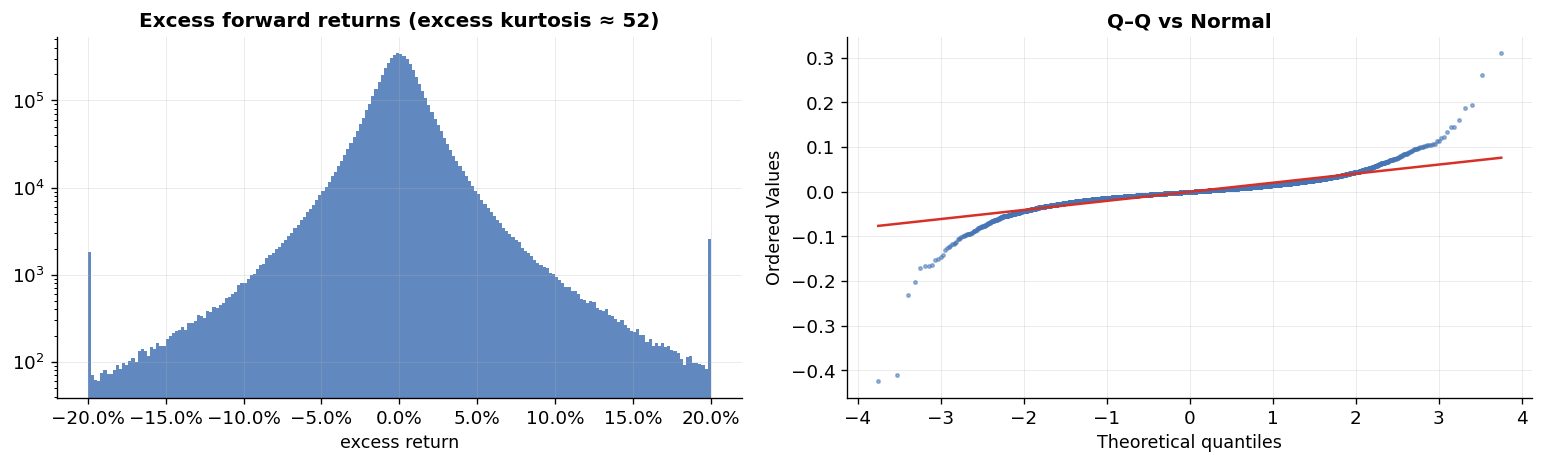

→ heavy tails (even after cleaning) justify the rank-transform used for every signal and the IC metric.


In [18]:
xs=feat["fwd_xs"].dropna()
print("Cross-sectional excess forward return (post-clean target):")
print(f"  N={len(xs):,}  std={xs.std():.4f}  skew={stats.skew(xs):+.2f}  excess_kurt={stats.kurtosis(xs):+.1f}")
jb=stats.jarque_bera(xs.sample(min(5000,len(xs)),random_state=1))
print(f"  Jarque-Bera p={jb.pvalue:.1e} → normality {'REJECTED' if jb.pvalue<0.01 else 'not rejected'}")
fig,ax=plt.subplots(1,2,figsize=(13,4))
ax[0].hist(xs.clip(-0.2,0.2),bins=200,color=C_NEU,alpha=0.85); ax[0].set_yscale("log")
ax[0].set_title(f"Excess forward returns (excess kurtosis ≈ {stats.kurtosis(xs):.0f})"); ax[0].set_xlabel("excess return")
ax[0].xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
from scipy.stats import probplot
probplot(xs.sample(min(8000,len(xs)),random_state=1),dist="norm",plot=ax[1])
ax[1].set_title("Q–Q vs Normal"); ax[1].get_lines()[0].set(marker="o",ms=2,color=C_NEU,alpha=0.5); ax[1].get_lines()[1].set(color=C_BAD,lw=1.5)
plt.tight_layout(); plt.show()
print("→ heavy tails (even after cleaning) justify the rank-transform used for every signal and the IC metric.")

**Why rank-everything.** Even after the strict target cleaning, the cross-sectional return distribution is far from
Gaussian — the excess kurtosis stays well above zero and Jarque–Bera rejects normality decisively. Equity returns are
*intrinsically* fat-tailed (real earnings surprises, buyouts, blow-ups), so this is not a data defect to keep filtering —
it is the reason we **rank-transform** signals and use a **Spearman rank IC** rather than z-scores and Pearson
correlations, which a handful of extreme names would otherwise dominate. The cleaning removed the *impossible* rows
(bad prints, corrupt tickers); the *genuine* heavy tail that remains is handled by rank statistics, not by more clipping.

### 5.2 Cross-sectional dispersion over time

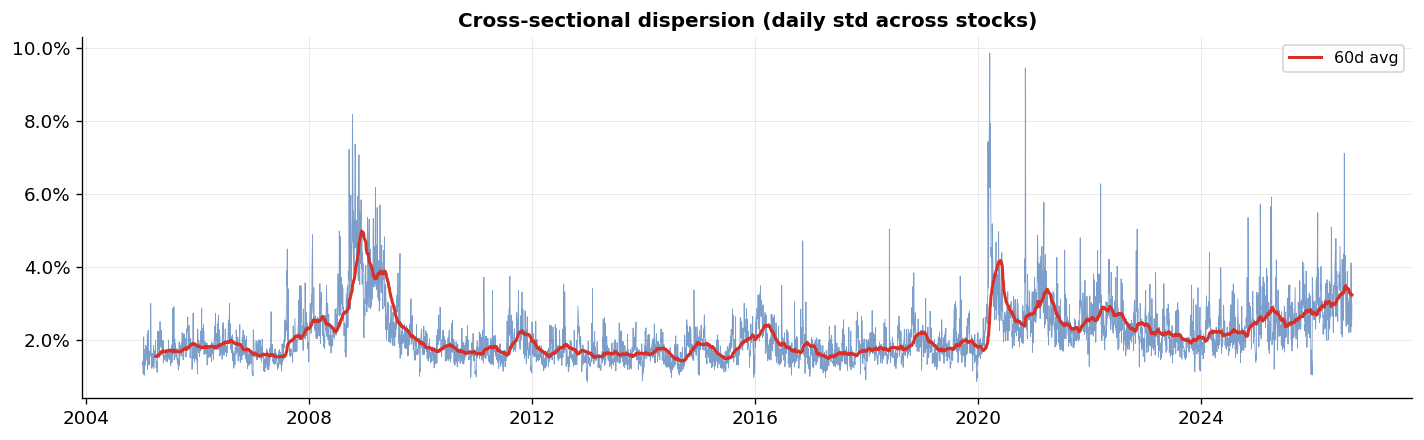

Dispersion range 0.0084 to 0.0986 (~12×).
Five highest-dispersion days: 2020-03-18 (0.0986), 2020-11-06 (0.0945), 2008-10-10 (0.0817), 2020-03-17 (0.0814), 2008-10-09 (0.0795)


In [19]:
feat["mkt_act"]=feat.groupby("date")["fwd_ret"].transform("mean")
disp=feat.groupby("date").apply(lambda d:(d["fwd_ret"]-d["mkt_act"]).std()).dropna()
fig,ax=plt.subplots(figsize=(12,3.8))
ax.plot(disp.index,disp.values,lw=0.5,color=C_NEU,alpha=0.7)
ax.plot(disp.rolling(60).mean().index,disp.rolling(60).mean().values,lw=1.8,color=C_BAD,label="60d avg")
ax.set_title("Cross-sectional dispersion (daily std across stocks)"); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.legend()
plt.tight_layout(); plt.show()
print(f"Dispersion range {disp.min():.4f} to {disp.max():.4f} (~{disp.max()/disp.min():.0f}×).")
print("Five highest-dispersion days:", ", ".join(f"{d.date()} ({v:.4f})" for d, v in disp.nlargest(5).items()))

### 5.3 Return dependence by lag — rank correlation is primary

The return target is extremely heavy-tailed, so a Pearson autocorrelation can be driven by a small number of extreme
moves. The primary diagnostic below is **Spearman rank autocorrelation** at exact market-session lags; Pearson is shown
next to it only as a scale-sensitive comparison.

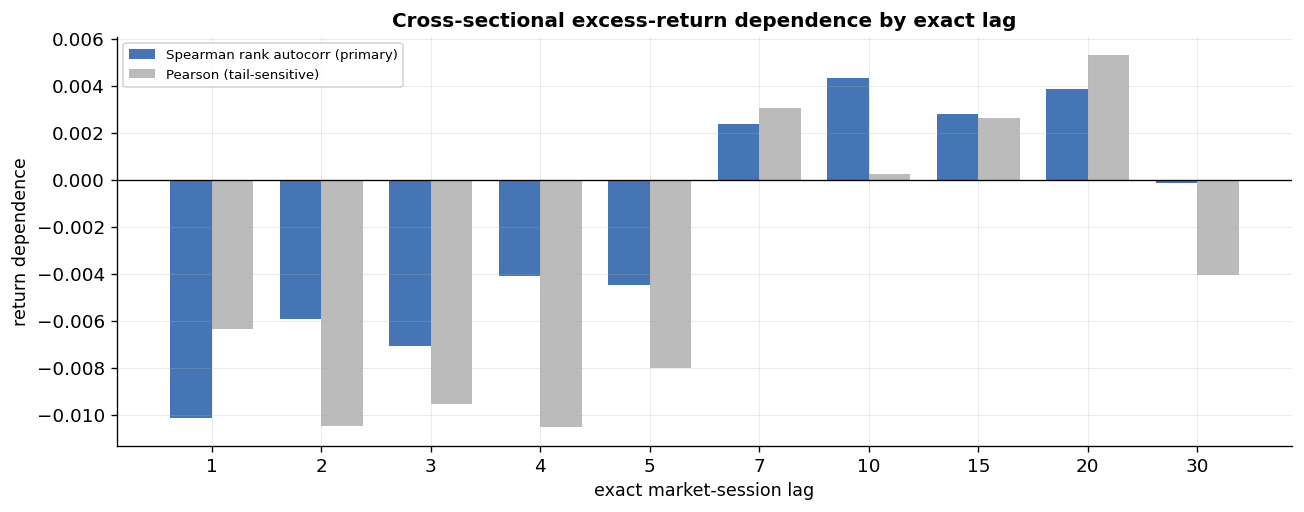

Most-negative SPEARMAN autocorrelation at exact lag 1 (value -0.0101).
Pearson is retained only as a sensitivity because the return distribution is very heavy-tailed.
Spearman by lag: {1: -0.0101, 2: -0.0059, 3: -0.0071, 4: -0.0041, 5: -0.0045, 7: 0.0024, 10: 0.0043, 15: 0.0028, 20: 0.0039, 30: -0.0001}


In [20]:
acf = load_stage("panel_clean").sort_values(["ticker","date"]).copy()
acf["date"] = pd.to_datetime(acf["date"])
cal = pd.Index(acf["date"].dropna().unique()).sort_values()
cal_pos = pd.Series(np.arange(len(cal)), index=cal)

mkt = acf.loc[acf["in_universe"]].groupby("date")["ret_actual"].mean()
acf["xr"] = acf["ret_actual"] - acf["date"].map(mkt)
curr_pos = acf["date"].map(cal_pos)
gacf = acf.groupby("ticker", sort=False)

lags = [1,2,3,4,5,7,10,15,20,30]
pear, rankac = [], []
for lag in lags:
    lag_xr = gacf["xr"].shift(lag)
    lag_date = gacf["date"].shift(lag)
    exact_lag = (curr_pos - lag_date.map(cal_pos)).eq(lag)
    use = acf["in_universe"] & exact_lag & acf["xr"].notna() & lag_xr.notna()
    x, y = acf.loc[use, "xr"], lag_xr.loc[use]
    pear.append(x.corr(y))
    rankac.append(spearmanr(x, y).correlation)

fig,ax=plt.subplots(figsize=(11,4.4))
x=np.arange(len(lags)); w=0.38
ax.bar(x-w/2,rankac,w,color=C_NEU,label="Spearman rank autocorr (primary)")
ax.bar(x+w/2,pear,w,color="#bbb",label="Pearson (tail-sensitive)")
ax.axhline(0,color="k",lw=0.8); ax.set_xticks(x); ax.set_xticklabels(lags)
ax.set_xlabel("exact market-session lag"); ax.set_ylabel("return dependence")
ax.set_title("Cross-sectional excess-return dependence by exact lag")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
peak = lags[int(np.nanargmin(rankac))]
print(f"Most-negative SPEARMAN autocorrelation at exact lag {peak} (value {np.nanmin(rankac):+.4f}).")
print("Pearson is retained only as a sensitivity because the return distribution is very heavy-tailed.")

RESULTS.update(rank_ac_lag1=float(rankac[0]), rank_ac_peak_lag=int(peak))

RESULTS["rank_ac_lags_7_to_20_positive"] = bool(all(rankac[lags.index(L)] > 0 for L in [7, 10, 15, 20]))
print("Spearman by lag:", {L: round(float(v), 4) for L, v in zip(lags, rankac)})


**What the lag profile says.** In rank terms, dependence is negative at lags 1–5 and most negative at **lag 1**
(−0.0101), then turns positive at lags 7–20, the transition toward continuation. Pearson is most negative around
lags 2–4 instead, but with returns this heavy-tailed Pearson is driven by a few extreme moves.

So the one-day skip gives up the strongest lag on purpose. A day-`T` close can't be traded at that same close, and the
lag-1 return is where bid-ask bounce and closing-print noise live. §4.4 prices the choice at about a third of reversal IC
(**0.0109 → 0.0070**). What the 3/5/10 composite keeps is the lag 2–5 reversal, and the two signals sit on opposite
sides of this curve.


### 5.4 Correlation rises in crises (the defensible observation)

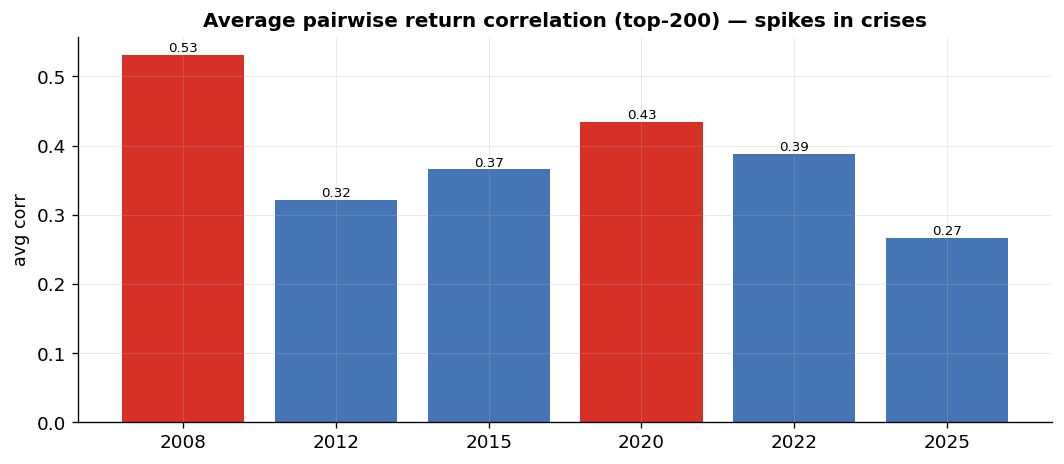

Average pairwise correlation (top-200 names): 2008: 0.53, 2012: 0.32, 2015: 0.37, 2020: 0.43, 2022: 0.39, 2025: 0.27
Highest in 2008: diversification across names is weakest in stress years.


In [21]:
rows=[]
for yr in [2008,2012,2015,2020,2022,2025]:
    sub=feat[feat["date"].dt.year==yr]; top=sub.groupby("ticker")["adv60"].mean().nlargest(200).index
    wide=sub[sub["ticker"].isin(top)].pivot_table(index="date",columns="ticker",values="ret_actual")
    cm=wide.corr().values; rows.append((yr,np.nanmean(cm[np.triu_indices_from(cm,1)])))
bd=pd.DataFrame(rows,columns=["year","avg_corr"])
fig,ax=plt.subplots(figsize=(9,4))
ax.bar(bd["year"].astype(str),bd["avg_corr"],color=[C_BAD if y in(2008,2020) else C_NEU for y in bd["year"]])
ax.set_title("Average pairwise return correlation (top-200) — spikes in crises"); ax.set_ylabel("avg corr")
for i,v in enumerate(bd["avg_corr"]): ax.text(i,v,f"{v:.2f}",ha="center",va="bottom",fontsize=8)
plt.tight_layout(); plt.show()
print("Average pairwise correlation (top-200 names):", ", ".join(f"{y}: {c:.2f}" for y, c in zip(bd["year"], bd["avg_corr"])))
print(f"Highest in {int(bd.loc[bd['avg_corr'].idxmax(), 'year'])}: diversification across names is weakest in stress years.")

### 5.5 Non-stationarity (justifies walk-forward)

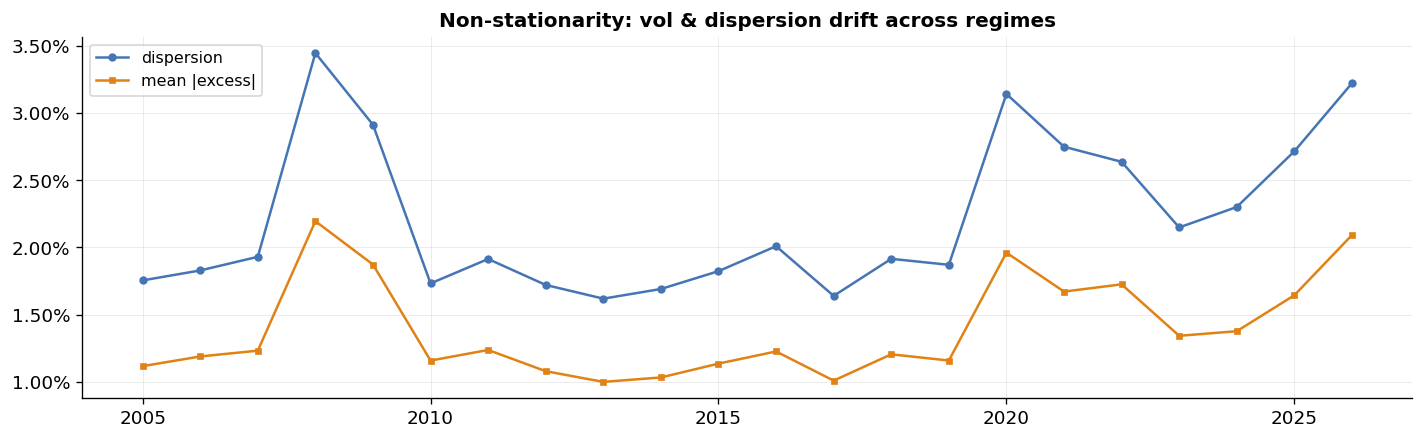

→ justifies walk-forward re-fitting.


In [22]:
feat["xr_act"]=feat["ret_actual"]-feat.groupby("date")["ret_actual"].transform("mean")
yearly=feat.groupby(feat["date"].dt.year).agg(mean_abs=("xr_act",lambda s:s.abs().mean()),disp=("xr_act","std"))
fig,ax=plt.subplots(figsize=(12,3.8))
ax.plot(yearly.index,yearly["disp"],marker="o",ms=4,color=C_NEU,label="dispersion")
ax.plot(yearly.index,yearly["mean_abs"],marker="s",ms=3,color="#e08214",label="mean |excess|")
ax.set_title("Non-stationarity: vol & dispersion drift across regimes"); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.legend()
plt.tight_layout(); plt.show()
print("→ justifies walk-forward re-fitting.")

### 5.6 Signal-to-noise — a careful scale reference

An IC near 1% corresponds to an order-10⁻⁴ squared correlation at the individual stock-day level: very low
signal-to-noise. Stated as a scale reference, **not** "X% of variance explained." At this level, a model comparison
only means something on matched out-of-sample dates with paired uncertainty, which is how §6.3 is built.

In [23]:
ic=abs(ic_combo.mean())
print(f"Combined IC≈{ic:.4f} ⇒ squared correlation ≈ {ic**2:.1e} at the stock-day level (scale reference).")
print("At this signal-to-noise, model comparisons need matched out-of-sample dates and paired uncertainty (§6.3).")

Combined IC≈0.0132 ⇒ squared correlation ≈ 1.7e-04 at the stock-day level (scale reference).
At this signal-to-noise, model comparisons need matched out-of-sample dates and paired uncertainty (§6.3).


---
# 6. Beyond the core signal — extra features, anomalies, and an ML ablation
### *A standalone keep rule, then incremental tests; ML split into weights, conditioners and nonlinearity*

Every candidate feature goes through two gates.

1. **Standalone (§6.1–6.2):** absolute mean daily IC ≥ 0.003 and max |corr| with the momentum or reversal rank ≤ 0.30,
   with the sign shown.
2. **Incremental (§6.2b):** a *unique-information* test (the feature's IC after residualizing it on momentum and
   reversal, corrected for testing seven candidates) and a *fixed-weight* test (does adding it at equal weight raise the
   blend's IC).

Passing the first gate says a feature carries information of its own; only the second says the blend lacks it. §6.3
applies the same logic to fitted models and checks whether any gain is a size or volatility tilt rather than
stock-specific information.


### 6.0 When the data challenged the thesis

One-day reversal is not stable across years. In rank terms, lag-1 dependence is positive (no reversal) in 3 of 22
years: 2013, 2020 and 2022. Pearson is shown only as a tail-sensitive comparison. Rather than explain the positive years
away, §8.4 tests what the liquidity-provision story implies: reversal should be stronger after abnormal volume and after
high cross-sectional dispersion.


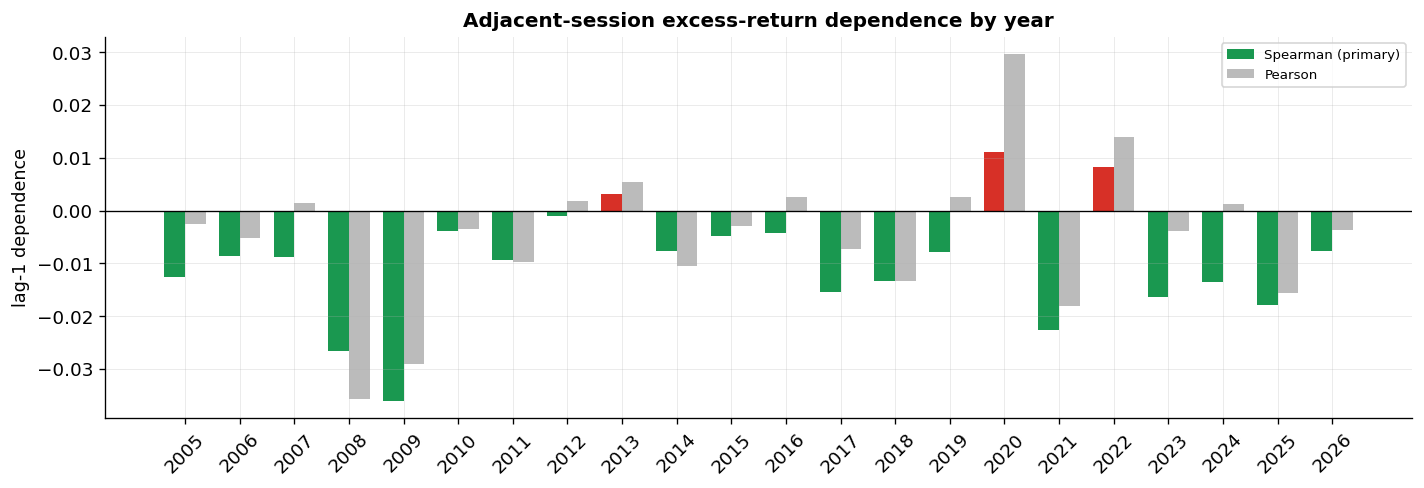

Spearman lag-1 dependence is positive (no rank reversal) in 3 of 22 years: [2013, 2020, 2022].
Strongest rank-reversal years: [2009, 2008, 2021]. §8.4 tests volume/dispersion conditioning.


In [24]:
acf1 = load_stage("panel_clean").sort_values(["ticker","date"]).copy()
acf1["date"] = pd.to_datetime(acf1["date"])
prev_map, _ = make_market_date_maps(acf1["date"])
adj_prev = prev_adjacent_mask(acf1, prev_map)

mkt = acf1.loc[acf1["in_universe"]].groupby("date")["ret_actual"].mean()
acf1["xr"] = acf1["ret_actual"] - acf1["date"].map(mkt)
acf1["xr_lag1"] = acf1.groupby("ticker", sort=False)["xr"].shift(1).where(adj_prev)
use = acf1["in_universe"] & acf1["xr"].notna() & acf1["xr_lag1"].notna()
q = acf1.loc[use].copy(); q["year"] = q["date"].dt.year
pear_y = q.groupby("year").apply(lambda d: d["xr"].corr(d["xr_lag1"]))
rank_y = q.groupby("year").apply(lambda d: spearmanr(d["xr"], d["xr_lag1"]).correlation)

fig,ax=plt.subplots(figsize=(12,4.2))
x=np.arange(len(rank_y)); w=.38
ax.bar(x-w/2,rank_y.values,w,color=[C_GOOD if v<0 else C_BAD for v in rank_y.values],label="Spearman (primary)")
ax.bar(x+w/2,pear_y.reindex(rank_y.index).values,w,color="#bbb",label="Pearson")
ax.axhline(0,color="k",lw=0.8); ax.set_xticks(x); ax.set_xticklabels(rank_y.index.astype(str),rotation=45)
ax.set_title("Adjacent-session excess-return dependence by year")
ax.set_ylabel("lag-1 dependence"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
pos = rank_y[rank_y > 0]
print(f"Spearman lag-1 dependence is positive (no rank reversal) in {len(pos)} of {len(rank_y)} years: {list(pos.index)}.")
print(f"Strongest rank-reversal years: {list(rank_y.nsmallest(3).index)}. §8.4 tests volume/dispersion conditioning.")

RESULTS["rank_lag1_positive_years"] = int(len(pos))


### 6.1 More handcrafted OHLCV signals — standalone keep rule

Gap-fade (fade yesterday's open gap), intraday reversal (fade yesterday's open→close move), close location within
yesterday's range, and the 5-day/60-day volatility term structure. All are built on the full panel before the
universe-filtered merge, and the chart shows the signed IC.

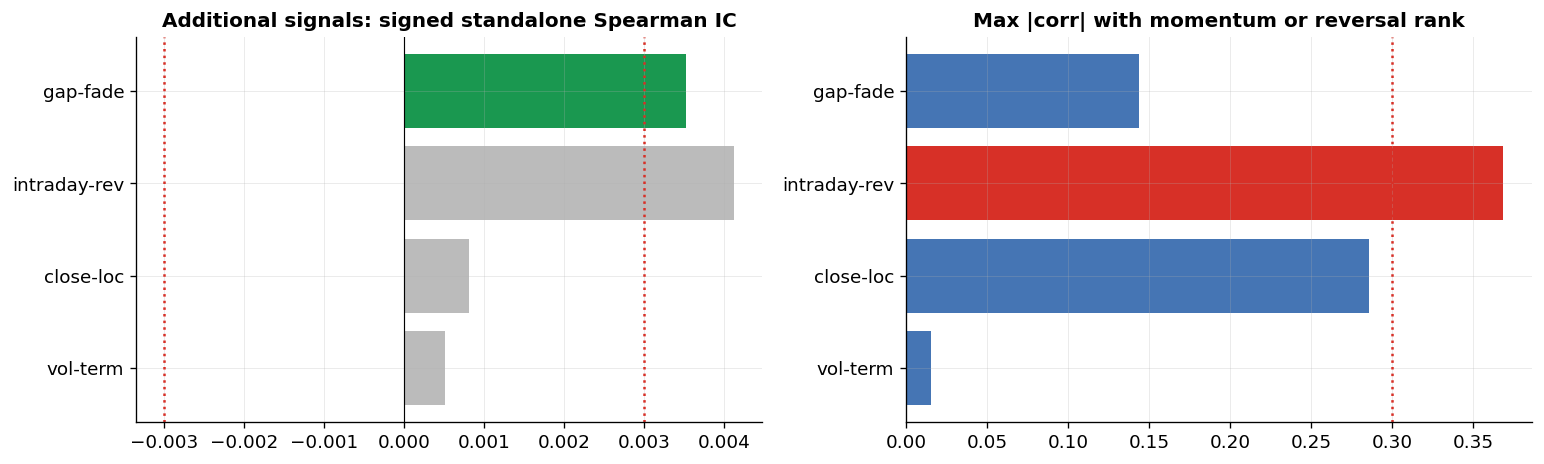

,IC,IR,corr_mom,corr_rev,max_abs_corr,passes
signal,,,,,,
gap-fade,0.0035,0.3699,-0.0345,0.1436,0.1436,True
intraday-rev,0.0041,0.4660,-0.0006,0.3683,0.3683,False
close-loc,0.0008,0.1216,-0.0130,0.2860,0.2860,False
vol-term,0.0005,0.0906,-0.0010,0.0153,0.0153,False


Pass the standalone keep rule: ['gap-fade']
A standalone pass is necessary, not sufficient; §6.2b tests whether each signal adds to momentum + reversal.


In [25]:
core = load_stage("panel_feat").copy()
p_extra = load_stage("panel_clean").sort_values(["ticker","date"]).copy()
p_extra["date"] = pd.to_datetime(p_extra["date"])
gp = p_extra.groupby("ticker", sort=False)
prev_map, _ = make_market_date_maps(p_extra["date"])
adj_prev = prev_adjacent_mask(p_extra, prev_map)

prev_close = gp["close"].shift(1)
gap_today = (p_extra["open"]/prev_close - 1).where(adj_prev)
p_extra["s_gap"] = -gap_today.groupby(p_extra["ticker"], sort=False).shift(1)
p_extra["s_intr"] = -(p_extra["close"]/p_extra["open"] - 1).groupby(p_extra["ticker"], sort=False).shift(1)
rng = (p_extra["high"] - p_extra["low"]).replace(0, np.nan)
p_extra["s_cl"] = -((p_extra["close"] - p_extra["low"])/rng).groupby(p_extra["ticker"], sort=False).shift(1)
v5 = gp["ret_feature"].transform(lambda s:s.rolling(5).std().shift(1))
v60 = gp["ret_feature"].transform(lambda s:s.rolling(60,min_periods=40).std().shift(1))
p_extra["s_vt"] = -(v5/v60)

cols = ["ticker","date","s_gap","s_intr","s_cl","s_vt"]
df = core.merge(p_extra[cols], on=["ticker","date"], how="left", validate="one_to_one")
del p_extra, gp, prev_close, gap_today, rng, v5, v60   # free memory; not used later

def xs_rank(s,by):
    r=s.groupby(by).rank(pct=True); return (r-0.5)*2
new={"gap-fade":"s_gap","intraday-rev":"s_intr","close-loc":"s_cl","vol-term":"s_vt"}
for nm,c in new.items():
    df[c+"_r"] = xs_rank(df[c],df["date"])

# Standalone keep rule, applied with the SIGN shown:
#   (1) |mean daily Spearman IC| >= 0.003   and   (2) max |corr| with the momentum or reversal rank <= 0.30.
IC_BAR, CORR_BAR = 0.003, 0.30
def keep_rule(names_to_cols):
    rows = []
    for nm, c in names_to_cols.items():
        ic = daily_ic(df, c+"_r", "fwd_xs")
        cm, cr = df[c+"_r"].corr(df["mom_r"]), df[c+"_r"].corr(df["rev_r"])
        mx = max(abs(cm), abs(cr))
        rows.append(dict(signal=nm, col=c+"_r", IC=ic.mean(), IR=ic.mean()/ic.std()*np.sqrt(252),
                         corr_mom=cm, corr_rev=cr, max_abs_corr=mx,
                         passes=bool(abs(ic.mean()) >= IC_BAR and mx <= CORR_BAR)))
    return pd.DataFrame(rows).set_index("signal")

keep_61 = keep_rule(new)

names = list(keep_61.index)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].barh(names, keep_61["IC"], color=[C_GOOD if p else "#bbb" for p in keep_61["passes"]])
for x in (IC_BAR, -IC_BAR):
    ax[0].axvline(x, ls=":", color=C_BAD)
ax[0].axvline(0, color="k", lw=0.7); ax[0].invert_yaxis()
ax[0].set_title("Additional signals: signed standalone Spearman IC")
ax[1].barh(names, keep_61["max_abs_corr"], color=[C_BAD if v > CORR_BAR else C_NEU for v in keep_61["max_abs_corr"]])
ax[1].axvline(CORR_BAR, ls=":", color=C_BAD); ax[1].invert_yaxis()
ax[1].set_title("Max |corr| with momentum or reversal rank")
plt.tight_layout(); plt.show()

display(keep_61.drop(columns="col").round(4))
print("Pass the standalone keep rule:", [n for n in names if keep_61.loc[n, "passes"]] or "none")
print("A standalone pass is necessary, not sufficient; §6.2b tests whether each signal adds to momentum + reversal.")

RESULTS["ic_gapfade"] = float(keep_61.loc["gap-fade", "IC"])


### 6.2 Documented anomalies (MAX/lottery, skewness, idiosyncratic volatility) — with the sign shown

Each feature is negated, so a **positive IC is the documented direction**: low-MAX, low-skewness and low-idio-vol stocks
outperform. The sign matters. A negative IC would mean volatile, lottery-like names outperform, and survivorship is then
the first suspect: those are exactly the stocks most likely to have died and be missing from the feed, leaving only
their lucky survivors.

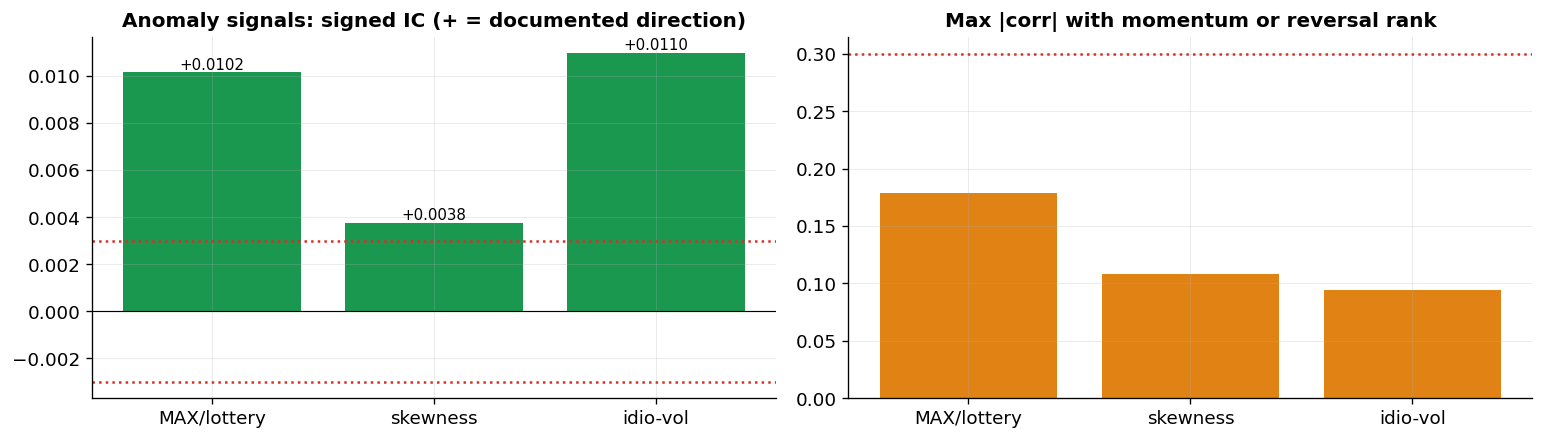

,IC,IR,corr_mom,corr_rev,max_abs_corr,passes
signal,,,,,,
MAX/lottery,0.0102,0.8157,-0.0581,0.1792,0.1792,True
skewness,0.0038,0.7393,-0.0722,0.1082,0.1082,True
idio-vol,0.0110,0.9017,-0.0947,0.0106,0.0947,True


MAX/lottery  IC=+0.0102  keep rule=pass  → documented direction: calmer, less lottery-like names outperform
skewness     IC=+0.0038  keep rule=pass  → documented direction: calmer, less lottery-like names outperform
idio-vol     IC=+0.0110  keep rule=pass  → documented direction: calmer, less lottery-like names outperform


In [26]:
# Additional anomaly-style features, again built on the FULL panel before merging.
p_anom = load_stage("panel_clean").sort_values(["ticker","date"]).copy()
ga = p_anom.groupby("ticker", sort=False)

p_anom["e_max"] = -ga["ret_feature"].transform(lambda s:s.rolling(21,min_periods=15).max().shift(1))
p_anom["e_skew"] = -ga["ret_feature"].transform(lambda s:s.rolling(60,min_periods=40).skew().shift(1))
p_anom["rr"] = p_anom["ret_feature"] - p_anom.groupby("date")["ret_feature"].transform("mean")
p_anom["e_idv"] = -p_anom.groupby("ticker", sort=False)["rr"].transform(
    lambda s:s.rolling(60,min_periods=40).std().shift(1)
)

df = df.drop(columns=[c for c in ["e_max","e_skew","e_idv"] if c in df.columns], errors="ignore")
df = df.merge(
    p_anom[["ticker","date","e_max","e_skew","e_idv"]],
    on=["ticker","date"], how="left", validate="one_to_one"
)
del p_anom, ga   # free memory; not used later
for c in ["e_max","e_skew","e_idv"]:
    df[c+"_r"] = xs_rank(df[c],df["date"])

# Sign convention: each feature is NEGATED, so a POSITIVE IC is the documented anomaly direction
# (low-MAX, low-skewness and low-idiosyncratic-volatility stocks outperform).
cand = {"MAX/lottery":"e_max", "skewness":"e_skew", "idio-vol":"e_idv"}
keep_62 = keep_rule(cand)

names = list(keep_62.index)
cols_ = [(C_GOOD if v > 0 else C_BAD) if p else "#bbb" for p, v in zip(keep_62["passes"], keep_62["IC"])]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].bar(names, keep_62["IC"], color=cols_)
for x in (IC_BAR, -IC_BAR):
    ax[0].axhline(x, ls=":", color=C_BAD)
ax[0].axhline(0, color="k", lw=0.7)
for i, v in enumerate(keep_62["IC"]):
    ax[0].text(i, v, f"{v:+.4f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=9)
ax[0].set_title("Anomaly signals: signed IC (+ = documented direction)")
ax[1].bar(names, keep_62["max_abs_corr"], color="#e08214"); ax[1].axhline(CORR_BAR, ls=":", color=C_BAD)
ax[1].set_title("Max |corr| with momentum or reversal rank")
plt.tight_layout(); plt.show()

display(keep_62.drop(columns="col").round(4))
for n in names:
    v = keep_62.loc[n, "IC"]
    if v > 0:
        reading = "documented direction: calmer, less lottery-like names outperform"
    else:
        reading = ("OPPOSITE of the documented anomaly: volatile, lottery-like names outperform. Survivorship is the "
                   "first suspect, since those are the names most likely to have died and be missing from the feed")
    print(f"{n:12s} IC={v:+.4f}  keep rule={'pass' if keep_62.loc[n, 'passes'] else 'fail'}  → {reading}")

RESULTS.update(ic_idvol=float(keep_62.loc["idio-vol","IC"]), ic_max=float(keep_62.loc["MAX/lottery","IC"]),
               ic_skew=float(keep_62.loc["skewness","IC"]))


### 6.2b Fixed-weight blend impact **and** unique-information test

The fixed-weight `rank(mom + rev + x)` test answers a narrow question: **does this candidate help at that specific
1:1:1-style sizing?** A real but weak signal can fail that test simply because it is overweighted, so the result must not
be paraphrased as “the feature carries no information.”

This section therefore reports two different tests:

1. **Fixed-weight blend impact.** The candidate's rank is added at equal weight, with its sign estimated from prior
   years only. This is a
   portfolio-combination sensitivity, not a discovery test.
2. **Unique-information IC.** Each candidate is residualized cross-sectionally, date by date, against momentum and
   reversal ranks. The residual's next-day Spearman IC asks whether the feature contains linear cross-sectional
   information not already in the core. Because seven candidates are examined, a **joint 21-day block max-statistic
   bootstrap** supplies simultaneous 95% intervals / family-wise p-values. MAX and idiosyncratic volatility are also
   reported as a correlated “lottery/volatility family,” not counted as two independent discoveries.

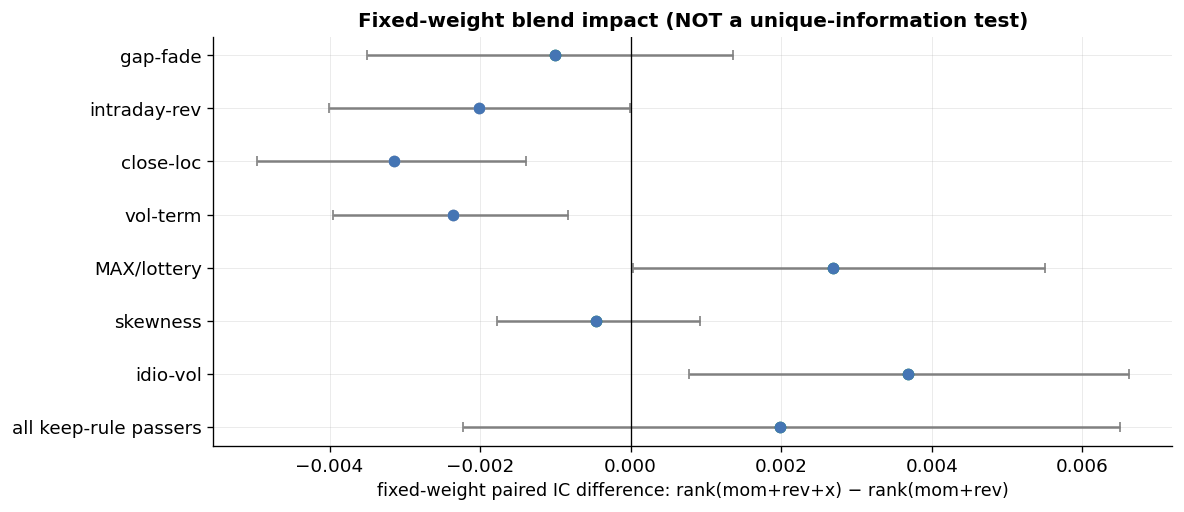

,standalone_pass,base_IC,aug_IC,diff,lo95,hi95,days,improves_at_fixed_weight
gap-fade,True,0.0123,0.0113,-0.00101,-0.00351,0.00136,5194,False
intraday-rev,False,0.0123,0.0103,-0.00201,-0.00400,-0.00000,5194,False
close-loc,False,0.0123,0.0092,-0.00315,-0.00496,-0.00140,5194,False
vol-term,False,0.0121,0.0098,-0.00236,-0.00395,-0.00083,5188,False
MAX/lottery,True,0.0123,0.0150,0.00269,0.00003,0.00551,5194,True
skewness,True,0.0123,0.0119,-0.00046,-0.00178,0.00092,5194,False
idio-vol,True,0.0123,0.0160,0.00368,0.00077,0.00662,5194,True
all keep-rule passers,True,0.0123,0.0143,0.00198,-0.00222,0.00651,5194,False


gap-fade               Δ=-0.00101 [-0.00351, +0.00136] → no detectable effect at this sizing (CI spans 0)
intraday-rev           Δ=-0.00201 [-0.00400, -0.00000] → hurts this fixed-weight blend (CI below 0)
close-loc              Δ=-0.00315 [-0.00496, -0.00140] → hurts this fixed-weight blend (CI below 0)
vol-term               Δ=-0.00236 [-0.00395, -0.00083] → hurts this fixed-weight blend (CI below 0)
MAX/lottery            Δ=+0.00269 [+0.00003, +0.00551] → improves this fixed-weight blend (CI above 0)
skewness               Δ=-0.00046 [-0.00178, +0.00092] → no detectable effect at this sizing (CI spans 0)
idio-vol               Δ=+0.00368 [+0.00077, +0.00662] → improves this fixed-weight blend (CI above 0)
all keep-rule passers  Δ=+0.00198 [-0.00222, +0.00651] → no detectable effect at this sizing (CI spans 0)

Unique-information test after cross-sectional residualization on momentum + reversal:


,unique_IC,lo95_ind,hi95_ind,days,unique_IC_common,simul_lo95,simul_hi95,FWER_p
signal,,,,,,,,
gap-fade,0.00219,-0.00103,0.00561,5446,0.00212,-0.00261,0.00685,0.62469
intraday-rev,0.00094,-0.00203,0.00386,5446,0.00086,-0.00387,0.00559,0.98451
close-loc,-0.00049,-0.00270,0.00183,5446,-0.00055,-0.00528,0.00418,0.99850
vol-term,0.00075,-0.00112,0.00261,5440,0.00075,-0.00398,0.00547,0.99150
MAX/lottery,0.00909,0.00497,0.01304,5446,0.00911,0.00438,0.01384,0.00050
skewness,0.00351,0.00178,0.00521,5446,0.00351,-0.00121,0.00824,0.18891
idio-vol,0.01092,0.00693,0.01486,5446,0.01095,0.00622,0.01567,0.00050


MAX/lottery vs idio-vol rank correlation = +0.676; interpret them as one related lottery/volatility family, not independent discoveries.
Use the simultaneous interval / FWER_p for discovery claims across the seven candidates. The fixed-weight table only answers a sizing question.


In [27]:
# Incremental value over momentum + reversal on matched stock-days. No weights are fitted.
# Each candidate enters with the sign of its own mean IC over PRIOR years only (expanding window).
keep_all = pd.concat([keep_61, keep_62])
passers = [n for n in keep_all.index if keep_all.loc[n, "passes"]]

def prior_year_sign(ic_daily):
    yr = ic_daily.groupby(ic_daily.index.year).mean()
    return np.sign(yr.expanding().mean().shift(1))      # year Y uses years < Y

def incremental(cols):
    use = df[["date", "mom_r", "rev_r", "fwd_xs"] + cols].dropna().copy()
    add = pd.Series(0.0, index=use.index)
    for c in cols:
        sgn = prior_year_sign(daily_ic(use, c, "fwd_xs"))
        add = add + use["date"].dt.year.map(sgn) * use[c]
    use["add"] = add
    use = use.dropna(subset=["add"])                     # drops the first year (no prior history)
    use["base"] = xs_rank(use["mom_r"] + use["rev_r"], use["date"])
    use["aug"] = xs_rank(use["mom_r"] + use["rev_r"] + use["add"], use["date"])
    ib, ia = daily_ic(use, "base", "fwd_xs"), daily_ic(use, "aug", "fwd_xs")
    common = ib.index.intersection(ia.index)
    m, lo, hi = block_mean_ci(ia.reindex(common) - ib.reindex(common))
    return dict(base_IC=ib.reindex(common).mean(), aug_IC=ia.reindex(common).mean(),
                diff=m, lo95=lo, hi95=hi, days=len(common))

rows = {n: incremental([keep_all.loc[n, "col"]]) for n in keep_all.index}
if len(passers) > 1:
    rows["all keep-rule passers"] = incremental([keep_all.loc[n, "col"] for n in passers])
inc = pd.DataFrame(rows).T.astype(float)
inc["days"] = inc["days"].astype(int)
inc.insert(0, "standalone_pass", [bool(keep_all.loc[n, "passes"]) if n in keep_all.index else True for n in inc.index])
inc["improves_at_fixed_weight"] = inc["lo95"] > 0

y = np.arange(len(inc))
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.errorbar(inc["diff"], y, xerr=[(inc["diff"] - inc["lo95"]).clip(lower=0), (inc["hi95"] - inc["diff"]).clip(lower=0)],
            fmt="o", color=C_NEU, ecolor="gray", capsize=3)
for yi, (d, p) in enumerate(zip(inc["diff"], inc["standalone_pass"])):
    ax.plot(d, yi, "o", color=C_GOOD if p else "#bbb")
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(y); ax.set_yticklabels(inc.index); ax.invert_yaxis()
ax.set_xlabel("fixed-weight paired IC difference: rank(mom+rev+x) − rank(mom+rev)")
ax.set_title("Fixed-weight blend impact (NOT a unique-information test)")
plt.tight_layout(); plt.show()

display(inc.round({"base_IC": 4, "aug_IC": 4, "diff": 5, "lo95": 5, "hi95": 5}))
for n, r in inc.iterrows():
    if r["lo95"] > 0:
        verdict = "improves this fixed-weight blend (CI above 0)"
    elif r["hi95"] < 0:
        verdict = "hurts this fixed-weight blend (CI below 0)"
    else:
        verdict = "no detectable effect at this sizing (CI spans 0)"
    print(f"{n:22s} Δ={r['diff']:+.5f} [{r['lo95']:+.5f}, {r['hi95']:+.5f}] → {verdict}")

# ---- Unique-information test: residualize each candidate against mom/rev within each date ----
def residualize_on_core(frame, ycol, x1="mom_r", x2="rev_r"):
    dt = frame["date"]
    dm = lambda s: s - s.groupby(dt).transform("mean")
    y, a, b = dm(frame[ycol]), dm(frame[x1]), dm(frame[x2])
    S = lambda z: z.groupby(dt).transform("sum")
    s11, s22, s12 = S(a*a), S(b*b), S(a*b)
    s1y, s2y = S(a*y), S(b*y)
    det = (s11*s22 - s12*s12).replace(0, np.nan)
    b1 = (s22*s1y - s12*s2y) / det
    b2 = (s11*s2y - s12*s1y) / det
    return y - b1*a - b2*b

unique_daily = {}
for n in keep_all.index:
    c = keep_all.loc[n, "col"]
    use = df[["date","mom_r","rev_r","fwd_xs",c]].dropna().copy()
    use["x_resid"] = residualize_on_core(use, c)
    unique_daily[n] = daily_ic(use, "x_resid", "fwd_xs")

# Individual block CIs first.
unique_rows = []
for n, ser in unique_daily.items():
    mu, lo, hi = block_mean_ci(ser)
    unique_rows.append((n, mu, lo, hi, len(ser)))
unique_tab = pd.DataFrame(unique_rows, columns=["signal","unique_IC","lo95_ind","hi95_ind","days"]).set_index("signal")

# Family-wise max-statistic block bootstrap on common dates, centered under the joint null.
U = pd.concat(unique_daily, axis=1).dropna().sort_index()
X = U.to_numpy(dtype=float); obs = X.mean(axis=0); X0 = X - obs
block, B = 21, 2000
blocks = [X0[i:i+block] for i in range(0, len(X0)-block+1, block)]
need = math.ceil(len(X0)/block); rng = np.random.default_rng(20260923)
bm = np.empty((B, X.shape[1]))
for b in range(B):
    z = np.concatenate([blocks[j] for j in rng.integers(0, len(blocks), size=need)], axis=0)[:len(X0)]
    bm[b] = z.mean(axis=0)
max_abs = np.abs(bm).max(axis=1)
crit95 = np.quantile(max_abs, .95)
fwer_p = [(1 + np.sum(max_abs >= abs(v))) / (B + 1) for v in obs]
simul = pd.DataFrame({"unique_IC_common":obs, "simul_lo95":obs-crit95, "simul_hi95":obs+crit95, "FWER_p":fwer_p}, index=U.columns)
unique_tab = unique_tab.join(simul)
print("\nUnique-information test after cross-sectional residualization on momentum + reversal:")
display(unique_tab.round(5))

if "MAX/lottery" in keep_all.index and "idio-vol" in keep_all.index:
    cm = keep_all.loc["MAX/lottery","col"]; ci = keep_all.loc["idio-vol","col"]
    overlap_corr = df[[cm,ci]].corr().iloc[0,1]
    print(f"MAX/lottery vs idio-vol rank correlation = {overlap_corr:+.3f}; interpret them as one related lottery/volatility family, not independent discoveries.")
print("Use the simultaneous interval / FWER_p for discovery claims across the seven candidates. The fixed-weight table only answers a sizing question.")

RESULTS.update(
    uniq_idvol=float(unique_tab.loc["idio-vol","unique_IC"]), uniq_max=float(unique_tab.loc["MAX/lottery","unique_IC"]),
    uniq_skew=float(unique_tab.loc["skewness","unique_IC"]),
    fwer_idvol=float(unique_tab.loc["idio-vol","FWER_p"]), fwer_max=float(unique_tab.loc["MAX/lottery","FWER_p"]),
    fwer_skew=float(unique_tab.loc["skewness","FWER_p"]),
    fixedw_idvol=float(inc.loc["idio-vol","diff"]), fixedw_max=float(inc.loc["MAX/lottery","diff"]), fixedw_idvol_lo=float(inc.loc["idio-vol","lo95"]),
    fixedw_idvol_hi=float(inc.loc["idio-vol","hi95"]),
    corr_max_idvol=float(df[[keep_all.loc["MAX/lottery","col"], keep_all.loc["idio-vol","col"]]].corr().iloc[0,1]),
)


**What the incremental tests found.**

- **Unique information.** After residualizing on momentum and reversal, idiosyncratic volatility (+0.0109) and MAX
  (+0.0091) still predict next-day returns, and both survive the family-wise correction across seven candidates. They
  are correlated at 0.68, so this is one low-volatility finding, in the documented direction. Skewness is positive on its
  own (+0.0035) but not after the correction (p = 0.19). Gap-fade, intraday reversal, close location and vol term
  structure carry nothing detectable.
- **Fixed weight.** Adding idio-vol or MAX at equal weight raises the blend's IC (+0.0037 and +0.0027, MAX only just
  clear of zero); intraday reversal, close location and vol term structure lower it at that weight. That is a sizing
  result, not a verdict on information.
- **How to label it.** Low volatility is a known return source. §6.3 treats it as a tilt to neutralize, and a production
  version would carry it as an explicit, labeled factor rather than count it as new OHLCV alpha. Survivorship probably
  understates it here, since the high-volatility names that survived in this feed are the lucky ones.


### 6.3 Machine learning — prediction first, attribution second

The assignment doesn't require ML, so this remains secondary. The key distinction is now explicit:

1. **Prediction question:** which model best predicts next-day cross-sectional returns out of sample?
2. **Attribution question:** where does any improvement come from? Is it new stock-specific structure, or exposure to
   familiar OHLCV characteristics such as low volatility, size/ADV and the prior-day absolute move?

Those are different objectives. **Neutralization below is an attribution diagnostic, not a deployment rule and not an
instruction to throw away a better raw predictor.** If the goal is pure prediction, raw OOS performance is the first
answer. If the goal is understanding what the model discovered, the neutralized comparison is informative.

All steps use identical walk-forward OOS dates (yearly refits on an expanding window), conditioners built on full ticker
histories, and a per-date rank target that matches the Spearman evaluation:

1. **Ridge on momentum + reversal only.** Versus the simple blend, this isolates better weights.
2. **Ridge + conditioners.** Versus step 1, this isolates the linear conditioner effect.
3. **GBM + conditioners.** Versus step 2, this isolates nonlinearity.

**Attribution check.** Each model's predictions are also scored after removing, date by date, their linear exposure to
all three conditioner ranks: 20-day volatility, size/ADV and yesterday's absolute move (**⊥ conditioners**). If a gain
shrinks after this diagnostic, that says the model is using those characteristics. It does **not** by itself say those
characteristics should be removed from a production predictor; that decision belongs to portfolio construction and the
risk model.

Every model comparison uses a 21-day block-bootstrap CI on the paired daily IC difference.

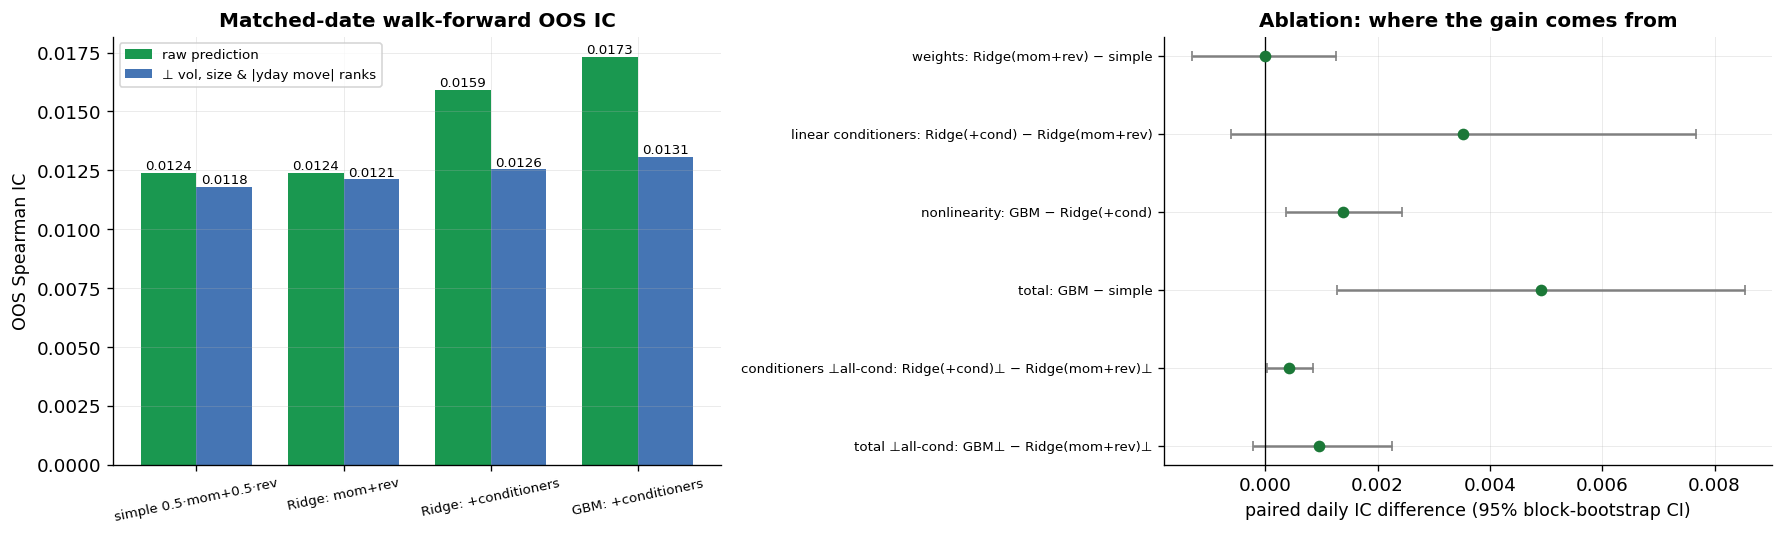

OOS IC on identical dates (N=4692):  raw | ⊥ all conditioners
  0 simple 0.5·mom+0.5·rev     +0.0124 | +0.0118   (raw IR 1.09)
  1 Ridge: mom+rev             +0.0124 | +0.0121   (raw IR 1.04)
  2 Ridge: +conditioners       +0.0159 | +0.0126   (raw IR 1.26)
  3 GBM: +conditioners         +0.0173 | +0.0131   (raw IR 1.54)
Factor references, same dates: low-vol rank IC +0.0098, size rank IC +0.0021, low-|yday move| IC +0.0063


,mean_diff,lo95,hi95
comparison,,,
weights: Ridge(mom+rev) − simple,-0.00000,-0.00131,0.00127
linear conditioners: Ridge(+cond) − Ridge(mom+rev),0.00352,-0.00061,0.00767
nonlinearity: GBM − Ridge(+cond),0.00139,0.00037,0.00244
total: GBM − simple,0.00491,0.00128,0.00854
conditioners ⊥all-cond: Ridge(+cond)⊥ − Ridge(mom+rev)⊥,0.00042,0.00003,0.00085
total ⊥all-cond: GBM⊥ − Ridge(mom+rev)⊥,0.00096,-0.00023,0.00225


Ridge(+conditioners) coefficients averaged over walk-forward folds (conditioners are ranks in [0,1]):


,mean_coef,share_of_folds_negative
mom_r,0.0056,0.0000
rev_r,0.0034,0.0000
f_svol,-0.0111,1.0000
f_size,0.0004,0.3684
f_absr,-0.0029,1.0000


  weights: Ridge(mom+rev) − simple                             -0.00000 [-0.00131, +0.00127] → CI spans 0
  linear conditioners: Ridge(+cond) − Ridge(mom+rev)           +0.00352 [-0.00061, +0.00767] → CI spans 0
  nonlinearity: GBM − Ridge(+cond)                             +0.00139 [+0.00037, +0.00244] → CI above 0
  total: GBM − simple                                          +0.00491 [+0.00128, +0.00854] → CI above 0
  conditioners ⊥all-cond: Ridge(+cond)⊥ − Ridge(mom+rev)⊥      +0.00042 [+0.00003, +0.00085] → CI above 0
  total ⊥all-cond: GBM⊥ − Ridge(mom+rev)⊥                      +0.00096 [-0.00023, +0.00225] → CI spans 0
Linear conditioner gain before vs after removing ALL conditioner exposure: +0.00352 → +0.00042 (12% remains).
Mean Ridge coefficient on f_svol = -0.0111 (negative = tilt toward low-volatility stocks; negative in 100% of folds).


In [28]:
from sklearn.linear_model import Ridge
try:
    from lightgbm import LGBMRegressor
    HAVE=True
except ImportError:
    from sklearn.ensemble import HistGradientBoostingRegressor
    HAVE=False

# Start from the universe-filtered core dataset, but construct all time-series conditioners on full history.
ml = load_stage("panel_feat").copy()
p_ml = load_stage("panel_clean").sort_values(["ticker","date"]).copy()
gm = p_ml.groupby("ticker", sort=False)
p_ml["f_svol"] = gm["ret_feature"].transform(lambda s:s.rolling(20,min_periods=15).std().shift(1))
p_ml["f_absr"] = gm["ret_feature"].transform(lambda s:s.abs().shift(1))
p_ml["f_size"] = np.log(p_ml["adv60"].where(p_ml["adv60"]>0))
ml = ml.merge(
    p_ml[["ticker","date","f_svol","f_size","f_absr"]],
    on=["ticker","date"], how="left", validate="one_to_one"
)
del p_ml, gm   # free memory; not used later

CORE = ["mom_r","rev_r"]; COND = ["f_svol","f_size","f_absr"]; FEATS = CORE + COND
for c in COND:
    ml[c] = ml.groupby("date")[c].rank(pct=True)      # cross-sectional ranks in [0, 1]
ml["y_rank"] = ml.groupby("date")["fwd_xs"].rank(pct=True)
ml["year"] = ml["date"].dt.year

# Training rows require an observed target. Prediction rows do NOT: this lets the later OOS portfolio
# form weights without conditioning today's stock selection on whether tomorrow's return happens to exist.
data = ml.dropna(subset=FEATS+["y_rank","fwd_xs"]).copy()

def gbm():
    if HAVE:
        return LGBMRegressor(
            n_estimators=200,max_depth=3,num_leaves=8,learning_rate=0.03,
            reg_alpha=1,reg_lambda=1,min_child_samples=200,verbose=-1
        )
    return HistGradientBoostingRegressor(
        max_depth=3,learning_rate=0.03,max_iter=200,l2_regularization=1,min_samples_leaf=200
    )

# Three-step ablation. Same rows, same yearly walk-forward folds, same per-date rank target.
MODELS = {
    "1 Ridge: mom+rev":       (lambda: Ridge(alpha=1.0), CORE),
    "2 Ridge: +conditioners": (lambda: Ridge(alpha=1.0), FEATS),
    "3 GBM: +conditioners":   (gbm, FEATS),
}
years = sorted(data["year"].unique())
P = {m: [] for m in MODELS}; COEF = []; oos_years = []
for yr in years:
    if yr < years[0] + 3:
        continue
    tr = data[data["year"] < yr]
    te_eval = data[data["year"] == yr]

    # Predict every feature-complete stock-day in the OOS year, even when its next-day return is missing.
    # IC evaluation later drops missing targets; portfolio weights do not use that future availability.
    te_all = ml.loc[
        (ml["year"] == yr) & ml[FEATS].notna().all(axis=1)
    ].copy()

    if len(tr) < 50000 or len(te_eval) < 1000 or len(te_all) < 1000:
        continue
    oos_years.append(yr)
    for name, (mk, cols) in MODELS.items():
        model = mk()
        model.fit(tr[cols], tr["y_rank"])
        pred = te_all[["ticker","date","fwd_ret","fwd_xs","f_svol","f_size","f_absr"]].copy()
        pred["pred"] = model.predict(te_all[cols])
        P[name].append(pred)
        if name.startswith("2"):
            COEF.append(pd.Series(model.coef_, index=cols, name=yr))

OOS = {name: pd.concat(fr, ignore_index=True) for name, fr in P.items()}
simple = ml.loc[
    ml["year"].isin(oos_years) & ml[FEATS].notna().all(axis=1),
    ["ticker","date","fwd_ret","fwd_xs","f_svol","f_size","f_absr","mom_r","rev_r"]
].copy()
simple["pred"] = 0.5*simple["mom_r"] + 0.5*simple["rev_r"]
OOS["0 simple 0.5·mom+0.5·rev"] = simple


def neutralize(frame, col="pred", on=("f_svol","f_size","f_absr")):
    # Per-date OLS residual: remove ALL three conditioner exposures jointly.
    out = pd.Series(np.nan, index=frame.index, dtype=float)
    for _, ix in frame.groupby("date", sort=False).groups.items():
        g = frame.loc[ix, [col, *on]].dropna()
        if len(g) <= len(on) + 2:
            continue
        X = np.column_stack([np.ones(len(g)), g[list(on)].to_numpy(dtype=float)])
        y = g[col].to_numpy(dtype=float)
        b, *_ = np.linalg.lstsq(X, y, rcond=None)
        out.loc[g.index] = y - X @ b
    return out
ORDER = ["0 simple 0.5·mom+0.5·rev", "1 Ridge: mom+rev", "2 Ridge: +conditioners", "3 GBM: +conditioners"]
IC, ICN = {}, {}
for k in ORDER:
    f = OOS[k].copy()
    f["pred_n"] = neutralize(f)
    IC[k] = daily_ic(f, "pred", "fwd_xs")
    ICN[k] = daily_ic(f, "pred_n", "fwd_xs")

# Force identical dates for every comparison.
common = sorted(set.intersection(*[set(s.index) for s in list(IC.values()) + list(ICN.values())]))
IC = {k: v.reindex(common) for k, v in IC.items()}
ICN = {k: v.reindex(common) for k, v in ICN.items()}

# Factor references on the same rows and dates: low-volatility rank and size rank as stand-alone predictors.
ref = OOS["1 Ridge: mom+rev"].copy()
ref["lowvol"] = -ref["f_svol"]
ref["low_abs_move"] = -ref["f_absr"]
ic_lowvol = daily_ic(ref, "lowvol", "fwd_xs").reindex(common)
ic_size = daily_ic(ref, "f_size", "fwd_xs").reindex(common)
ic_absr = daily_ic(ref, "low_abs_move", "fwd_xs").reindex(common)

S0, R1, R2, G3 = ORDER
PAIRS = {
    "weights: Ridge(mom+rev) − simple":                     (IC[R1], IC[S0]),
    "linear conditioners: Ridge(+cond) − Ridge(mom+rev)":   (IC[R2], IC[R1]),
    "nonlinearity: GBM − Ridge(+cond)":                     (IC[G3], IC[R2]),
    "total: GBM − simple":                                  (IC[G3], IC[S0]),
    "conditioners ⊥all-cond: Ridge(+cond)⊥ − Ridge(mom+rev)⊥": (ICN[R2], ICN[R1]),
    "total ⊥all-cond: GBM⊥ − Ridge(mom+rev)⊥":              (ICN[G3], ICN[R1]),
}
cmp_tab = pd.DataFrame(
    [(lab,) + block_mean_ci(a - b) for lab, (a, b) in PAIRS.items()],
    columns=["comparison","mean_diff","lo95","hi95"]
).set_index("comparison")
coef = pd.DataFrame(COEF)
coef_summary = pd.DataFrame({"mean_coef": coef.mean(), "share_of_folds_negative": (coef < 0).mean()})

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
x = np.arange(len(ORDER)); w = 0.38
raw_v = [IC[k].mean() for k in ORDER]; neu_v = [ICN[k].mean() for k in ORDER]
ax[0].bar(x - w/2, raw_v, w, color=C_GOOD, label="raw prediction")
ax[0].bar(x + w/2, neu_v, w, color=C_NEU, label="⊥ vol, size & |yday move| ranks")
for i, (a, b) in enumerate(zip(raw_v, neu_v)):
    ax[0].text(i - w/2, a, f"{a:.4f}", ha="center", va="bottom", fontsize=8)
    ax[0].text(i + w/2, b, f"{b:.4f}", ha="center", va="bottom", fontsize=8)
ax[0].set_xticks(x); ax[0].set_xticklabels([k.split(" ", 1)[1] for k in ORDER], fontsize=8, rotation=12)
ax[0].set_ylabel("OOS Spearman IC"); ax[0].legend(fontsize=8)
ax[0].set_title("Matched-date walk-forward OOS IC")
yy = np.arange(len(cmp_tab))
ax[1].errorbar(cmp_tab["mean_diff"], yy, xerr=[(cmp_tab["mean_diff"] - cmp_tab["lo95"]).clip(lower=0), (cmp_tab["hi95"] - cmp_tab["mean_diff"]).clip(lower=0)],
               fmt="o", color=C_COMBO, ecolor="gray", capsize=3)
ax[1].axvline(0, color="k", lw=0.8)
ax[1].set_yticks(yy); ax[1].set_yticklabels(cmp_tab.index, fontsize=8); ax[1].invert_yaxis()
ax[1].set_xlabel("paired daily IC difference (95% block-bootstrap CI)")
ax[1].set_title("Ablation: where the gain comes from")
plt.tight_layout(); plt.show()

print(f"OOS IC on identical dates (N={len(common)}):  raw | ⊥ all conditioners")
for k in ORDER:
    print(f"  {k:28s} {IC[k].mean():+.4f} | {ICN[k].mean():+.4f}   (raw IR {IC[k].mean()/IC[k].std()*np.sqrt(252):.2f})")
print(f"Factor references, same dates: low-vol rank IC {ic_lowvol.mean():+.4f}, size rank IC {ic_size.mean():+.4f}, low-|yday move| IC {ic_absr.mean():+.4f}")
display(cmp_tab.round(5))
print("Ridge(+conditioners) coefficients averaged over walk-forward folds (conditioners are ranks in [0,1]):")
display(coef_summary.round(4))
for lab, r in cmp_tab.iterrows():
    if r["lo95"] > 0:
        v = "CI above 0"
    elif r["hi95"] < 0:
        v = "CI below 0"
    else:
        v = "CI spans 0"
    print(f"  {lab:60s} {r['mean_diff']:+.5f} [{r['lo95']:+.5f}, {r['hi95']:+.5f}] → {v}")
g_raw = cmp_tab.loc["linear conditioners: Ridge(+cond) − Ridge(mom+rev)", "mean_diff"]
g_neu = cmp_tab.loc["conditioners ⊥all-cond: Ridge(+cond)⊥ − Ridge(mom+rev)⊥", "mean_diff"]
print(f"Linear conditioner gain before vs after removing ALL conditioner exposure: {g_raw:+.5f} → {g_neu:+.5f}"
      + (f" ({g_neu/g_raw:.0%} remains)." if g_raw > 0 else "."))
print(f"Mean Ridge coefficient on f_svol = {coef_summary.loc['f_svol','mean_coef']:+.4f} "
      f"(negative = tilt toward low-volatility stocks; negative in {coef_summary.loc['f_svol','share_of_folds_negative']:.0%} of folds).")

# cmp_tab rows, in order: weights, linear conditioners, nonlinearity, total, conditioners⊥, total⊥
RESULTS.update(
    ml_simple=float(IC[S0].mean()), ml_ridge_core=float(IC[R1].mean()),
    ml_ridge_cond=float(IC[R2].mean()), ml_gbm=float(IC[G3].mean()),
    ml_cond_gain=float(cmp_tab.iloc[1]["mean_diff"]), ml_cond_gain_lo=float(cmp_tab.iloc[1]["lo95"]),
    ml_gbm_minus_ridge=float(cmp_tab.iloc[2]["mean_diff"]), ml_gbm_minus_ridge_lo=float(cmp_tab.iloc[2]["lo95"]),
    ml_gbm_minus_ridge_hi=float(cmp_tab.iloc[2]["hi95"]),
    ml_cond_gain_neutral=float(cmp_tab.iloc[4]["mean_diff"]),
    ml_total_neutral=float(cmp_tab.iloc[5]["mean_diff"]), ml_total_neutral_lo=float(cmp_tab.iloc[5]["lo95"]),
    ml_total_neutral_hi=float(cmp_tab.iloc[5]["hi95"]),
)


**What the ablation shows.**

- **Prediction:** the raw OOS GBM is the strongest predictor in this feature set (IC +0.0173 versus +0.0124 for the
  simple momentum/reversal blend). That is the answer if the objective is predictive accuracy.
- **Better core weights add nothing.** Ridge on momentum + reversal matches the 50/50 blend (+0.0124 for both).
- **Attribution:** adding volatility, size and prior-day move lifts Ridge to +0.0159, but only about 12% of that
  conditioner gain survives removing those three linear exposures. Ridge loads negatively on volatility and on the
  prior-day move in every fold.
- **Nonlinearity:** GBM beats Ridge(+conditioners) on raw predictions by +0.0014. After the attribution neutralization,
  GBM's total gain over momentum + reversal is +0.0010 [−0.0002, +0.0023].
- **Interpretation:** the fitted models use the low-volatility/state information heavily. That explains much of the raw
  gain; it does **not** imply the better raw predictor should be discarded. In production, those exposures would be made
  explicit in the risk model and portfolio optimizer rather than erased merely to improve an attribution label.

### 6.3b Post-review OOS portfolio check: raw prediction versus attribution

A higher IC is useful, but the natural follow-up is whether the **raw** improvement survives a simple portfolio
construction. This post-review cell compares the raw 50/50 core predictor with the raw GBM over the same OOS years.

This is deliberately **not** a neutralized-model trading test. Neutralization answers attribution; trading should start
from the predictor you would actually consider deploying. Weights are formed without conditioning on whether the next-day
return for an individual stock is available. Missing realized returns are handled after weights are set, consistent with
§9.

This remains a research backtest, not an execution model: no impact, borrow, capacity or auction slippage is included.

,ann_return_%,ann_vol_%,Sharpe,max_drawdown_%,turnover_per_day,break_even_bps,positive_day_%,days
model,,,,,,,,
simple 0.5·mom+0.5·rev,6.85,12.12,0.566,-27.99,0.621,4.38,53.5,4691
GBM + conditioners (raw),1.75,12.44,0.141,-38.65,0.702,0.99,51.8,4691


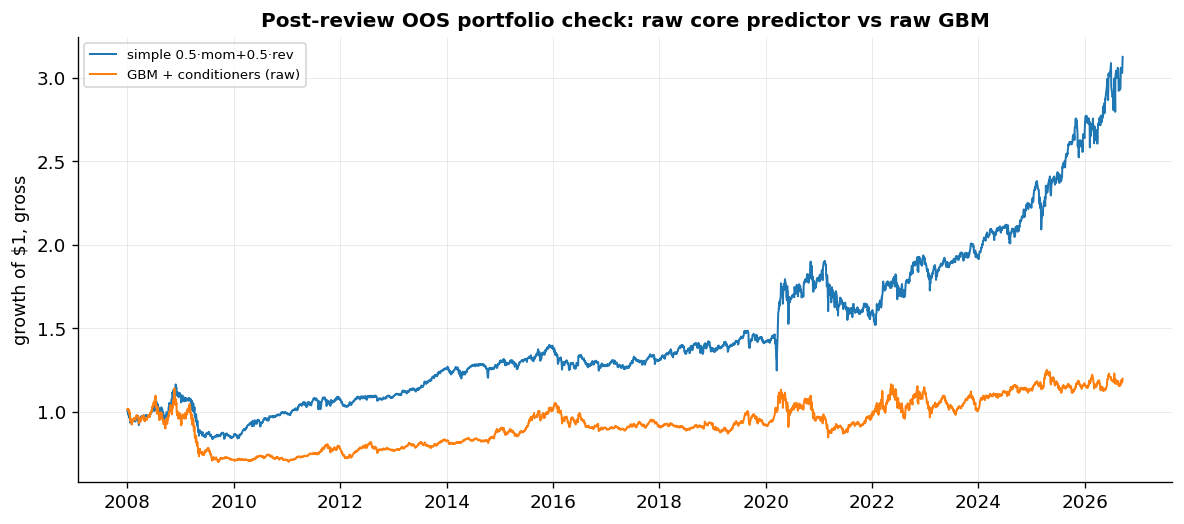

Interpretation: use the raw-model table for prediction/economic value; use neutralization in §6.3 only for attribution.


In [29]:
# Post-review OOS portfolio comparison: raw simple core vs raw GBM.
# Uses predictions generated in §6.3 for ALL feature-complete OOS stock-days, including rows with missing future returns.

risk_ml = load_stage("panel_clean").sort_values(["ticker", "date"]).copy()
risk_ml["date"] = pd.to_datetime(risk_ml["date"])
risk_ml["vol20"] = risk_ml.groupby("ticker", sort=False)["ret_feature"].transform(
    lambda s: s.rolling(20, min_periods=15).std().shift(1)
)

# Date-level no-next-session rule, used only as a stand-in for an exchange calendar.
feat_ml_cov = load_stage("panel_feat")
_next_cov_ml = feat_ml_cov["fwd_ret"].notna().groupby(feat_ml_cov["date"]).mean()
_no_next_ml = _next_cov_ml[_next_cov_ml < 0.5].index

def _raw_prediction_book(pred_frame, label):
    z = pred_frame.merge(
        risk_ml[["ticker", "date", "vol20"]],
        on=["ticker", "date"], how="left", validate="one_to_one"
    )
    z = z[~z["date"].isin(_no_next_ml)].copy()

    # Eligibility for weights uses only today's prediction and lagged risk estimate.
    z = z[z["pred"].notna() & z["vol20"].gt(0)].copy()

    def _book_day(g):
        if len(g) < 50:
            return None
        qlo, qhi = g["pred"].quantile([0.1, 0.9])
        lo = g["pred"] <= qlo
        hi = g["pred"] >= qhi
        out = g[["date", "ticker", "pred", "fwd_ret", "vol20"]].copy()
        out["w"] = 0.0
        inv = 1.0 / out["vol20"]
        if hi.sum() > 0:
            out.loc[hi, "w"] = inv[hi] / inv[hi].sum() * 0.5
        if lo.sum() > 0:
            out.loc[lo, "w"] = -inv[lo] / inv[lo].sum() * 0.5
        return out

    pieces = [_book_day(g) for _, g in z.groupby("date", sort=True)]
    b = pd.concat([x for x in pieces if x is not None], ignore_index=True)

    # Future-return availability does not affect weights. Missing realized returns are set to zero only after formation.
    b["ret_eval"] = b["fwd_ret"].fillna(0.0)
    pnl = b.groupby("date").apply(lambda d: (d["w"] * d["ret_eval"]).sum()).sort_index()

    wt = b.pivot_table(index="date", columns="ticker", values="w", fill_value=0.0).sort_index()
    turnover = wt.diff().abs().sum(axis=1)
    if len(turnover):
        turnover.iloc[0] = wt.iloc[0].abs().sum()
    turnover = turnover.reindex(pnl.index).fillna(0.0)

    ann_ret = pnl.mean() * 252
    ann_vol = pnl.std() * np.sqrt(252)
    shp = ann_ret / ann_vol if ann_vol > 0 else np.nan
    wealth = (1.0 + pnl).cumprod()
    dd = wealth / wealth.cummax() - 1.0
    be = pnl.mean() / turnover.mean() * 1e4 if turnover.mean() > 0 else np.nan

    metrics = {
        "model": label,
        "ann_return_%": ann_ret * 100,
        "ann_vol_%": ann_vol * 100,
        "Sharpe": shp,
        "max_drawdown_%": dd.min() * 100,
        "turnover_per_day": turnover.mean(),
        "break_even_bps": be,
        "positive_day_%": (pnl > 0).mean() * 100,
        "days": len(pnl),
    }
    return metrics, pnl, turnover

_ml_models_for_book = {
    "simple 0.5·mom+0.5·rev": OOS[S0],
    "GBM + conditioners (raw)": OOS[G3],
}

ml_book_metrics = []
ml_book_pnl = {}
ml_book_turn = {}
for lab, frame in _ml_models_for_book.items():
    m, p, t = _raw_prediction_book(frame, lab)
    ml_book_metrics.append(m)
    ml_book_pnl[lab] = p
    ml_book_turn[lab] = t

ml_book_tab = pd.DataFrame(ml_book_metrics).set_index("model")
display(ml_book_tab.round({
    "ann_return_%": 2, "ann_vol_%": 2, "Sharpe": 3, "max_drawdown_%": 2,
    "turnover_per_day": 3, "break_even_bps": 2, "positive_day_%": 1
}))

fig, ax = plt.subplots(figsize=(10, 4.5))
for lab, p in ml_book_pnl.items():
    ax.plot((1 + p).cumprod().index, (1 + p).cumprod().values, lw=1.2, label=lab)
ax.set_title("Post-review OOS portfolio check: raw core predictor vs raw GBM")
ax.set_ylabel("growth of $1, gross")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print("Interpretation: use the raw-model table for prediction/economic value; use neutralization in §6.3 only for attribution.")
RESULTS["postreview_ml_portfolio_built"] = True


### 6.4 Summary

- **Standalone gate.** Gap-fade, MAX, skewness and idio-vol pass; intraday reversal fails on its correlation with
  reversal (0.37); close location and vol term structure fail on IC.
- **Unique information.** Only the low-volatility family (idio-vol, MAX) survives the multiple-testing correction.
- **ML prediction.** The raw GBM is the strongest OOS predictor in this feature set.
- **ML attribution.** Much of that gain is associated with volatility/state exposures; after removing those exposures,
  the incremental stock-specific gain is not distinguishable from zero.
- **Deployment implication.** Attribution and prediction are different objectives. A production system would make those
  exposures explicit in portfolio construction and the risk model rather than automatically discarding a better raw
  predictor.
- **Core discipline.** None of the ML or post-review sensitivity results is fed back into the frozen momentum/reversal
  signal.

---
# 7. Evaluation & results
### *Explicit criteria; walk-forward; the most-recent period; block-bootstrap uncertainty*

**Primary metric:** Spearman cross-sectional rank IC of next-day relative return (rank both sides). **Secondary:** IC
stability by year/period, information-ratio-style scaling, and implementation break-even cost.

For interpretation, this notebook uses reference bands such as IC ≈ 0.005 as economically noticeable and IC ≈ 0.010
as strong for this daily cross-sectional exercise. These bands are **heuristics set during the research, not thresholds fixed before seeing the current data**.

**Criteria fixed in advance for the next survivorship-safe CRSP/security-master rebuild (before running it):**

- **Primary replication:** walk-forward mean daily Spearman IC > **+0.005** and 21-session block-bootstrap 95% CI entirely > 0.
- **Stability:** positive mean IC in each of 2005–17, 2018–21 and 2022–26; no period below **−0.002**.
- **Core-mechanism replication:** momentum and reversal both have non-negative standalone IC; reversal's high-minus-low
  abnormal-volume IC difference is positive.
- **Failure rule:** if the primary IC CI includes zero, or the sign reverses after a proper historical common-stock filter,
  treat the current Stooq result as non-replicated rather than retuning horizons/filters on CRSP.

These thresholds are prospective for the **next** dataset; they are not retroactively claimed as preregistration here.

**On the recent period.** 2022–2026 was inspected during development, so we do **not**
call it a pristine locked holdout. We report it separately as **"the most recent period, seen during development."**


[save_stage] panel_live: 4,904,981 rows, 36 columns → /content/drive/MyDrive/NYSE stocks data/trexquant_ohlcv_v11_faculty_review/panel_live.parquet


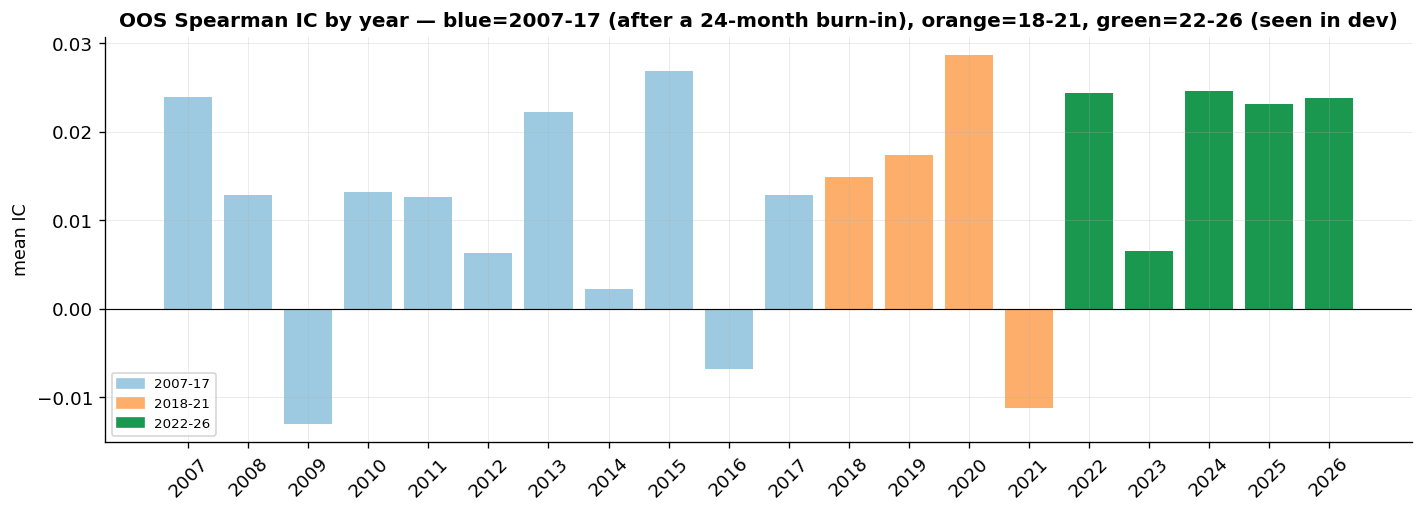

Walk-forward Spearman IC by period:
  full 07-26          : IC=+0.0131  IR= 1.09  N=4943
  2007-17             : IC=+0.0103  IR= 0.99  N=2769
  2018-21             : IC=+0.0125  IR= 0.85  N=1008
  2022-26 (recent)    : IC=+0.0203  IR= 1.54  N=1166


In [30]:
from scipy.stats import spearmanr
feat=load_stage("panel_feat")
def xs_rank(s,by):
    r=s.groupby(by).rank(pct=True); return (r-0.5)*2
def sic(frame,sig="combo_r",tgt="fwd_xs"):
    d=frame.dropna(subset=[sig,tgt])
    return d.groupby("date").apply(lambda x: spearmanr(x[sig],x[tgt]).correlation if len(x)>=50 and x[sig].nunique()>2 else np.nan).dropna()
df=feat.copy(); df["ym"]=df["date"].dt.to_period("M")
def mic(sig):
    d=df.dropna(subset=[sig,"fwd_xs"])
    daily=d.groupby("date").apply(lambda x: spearmanr(x[sig],x["fwd_xs"]).correlation if len(x)>=50 and x[sig].nunique()>2 else np.nan)
    return daily.groupby(daily.index.to_period("M")).mean()
SIG=["mom_r","rev_r"]; icm=pd.DataFrame({s:mic(s) for s in SIG})
months=np.sort(df["ym"].unique()); TRAIN=24; df["combo"]=np.nan
for i,m in enumerate(months):
    if i<TRAIN: continue
    past=icm.loc[icm.index<m,SIG]
    if len(past)<TRAIN: continue
    w=past.mean().clip(lower=0); w=w/w.sum() if w.sum()>0 else pd.Series(0.5,index=SIG)
    mask=df["ym"]==m; df.loc[mask,"combo"]=sum(df.loc[mask,s]*w[s] for s in SIG)
live=df.dropna(subset=["combo"]).copy(); live["combo_r"]=xs_rank(live["combo"],live["date"])
save_stage(live, "panel_live")
ic=sic(live)
ic_res=ic[(ic.index>="2005")&(ic.index<="2017-12-31")]; ic_val=ic[(ic.index>="2018")&(ic.index<="2021-12-31")]; ic_rec=ic[(ic.index>="2022")]
yr=ic.groupby(ic.index.year).mean()
fig,ax=plt.subplots(figsize=(12,4.4))
cols=["#9ecae1" if y<=2017 else ("#fdae6b" if y<=2021 else C_GOOD) for y in yr.index]
ax.bar(yr.index.astype(str),yr.values,color=cols); ax.axhline(0,color="k",lw=0.7)
ax.set_title("OOS Spearman IC by year — blue=2007-17 (after a 24-month burn-in), orange=18-21, green=22-26 (seen in dev)")
ax.set_ylabel("mean IC"); ax.tick_params(axis="x",rotation=45)
import matplotlib.patches as mp
ax.legend(handles=[mp.Patch(color="#9ecae1",label="2007-17"),mp.Patch(color="#fdae6b",label="2018-21"),mp.Patch(color=C_GOOD,label="2022-26")],fontsize=8)
plt.tight_layout(); plt.show()
def rpt(x,l): print(f"  {l:20s}: IC={x.mean():+.4f}  IR={x.mean()/x.std()*np.sqrt(252):5.2f}  N={len(x)}")
print("Walk-forward Spearman IC by period:"); rpt(ic,"full 07-26"); rpt(ic_res,"2007-17"); rpt(ic_val,"2018-21"); rpt(ic_rec,"2022-26 (recent)")

RESULTS.update(wf_ic=float(ic.mean()), wf_ir=float(ic.mean()/ic.std()*np.sqrt(252)), wf_days=int(len(ic)),
               wf_2005_17=float(ic_res.mean()), wf_2018_21=float(ic_val.mean()), wf_2022_26=float(ic_rec.mean()))


**By period.** Walk-forward Spearman IC is **+0.0131** overall (IR 1.09, 4,943 days): **+0.0103** in 2007–17,
**+0.0125** in 2018–21 and **+0.0203** in 2022–26. The walk-forward needs 24 months of history before its first weights,
so it starts in 2007.

- **2022–26 is not a pristine holdout.** It was inspected during development. The weights applied on each date use only
  prior months, but the research design saw the full sample, so treat recent strength as descriptive.
- **Much of the recent strength is the universe.** The top 1,000 is 14–20% of eligible names in 2022–26 versus about half
  in 2005–09 (§3.4a), and the signal is stronger in more liquid names (§8.1). In the top 250, the IC barely changes
  between 2005–17 and 2022–26 (+0.0006 with fixed weights; §8.1b).


### 7.2 Uncertainty — block bootstrap

In [31]:
def bbci(series,block=21,n=2000,seed=1):
    rng=np.random.default_rng(seed); x=series.values; nn=len(x); nb=int(np.ceil(nn/block)); ms=[]
    for _ in range(n):
        st=rng.integers(0,nn-block,size=nb); s=np.concatenate([x[i:i+block] for i in st])[:nn]; ms.append(s.mean())
    lo,hi=np.percentile(ms,[2.5,97.5]); return series.mean(),lo,hi
for lbl,s in [("full",ic),("2022-26",ic_rec)]:
    m,lo,hi=bbci(s); print(f"{lbl:10s}: IC={m:+.4f}, 95% block-bootstrap CI=[{lo:+.4f},{hi:+.4f}] → {'distinguishable from 0' if lo>0 else 'NOT distinguishable from 0'}")

_, _lo, _hi = bbci(ic);     RESULTS.update(wf_ci_lo=float(_lo), wf_ci_hi=float(_hi))
_, _lo, _hi = bbci(ic_rec); RESULTS.update(recent_ci_lo=float(_lo), recent_ci_hi=float(_hi))


full      : IC=+0.0131, 95% block-bootstrap CI=[+0.0083,+0.0178] → distinguishable from 0
2022-26   : IC=+0.0203, 95% block-bootstrap CI=[+0.0105,+0.0288] → distinguishable from 0


**Is the IC distinguishable from zero?** Yes, in this sample, under a 21-day block bootstrap.
Full-sample mean IC is **+0.0131** with 95% CI **[+0.0083,+0.0178]**; the 2022–2026 period is **+0.0203** with CI
**[+0.0105,+0.0288]**. Both intervals exclude zero.

The right interpretation is **"statistically detectable, modest predictive information"**, not "large edge." The
bootstrap addresses serial dependence in daily IC more realistically than treating all 4,943 days as independent, but it does
not cure researcher degrees of freedom, survivorship bias, or vendor-data errors.


---
# 8. Robustness, falsification & the overnight finding

§8.1 attacks the signal: universe size, sample halves, a point-in-time quality subset, dropping current-ETF tickers and
split-like returns, and a shuffled-label sanity check. §8.1b asks whether the stronger recent IC is a universe-composition
effect. §8.2 checks microstructure. §8.3 splits the next-session return into overnight and intraday legs, separately for
momentum and reversal, and checks index-rebalance closes. §8.4 tests two predictions of the liquidity-pressure story.

All feature construction here happens on the **full continuous panel before filtering to each universe**, so rolling
windows and shifts always see true trading-day history.


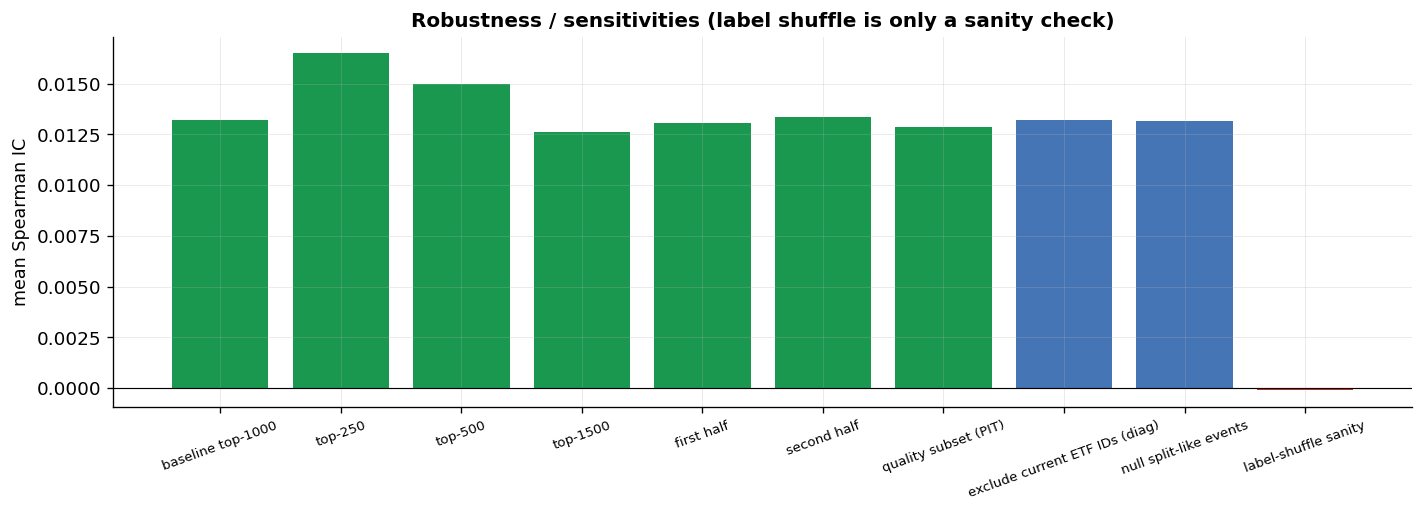

Label-shuffle IC=-0.00010; baseline IC=+0.0132.
The shuffle being ~0 is expected by construction and does NOT establish absence of lookahead; use adjacency + skip tests for timing.
  baseline top-1000                IC +0.0132
  top-250                          IC +0.0165
  top-500                          IC +0.0150
  top-1500                         IC +0.0126
  first half                       IC +0.0130
  second half                      IC +0.0133
  quality subset (PIT)             IC +0.0129
  exclude current ETF IDs (diag)   IC +0.0132
  null split-like events           IC +0.0132
  label-shuffle sanity             IC -0.0001


In [32]:
import os
clean=load_stage("panel_clean").sort_values(["ticker","date"]).copy()
clean["date"] = pd.to_datetime(clean["date"])
def xs_rank(s,by):
    r=s.groupby(by).rank(pct=True); return (r-0.5)*2

# Build features on FULL panel ONCE, then filter per universe.
def build_full(panel):
    p=panel.sort_values(["ticker","date"]).copy()
    gg=p.groupby("ticker", sort=False)
    p["mkt_f"]=p.groupby("date")["ret_feature"].transform("mean")
    p["rrf"]=p["ret_feature"]-p["mkt_f"]
    p["mom"]=gg["rrf"].transform(lambda s:s.rolling(231,min_periods=120).sum().shift(21))
    for h in [3,5,10]:
        p[f"rev{h}"]=-gg["ret_feature"].transform(lambda s:s.rolling(h).sum().shift(1))
    p["rev"]=p[["rev3","rev5","rev10"]].mean(axis=1)

    _, next_map = make_market_date_maps(p["date"])
    adj_next = next_adjacent_mask(p, next_map)
    p["fwd_ret"] = gg["ret_actual"].shift(-1).where(adj_next)
    return p

full=build_full(clean)

def sig_ic(p,mask,which="combo"):
    f=p.loc[mask].copy()
    f["mom_r"]=xs_rank(f["mom"],f["date"]); f["rev_r"]=xs_rank(f["rev"],f["date"])
    col={"combo":0.5*f["mom_r"]+0.5*f["rev_r"],"rev":f["rev_r"],"mom":f["mom_r"]}[which]
    f["s_r"]=xs_rank(col,f["date"])
    f["fwd_xs"]=f["fwd_ret"]-f.groupby("date")["fwd_ret"].transform("mean")
    d=f.dropna(subset=["s_r","fwd_xs"])
    return d.groupby("date").apply(
        lambda x:spearmanr(x["s_r"],x["fwd_xs"]).correlation if len(x)>=50 else np.nan
    ).dropna()

results={}
def rec(n,ic):
    results[n]=(ic.mean(),ic.mean()/ic.std()*np.sqrt(252))

ic_base=sig_ic(full,full["in_universe"]); rec("baseline top-1000",ic_base)
full["rk"]=full.loc[full["elig"]].groupby("date")["adv60"].rank(ascending=False,method="first")
for N in [250,500,1500]:
    rec(f"top-{N}",sig_ic(full,full["elig"]&(full["rk"]<=N)))

mid=full.loc[full["in_universe"],"date"].quantile(0.5)
rec("first half",sig_ic(full,full["in_universe"]&(full["date"]<mid)))
rec("second half",sig_ic(full,full["in_universe"]&(full["date"]>=mid)))

full["hist_n"]=full.groupby("ticker", sort=False).cumcount()+1
rec("quality subset (PIT)",sig_ic(full,full["in_universe"]&(full["hist_n"]>=500)))

# Security-type sensitivity using CURRENT ETF flags saved by §3.4a. Diagnostic only: not historically point-in-time.
etf_csv = f"{OUT}/current_etf_audit_tickers.csv"
if os.path.exists(etf_csv):
    etf_now = set(pd.read_csv(etf_csv)["ticker"].astype(str))
    rec("exclude current ETF IDs (diag)", sig_ic(full, full["in_universe"] & ~full["ticker"].isin(etf_now)))

# Split-like sensitivity: null canonical-ratio events in BOTH target and feature returns, rebuild features, compare.
if "split_like" in clean.columns:
    clean_ns = clean.copy()
    clean_ns.loc[clean_ns["split_like"], ["ret_actual","ret_feature"]] = np.nan
    full_ns = build_full(clean_ns)
    rec("null split-like events", sig_ic(full_ns, full_ns["in_universe"]))

# Label-shuffle SANITY CHECK only; by construction this should be ~0 and is not a leak test.
base=full.loc[full["in_universe"]].copy()
base["mom_r"]=xs_rank(base["mom"],base["date"]); base["rev_r"]=xs_rank(base["rev"],base["date"])
base["s_r"]=xs_rank(0.5*base["mom_r"]+0.5*base["rev_r"],base["date"])
base["fwd_xs"]=base["fwd_ret"]-base.groupby("date")["fwd_ret"].transform("mean")
pl=base.dropna(subset=["s_r","fwd_xs"]).copy(); rng=np.random.default_rng(42)
pl["shuf"]=pl.groupby("date")["fwd_xs"].transform(lambda s:rng.permutation(s.values))
ic_plac=pl.groupby("date").apply(
    lambda x:spearmanr(x["s_r"],x["shuf"]).correlation if len(x)>=50 else np.nan
).dropna()
rec("label-shuffle sanity",ic_plac)

order=["baseline top-1000","top-250","top-500","top-1500","first half","second half","quality subset (PIT)"]
for extra in ["exclude current ETF IDs (diag)", "null split-like events"]:
    if extra in results: order.append(extra)
order.append("label-shuffle sanity")
ics=[results[k][0] for k in order]
fig,ax=plt.subplots(figsize=(12,4.4))
cols=[C_BAD if "shuffle" in k else (C_NEU if "diag" in k or "split" in k else C_GOOD) for k in order]
ax.bar(range(len(order)),ics,color=cols); ax.axhline(0,color="k",lw=0.7)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order,fontsize=8,rotation=20); ax.set_ylabel("mean Spearman IC")
ax.set_title("Robustness / sensitivities (label shuffle is only a sanity check)")
plt.tight_layout(); plt.show()
print(f"Label-shuffle IC={ic_plac.mean():+.5f}; baseline IC={ic_base.mean():+.4f}.")
print("The shuffle being ~0 is expected by construction and does NOT establish absence of lookahead; use adjacency + skip tests for timing.")

RESULTS.update(baseline_ic=float(results["baseline top-1000"][0]), top250_ic=float(results["top-250"][0]),
               top500_ic=float(results["top-500"][0]), top1500_ic=float(results["top-1500"][0]), shuffle_ic=float(results["label-shuffle sanity"][0]))
if "exclude current ETF IDs (diag)" in results:
    RESULTS["ic_ex_current_etfs"] = float(results["exclude current ETF IDs (diag)"][0])
if "null split-like events" in results:
    RESULTS["ic_null_split_like"] = float(results["null split-like events"][0])
for k in order:
    print(f"  {k:32s} IC {results[k][0]:+.4f}")


**Result.** The baseline IC is +0.0132. It rises as the universe gets more liquid (+0.0150 in the top 500, +0.0165 in
the top 250) and dips slightly in the top 1,500 (+0.0126). It holds in both sample halves and in the point-in-time
quality subset. Dropping current-ETF tickers or split-like returns leaves it at +0.0132, and shuffled labels give an IC
of about zero, as they must by construction.


### 8.1b Is the stronger 2022–26 IC a universe-composition effect?

§3.4a shows the top 1,000 covering about half of eligible names in 2005–09 but only 14–20% in 2022–26, and §8.1 shows
the signal is stronger in more liquid names. So the recent universe alone could raise IC. This cell compares eras under
three universe definitions: the baseline top 1,000, a **constant-depth** universe (the most liquid 20% of eligible names
each day) and the **top 250** (large caps in every era). All three use the fixed 50/50 blend, so the comparison isolates
the universe; comparing the baseline row with §7's walk-forward numbers also shows how much of the recent strength comes
from the walk-forward weights.


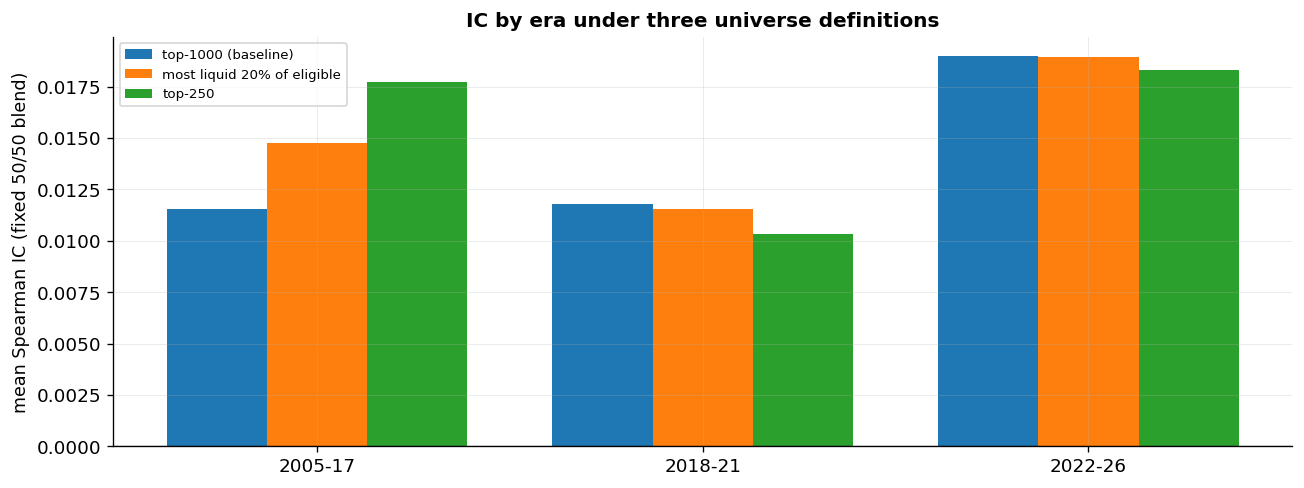

Mean daily IC by era:


era,2005-17,2018-21,2022-26,2022-26 minus 2005-17
universe,,,,
top-1000 (baseline),0.0115,0.0118,0.0190,0.0074
most liquid 20% of eligible,0.0148,0.0116,0.0189,0.0042
top-250,0.0177,0.0103,0.0183,0.0006


Median names per day:


era,2005-17,2018-21,2022-26
universe,,,
top-1000 (baseline),1000.0,1000.0,1000.0
most liquid 20% of eligible,459.0,747.0,1070.0
top-250,250.0,250.0,250.0


2022-26 minus 2005-17 IC: top-1000 +0.0074; most liquid 20% +0.0042; top-250 +0.0006.
The walk-forward blend in §7 gives +0.0100 for the same comparison. It starts two years later and uses fitted weights, so its difference from the fixed-weight top-1000 gap mainly reflects the weights.
With universe depth held constant, the recent-period gap partly survives (+0.0042 vs +0.0074 for the baseline top 1,000).


In [33]:
# Universe definitions that hold "depth" fixed through time, versus the baseline.
# Computed on eligible rows only and kept out of `full` to save memory.
_el = full.loc[full["elig"], ["date", "rk", "adv60"]]
_rk_frac = _el["rk"] / _el.groupby("date")["adv60"].transform("count")
depth20 = pd.Series(False, index=full.index)
depth20.loc[_rk_frac.index] = (_rk_frac <= 0.20).to_numpy()
del _el, _rk_frac
ERAS = {"2005-17": ("2005-01-01", "2017-12-31"), "2018-21": ("2018-01-01", "2021-12-31"),
        "2022-26": ("2022-01-01", "2026-12-31")}
UNIVERSES = {
    "top-1000 (baseline)": full["in_universe"],
    "most liquid 20% of eligible": depth20,
    "top-250": full["elig"] & (full["rk"] <= 250),
}
era_rows, size_rows = [], []
for un, mask in UNIVERSES.items():
    mask = mask.fillna(False).astype(bool)
    ic_u = sig_ic(full, mask)
    n_day = mask.groupby(full["date"]).sum()
    for en, (a, b) in ERAS.items():
        s = ic_u[(ic_u.index >= a) & (ic_u.index <= b)]
        nd = n_day[(n_day.index >= a) & (n_day.index <= b)]
        era_rows.append(dict(universe=un, era=en, IC=s.mean(), days=len(s)))
        size_rows.append(dict(universe=un, era=en, median_names=nd.median()))
era_tab = (pd.DataFrame(era_rows).pivot(index="universe", columns="era", values="IC")
           .reindex(index=list(UNIVERSES), columns=list(ERAS)))
era_tab["2022-26 minus 2005-17"] = era_tab["2022-26"] - era_tab["2005-17"]
size_tab = (pd.DataFrame(size_rows).pivot(index="universe", columns="era", values="median_names")
            .reindex(index=list(UNIVERSES), columns=list(ERAS)))

fig, ax = plt.subplots(figsize=(11, 4.2))
xx = np.arange(len(ERAS)); ww = 0.26
for j, un in enumerate(UNIVERSES):
    ax.bar(xx + (j-1)*ww, era_tab.loc[un, list(ERAS)].values, ww, label=un)
ax.set_xticks(xx); ax.set_xticklabels(list(ERAS)); ax.axhline(0, color="k", lw=0.7)
ax.set_ylabel("mean Spearman IC (fixed 50/50 blend)"); ax.legend(fontsize=8)
ax.set_title("IC by era under three universe definitions")
plt.tight_layout(); plt.show()
print("Mean daily IC by era:"); display(era_tab.round(4))
print("Median names per day:"); display(size_tab.round(0))

_g = era_tab["2022-26 minus 2005-17"]
g_base, g_depth, g_250 = float(_g.iloc[0]), float(_g.iloc[1]), float(_g.iloc[2])
RESULTS.update(era_gap_top1000=g_base, era_gap_const_depth=g_depth, era_gap_top250=g_250,
               era_2005_17_top1000=float(era_tab.iloc[0]["2005-17"]), era_2022_26_top1000=float(era_tab.iloc[0]["2022-26"]),
               era_2005_17_top250=float(era_tab.iloc[2]["2005-17"]), era_2022_26_top250=float(era_tab.iloc[2]["2022-26"]))
print(f"2022-26 minus 2005-17 IC: top-1000 {g_base:+.4f}; most liquid 20% {g_depth:+.4f}; top-250 {g_250:+.4f}.")
if "wf_2022_26" in RESULTS:
    print(f"The walk-forward blend in §7 gives {RESULTS['wf_2022_26'] - RESULTS['wf_2005_17']:+.4f} for the same comparison. "
          "It starts two years later and uses fitted weights, so its difference from the fixed-weight top-1000 gap "
          "mainly reflects the weights.")
if np.isfinite(g_base) and g_base > 0.001 and np.isfinite(g_depth):
    share = g_depth / g_base
    if share >= 0.67:   verdict = "mostly survives"
    elif share >= 0.33: verdict = "partly survives"
    elif share >= 0:    verdict = "largely disappears"
    else:               verdict = "reverses sign"
    RESULTS["era_gap_share_const_depth"] = float(share)
    print(f"With universe depth held constant, the recent-period gap {verdict} "
          f"({g_depth:+.4f} vs {g_base:+.4f} for the baseline top 1,000).")
else:
    print("The baseline top-1000 shows no meaningful recent-period gap to decompose.")


**Result.** Much of the stronger recent IC comes from what the universe contains, not from a stronger signal.

- With fixed 50/50 weights, the top 1,000's IC goes from +0.0115 in 2005–17 to +0.0190 in 2022–26, a gap of **+0.0074**.
  The walk-forward gap in §7 is larger (+0.0100), partly from the fitted weights and partly because it starts in 2007.
- Holding depth constant (the most liquid 20% of eligible names each day) shrinks the gap to **+0.0042**. In the top 250,
  large caps in every era, it is **+0.0006** (+0.0177 then, +0.0183 now): essentially no change.
- Behind that: in 2005–17 the IC falls as the universe reaches deeper (from +0.0177 in the top 250 to +0.0115 in the top
  1,000), while in 2022–26 it is flat at about +0.019. Early on, the top 1,000 reached much smaller names (the 1,000th
  traded about \$2M a day in 2005, versus \$89M in 2026), and §8.1 shows the signal is weaker in less liquid names.
- So I don't claim the signal strengthened. What survives is narrower: in 2022–26 the signal is about as strong across
  the top 1,000 as in the top 250. The era gaps have no confidence intervals, and the 2022–26 interval alone is wide
  (§7.2: [+0.0105, +0.0288]).


### 8.2 Microstructure: liquidity quintiles and reversal persistence

Reversal is built on the full panel and then filtered, so its rolling windows are true trading days, and the IC here is
reversal alone. Quintiles rank names by trailing ADV within each day (Q1 = most liquid). An illiquid bid-ask-bounce story
predicts much more negative lag-1 dependence in Q5 than in Q1. Rank (Spearman) dependence is primary; Pearson is shown as
a tail-sensitive comparison. The skip-2 check tests whether the multi-day reversal persists; it says nothing about
bounce, which the skip-1 baseline already excludes (§4.4).


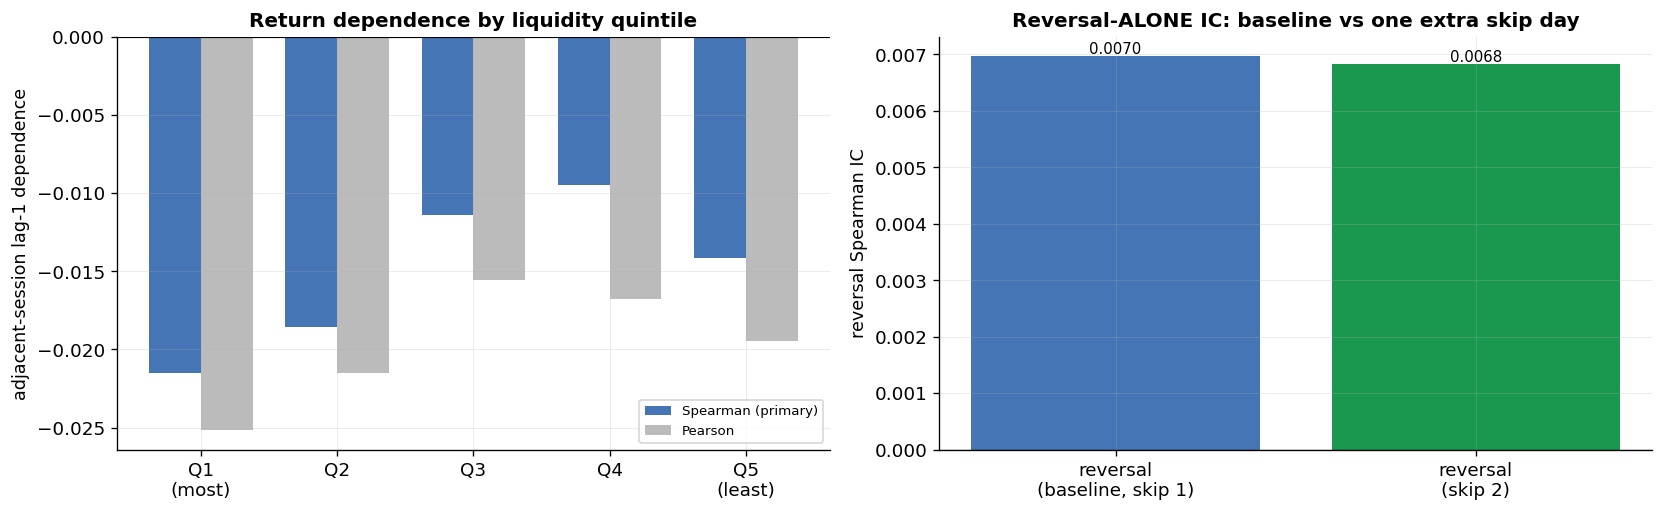

Quintile lag-1 SPEARMAN (Q1 most liquid → Q5 least): [-0.0215, -0.0186, -0.0114, -0.0095, -0.0141]
Quintile lag-1 PEARSON  (tail-sensitive): [-0.0252, -0.0215, -0.0156, -0.0168, -0.0194]
Reversal IC: baseline(skip 1)=+0.0070, skip-2=+0.0068


In [34]:
# Lag-1 autocorrelation: construct lag on FULL panel and require the actual previous market session.
prev_map, _ = make_market_date_maps(full["date"])
adj_prev = prev_adjacent_mask(full, prev_map)
full["ret_prev_1d"] = full.groupby("ticker", sort=False)["ret_actual"].shift(1).where(adj_prev)

m=full.loc[full["in_universe"]].copy()
m=m.dropna(subset=["ret_actual","ret_prev_1d","adv60"])
dc=m.groupby("date")["ticker"].transform("size"); m=m[dc>=100]
m["lq"]=m.groupby("date")["adv60"].rank(ascending=False,pct=True)
m["Q"]=pd.cut(
    m["lq"],[0,.2,.4,.6,.8,1.0],
    labels=["Q1\n(most)","Q2","Q3","Q4","Q5\n(least)"],include_lowest=True
)
acq_p, acq_s = [], []
for qv in m["Q"].cat.categories:
    z = m[m["Q"] == qv].dropna(subset=["ret_actual","ret_prev_1d"])
    acq_p.append(z["ret_actual"].corr(z["ret_prev_1d"]))
    acq_s.append(spearmanr(z["ret_actual"], z["ret_prev_1d"]).correlation)

# Reversal ALONE: all rolling construction remains on full panel.
def rev_ic(skip_extra):
    revs=[
        -full.groupby("ticker", sort=False)["ret_feature"].transform(
            lambda s:s.rolling(h).sum().shift(1+skip_extra)
        )
        for h in [3,5,10]
    ]
    rv=sum(revs)/3
    f=full.loc[full["in_universe"]].copy()
    f["rv"]=rv.loc[f.index]
    f["rv_r"]=xs_rank(f["rv"],f["date"])
    f["fwd_xs"]=f["fwd_ret"]-f.groupby("date")["fwd_ret"].transform("mean")
    d=f.dropna(subset=["rv_r","fwd_xs"])
    return d.groupby("date").apply(
        lambda x:spearmanr(x["rv_r"],x["fwd_xs"]).correlation if len(x)>=50 else np.nan
    ).dropna().mean()

ic_rev0=rev_ic(0)
ic_rev1=rev_ic(1)

fig,ax=plt.subplots(1,2,figsize=(14,4.4))
xq=np.arange(5); wq=.38
ax[0].bar(xq-wq/2,acq_s,wq,color=C_NEU,label="Spearman (primary)")
ax[0].bar(xq+wq/2,acq_p,wq,color="#bbb",label="Pearson")
ax[0].set_xticks(xq); ax[0].set_xticklabels(m["Q"].cat.categories); ax[0].axhline(0,color="k",lw=0.7)
ax[0].set_ylabel("adjacent-session lag-1 dependence"); ax[0].set_title("Return dependence by liquidity quintile")
ax[0].legend(fontsize=8)

ax[1].bar(["reversal\n(baseline, skip 1)","reversal\n(skip 2)"],[ic_rev0,ic_rev1],color=[C_NEU,C_GOOD]); ax[1].axhline(0,color="k",lw=0.7)
ax[1].set_ylabel("reversal Spearman IC"); ax[1].set_title("Reversal-ALONE IC: baseline vs one extra skip day")
for i,v in enumerate([ic_rev0,ic_rev1]):
    ax[1].text(i,v,f"{v:.4f}",ha="center",va="bottom",fontsize=9)
plt.tight_layout(); plt.show()
print(f"Quintile lag-1 SPEARMAN (Q1 most liquid → Q5 least): {[round(float(v),4) for v in acq_s]}")
print(f"Quintile lag-1 PEARSON  (tail-sensitive): {[round(float(v),4) for v in acq_p]}")
print(f"Reversal IC: baseline(skip 1)={ic_rev0:+.4f}, skip-2={ic_rev1:+.4f}")

RESULTS.update(rev_skip1=float(ic_rev0), rev_skip2=float(ic_rev1), rank_q1=float(acq_s[0]), rank_q5=float(acq_s[-1]),
               rank_q1_is_most_negative=bool(int(np.nanargmin(acq_s)) == 0))


**Result.** Reversal-alone IC is **+0.0070** at the one-day skip and **+0.0068** at two, so the multi-day reversal
doesn't decay. Rank lag-1 dependence is most negative in the most-liquid quintile (about −0.022 in Q1 vs −0.014 in Q5),
the opposite of the illiquid-bounce pattern. The bounce question itself is answered in §4.4: day `T` carries about a
third of reversal IC and the design gives it up. Ruling out close-print effects in liquid names would need quote data.


### 8.3 Overnight vs intraday — split by leg, plus index-rebalance closes

The actual adjacent next-session return is split into close→open and open→close legs, all three legs defined on the
same stock-days, and each signal is scored against each leg.

**Why split by leg.** The blend's IC is mostly momentum. Lou, Polk & Skouras (2019, *Journal of Financial Economics*
134(1), 192–213) find in 1993–2013 CRSP/TAQ data that momentum profits accrue entirely overnight, and so do short-term
reversal profits, while most other anomalies (size, value, idiosyncratic volatility, among others) earn their returns
intraday. They attribute the momentum pattern to a tug of war between clienteles, with individuals more active at
the open and institutions during the day. Closing-auction pressure and closing-print effects can explain reversal realizing
overnight; they can't explain a 12-month momentum signal doing so.

| Result | What it points to |
|---|---|
| Momentum realized close→open | The Lou–Polk–Skouras clientele pattern, not a closing-print artifact |
| Reversal realized close→open | Closing-auction/closing-print pressure is a live candidate for this leg, alongside the LPS pattern |
| Either leg realized open→close | That leg isn't driven by the close/open boundary |

**Index-rebalance closes.** Russell reconstitution dates are hardcoded: the last Friday of June, moved a week earlier
when it falls on June 28–30 (2007–12) or June 29–30 (from 2013). S&P quarterly rebalances (third Friday of March, June,
September and December) coincide with quarterly derivatives expiry, so that set can't isolate index flow.

**Adjustment-convention check.** If opens or closes were adjusted differently from the high and low, they would fall
outside the day's high–low range; the cell reports how often that happens.

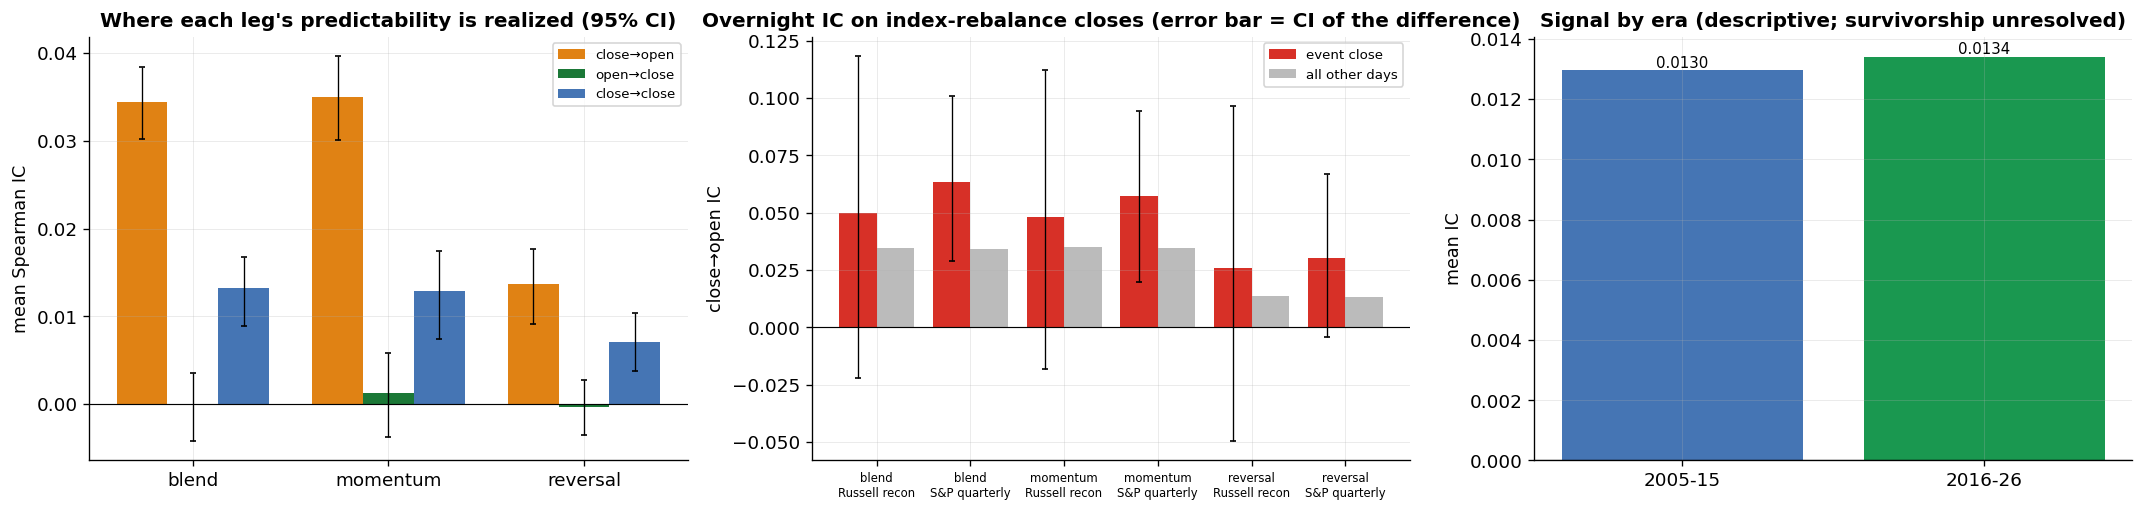

Blend: overnight IC = +0.0344 vs intraday IC = -0.0001.


leg,close→open,open→close,close→close
signal,,,
blend,0.0344,-0.0001,0.0132
momentum,0.0350,0.0013,0.0129
reversal,0.0137,-0.0003,0.0071


momentum : close→open +0.0350 [+0.0301, +0.0397] (positive); open→close +0.0013 [-0.0037, +0.0058] (not distinguishable from 0)
reversal : close→open +0.0137 [+0.0092, +0.0177] (positive); open→close -0.0003 [-0.0036, +0.0028] (not distinguishable from 0)

Index-rebalance closes vs all other days (close→open IC):


,signal,event,window,events,event_days,event_IC,other_IC,diff,lo95,hi95,share_of_days,share_of_IC_sum
0,blend,Russell recon,event close,22,22,0.0497,0.0344,0.0154,-0.0565,0.0840,0.0040,0.0058
1,blend,Russell recon,±2 sessions,22,110,0.0358,0.0344,0.0014,-0.0247,0.0279,0.0202,0.0210
2,blend,S&P quarterly,event close,85,85,0.0634,0.0340,0.0294,-0.0050,0.0670,0.0156,0.0287
3,blend,S&P quarterly,±2 sessions,85,425,0.0385,0.0341,0.0045,-0.0105,0.0201,0.0780,0.0874
4,momentum,Russell recon,event close,22,22,0.0481,0.0350,0.0132,-0.0532,0.0772,0.0040,0.0055
5,momentum,Russell recon,±2 sessions,22,110,0.0428,0.0349,0.0079,-0.0247,0.0403,0.0202,0.0246
6,momentum,S&P quarterly,event close,85,85,0.0574,0.0347,0.0228,-0.0150,0.0597,0.0156,0.0256
7,momentum,S&P quarterly,±2 sessions,85,425,0.0421,0.0344,0.0077,-0.0072,0.0227,0.0779,0.0937
8,reversal,Russell recon,event close,22,22,0.0261,0.0136,0.0124,-0.0632,0.0830,0.0040,0.0077
9,reversal,Russell recon,±2 sessions,22,110,0.0015,0.0139,-0.0124,-0.0485,0.0246,0.0202,0.0022


OHLC consistency, in-universe bars (0.1% tolerance): open outside [low, high] in 0.001% of bars; close outside in 0.000%.


In [35]:
# Next-session open/close on the FULL panel. Keep only genuine adjacent sessions and define all three legs
# on the same stock-days as the close-to-close target (fwd_ret valid, positive prices).
_, next_map = make_market_date_maps(full["date"])
adj_next = next_adjacent_mask(full, next_map)
gf = full.groupby("ticker", sort=False)
next_open = gf["open"].shift(-1)
next_close = gf["close"].shift(-1)
valid = adj_next & full["fwd_ret"].notna() & (next_open > 0) & (full["close"] > 0)
full["c2o"] = (next_open/full["close"] - 1).where(valid)
full["o2c"] = (next_close/next_open - 1).where(valid)

m3 = full.loc[full["in_universe"]].copy()
m3["mom_r"] = xs_rank(m3["mom"], m3["date"])
m3["rev_r"] = xs_rank(m3["rev"], m3["date"])
m3["s_r"] = xs_rank(0.5*m3["mom_r"] + 0.5*m3["rev_r"], m3["date"])
for leg in ["c2o","o2c","fwd_ret"]:
    m3[leg+"_xs"] = m3[leg] - m3.groupby("date")[leg].transform("mean")

# (1) Signal × leg: which leg carries each signal's predictability?
SIGS = {"blend":"s_r", "momentum":"mom_r", "reversal":"rev_r"}
LEGS = {"close→open":"c2o_xs", "open→close":"o2c_xs", "close→close":"fwd_ret_xs"}
leg_ic, rows = {}, []
for sn, sc in SIGS.items():
    for ln, lc in LEGS.items():
        ic = daily_ic(m3, sc, lc)
        leg_ic[(sn, ln)] = ic
        mu, lo, hi = block_mean_ci(ic)
        rows.append(dict(signal=sn, leg=ln, IC=mu, lo95=lo, hi95=hi, days=len(ic)))
leg_tab = pd.DataFrame(rows)
ic_c2o, ic_o2c = leg_ic[("blend","close→open")], leg_ic[("blend","open→close")]

# (2) Index-rebalance closes: public calendar dates, no auction data needed.
cal = pd.DatetimeIndex(np.sort(full["date"].unique()))
def on_or_before(d):
    return cal[cal.searchsorted(pd.Timestamp(d), side="right") - 1]

# FTSE Russell published historical rule / schedules, made explicit as dates for auditability.
RUSSELL_RECON_DATES = pd.to_datetime([
    "2005-06-24","2006-06-30","2007-06-22","2008-06-27","2009-06-26","2010-06-25",
    "2011-06-24","2012-06-22","2013-06-28","2014-06-27","2015-06-26","2016-06-24",
    "2017-06-23","2018-06-22","2019-06-28","2020-06-26","2021-06-25","2022-06-24",
    "2023-06-23","2024-06-28","2025-06-27","2026-06-26"
])
def third_friday(y, m):
    return pd.date_range(f"{y}-{m:02d}-01", f"{y}-{m:02d}-21", freq="W-FRI")[2]
yrs = range(cal[0].year, cal[-1].year + 1)
raw_events = {
    "Russell recon": list(RUSSELL_RECON_DATES),
    "S&P quarterly": [third_friday(y, m) for y in yrs for m in (3, 6, 9, 12)],
}
# A holiday (e.g. Good Friday 2008) maps to the last session before it.
EVENTS = {k: sorted({on_or_before(d) for d in v if cal[0] <= d <= cal[-1]}) for k, v in raw_events.items()}

def event_test(ic, ev_dates, window=0, B=2000, seed=7):
    # Event-window mean IC vs all other days. Event windows are resampled as clusters (they are months apart);
    # other days with 21-session blocks.
    ic = ic.dropna().sort_index(); n = len(ic)
    pos = pd.Series(np.arange(n), index=ic.index)
    clusters = [np.arange(max(0, pos[d]-window), min(n, pos[d]+window+1)) for d in ev_dates if d in pos.index]
    is_ev = np.zeros(n, bool); is_ev[np.concatenate(clusters)] = True
    ev_vals, other = [ic.values[c] for c in clusters], ic.values[~is_ev]
    rng = np.random.default_rng(seed)
    ev_b = np.array([np.concatenate([ev_vals[j] for j in rng.integers(0, len(ev_vals), len(ev_vals))]).mean()
                     for _ in range(B)])
    lo, hi = np.quantile(ev_b - block_boot_means(other, B=B, seed=seed), [0.025, 0.975])
    ev_mean = ic.values[is_ev].mean()
    return dict(events=len(clusters), event_days=int(is_ev.sum()), event_IC=ev_mean, other_IC=other.mean(),
                diff=ev_mean - other.mean(), lo95=lo, hi95=hi,
                share_of_days=is_ev.mean(), share_of_IC_sum=ic.values[is_ev].sum()/ic.sum())

ev_rows = []
for sn in SIGS:
    for en, dates in EVENTS.items():
        for wdw in (0, 2):
            r = event_test(leg_ic[(sn, "close→open")], dates, window=wdw)
            ev_rows.append(dict(signal=sn, event=en, window=("event close" if wdw == 0 else "±2 sessions"), **r))
ev_tab = pd.DataFrame(ev_rows)

# (3) Adjustment-convention check: opens/closes outside the day's [low, high] (0.1% tolerance).
bars = m3[["open","high","low","close"]].dropna()
tol = 1e-3
open_out = ((bars["open"] > bars["high"]*(1+tol)) | (bars["open"] < bars["low"]*(1-tol))).mean()
close_out = ((bars["close"] > bars["high"]*(1+tol)) | (bars["close"] < bars["low"]*(1-tol))).mean()

fig, ax = plt.subplots(1, 3, figsize=(18, 4.4))
x = np.arange(len(SIGS)); w = 0.26
for j, (ln, colr) in enumerate(zip(LEGS, ["#e08214", C_COMBO, C_NEU])):
    sub = leg_tab[leg_tab["leg"] == ln].set_index("signal").loc[list(SIGS)]
    ax[0].bar(x + (j-1)*w, sub["IC"], w, color=colr, label=ln,
              yerr=[(sub["IC"]-sub["lo95"]).clip(lower=0), (sub["hi95"]-sub["IC"]).clip(lower=0)], capsize=2, error_kw=dict(lw=0.8))
ax[0].axhline(0, color="k", lw=0.7); ax[0].set_xticks(x); ax[0].set_xticklabels(list(SIGS))
ax[0].set_ylabel("mean Spearman IC"); ax[0].legend(fontsize=8)
ax[0].set_title("Where each leg's predictability is realized (95% CI)")

e0 = ev_tab[ev_tab["window"] == "event close"]
labels = [f"{r.signal}\n{r.event}" for r in e0.itertuples()]
xe = np.arange(len(e0))
ax[1].bar(xe - 0.2, e0["event_IC"], 0.4, color=C_BAD, label="event close",
          yerr=[(e0["diff"]-e0["lo95"]).clip(lower=0), (e0["hi95"]-e0["diff"]).clip(lower=0)], capsize=2, error_kw=dict(lw=0.8))
ax[1].bar(xe + 0.2, e0["other_IC"], 0.4, color="#bbb", label="all other days")
ax[1].axhline(0, color="k", lw=0.7); ax[1].set_xticks(xe); ax[1].set_xticklabels(labels, fontsize=7)
ax[1].set_ylabel("close→open IC"); ax[1].legend(fontsize=8)
ax[1].set_title("Overnight IC on index-rebalance closes (error bar = CI of the difference)")

half = ic_base.copy()   # era comparison is descriptive only; it does not remove survivorship bias
early = half[half.index < "2016"]; late = half[half.index >= "2016"]
ax[2].bar(["2005-15","2016-26"], [early.mean(), late.mean()], color=[C_NEU, C_GOOD]); ax[2].axhline(0, color="k", lw=0.7)
for i, v in enumerate([early.mean(), late.mean()]):
    ax[2].text(i, v, f"{v:.4f}", ha="center", va="bottom", fontsize=9)
ax[2].set_ylabel("mean IC"); ax[2].set_title("Signal by era (descriptive; survivorship unresolved)")
plt.tight_layout(); plt.show()

print(f"Blend: overnight IC = {ic_c2o.mean():+.4f} vs intraday IC = {ic_o2c.mean():+.4f}.")
display(leg_tab.pivot(index="signal", columns="leg", values="IC").loc[list(SIGS), list(LEGS)].round(4))
def sign_word(r):
    return "positive" if r["lo95"] > 0 else ("negative" if r["hi95"] < 0 else "not distinguishable from 0")
for sn in ["momentum", "reversal"]:
    on = leg_tab[(leg_tab["signal"] == sn) & (leg_tab["leg"] == "close→open")].iloc[0]
    intr = leg_tab[(leg_tab["signal"] == sn) & (leg_tab["leg"] == "open→close")].iloc[0]
    print(f"{sn:9s}: close→open {on['IC']:+.4f} [{on['lo95']:+.4f}, {on['hi95']:+.4f}] ({sign_word(on)}); "
          f"open→close {intr['IC']:+.4f} [{intr['lo95']:+.4f}, {intr['hi95']:+.4f}] ({sign_word(intr)})")
print("\nIndex-rebalance closes vs all other days (close→open IC):")
display(ev_tab[["signal","event","window","events","event_days","event_IC","other_IC","diff","lo95","hi95",
                "share_of_days","share_of_IC_sum"]].round(4))
print(f"OHLC consistency, in-universe bars (0.1% tolerance): open outside [low, high] in {open_out:.3%} of bars; "
      f"close outside in {close_out:.3%}.")

_lt = leg_tab.set_index(["signal","leg"]); _on, _id = list(LEGS)[0], list(LEGS)[1]
for _s in ["blend","momentum","reversal"]:
    RESULTS[f"on_{_s}"] = float(_lt.loc[(_s,_on),"IC"]); RESULTS[f"id_{_s}"] = float(_lt.loc[(_s,_id),"IC"])
    RESULTS[f"on_{_s}_lo"] = float(_lt.loc[(_s,_on),"lo95"]); RESULTS[f"on_{_s}_hi"] = float(_lt.loc[(_s,_on),"hi95"])
_ev = ev_tab[(ev_tab["signal"]=="blend") & (ev_tab["event"]=="S&P quarterly") & (ev_tab["window"]=="event close")].iloc[0]
RESULTS.update(sp_close_ic_blend=float(_ev["event_IC"]), other_ic_blend=float(_ev["other_IC"]),
               all_rebalance_cis_span_zero=bool(((ev_tab["lo95"] < 0) & (ev_tab["hi95"] > 0)).all()),
               open_outside_range=float(open_out))

RESULTS.update(n_events_russell=int(ev_tab.loc[(ev_tab["event"]=="Russell recon") & (ev_tab["window"]=="event close"), "events"].iloc[0]),
               n_events_sp=int(ev_tab.loc[(ev_tab["event"]=="S&P quarterly") & (ev_tab["window"]=="event close"), "events"].iloc[0]))
_w2 = ev_tab[(ev_tab["signal"]=="blend") & (ev_tab["event"]=="S&P quarterly") & (ev_tab["window"]=="±2 sessions")].iloc[0]
RESULTS.update(sp_pm2_share_days=float(_w2["share_of_days"]), sp_pm2_share_ic=float(_w2["share_of_IC_sum"]))


**Result.** Both legs realize overnight.

- **Momentum:** close→open **+0.0350**, open→close +0.0013 (not significant). **Reversal:** close→open **+0.0137**,
  open→close −0.0003 (not significant). The blend: +0.0344 vs −0.0001. This is the Lou–Polk–Skouras pattern, leg for
  leg, reproduced on free data, which makes a vendor artifact less likely. A closing-print effect can't produce
  12-month momentum overnight.
- **Rebalance closes.** Every event-vs-other interval spans zero. Over ±2-session windows, S&P rebalance dates carry
  about their share of the blend's overnight IC (7.8% of days, 8.7% of the IC). On the S&P close itself the point
  estimate is higher (0.063 vs 0.034), but with 22 Russell and 85 S&P events the test is weak, so the accurate statement
  is "no detectable spike", not "no effect".
- **Adjustment check.** Opens fall outside the day's high–low range in about 0.001% of bars, so opens are adjusted
  consistently with their bar. Dividend handling of the open relative to the prior close is still unverified.
- **What's left open.** Closing-auction or closing-print pressure remains a candidate for the reversal leg alongside the
  clientele story; separating them needs auction-imbalance and NBBO data.


### 8.4 Volume-split reversal + dispersion tests, with intervals

These are **mechanism-consistency diagnostics**, not causal identification.

1. **Reversal by abnormal formation-day volume.** A liquidity-pressure mechanism predicts stronger reversal after
   unusually high volume because immediacy demand can push prices temporarily away from equilibrium. Some
   information-dominated models can instead predict continuation after high volume. But high volume itself can arise
   from many mechanisms, so the sign is evidence about consistency, not proof of what caused the move.
2. **Reversal IC vs lagged cross-sectional dispersion.** If liquidity provision becomes more costly or constrained when
   individual stocks are moving unusually far apart, reversal can be stronger after high dispersion. Dispersion is a
   market-state variable, not a direct measure of dealer inventories, order imbalance or funding constraints.

Point estimates aren't enough here: the dispersion pattern is non-monotonic, and high-dispersion days cluster in a few
episodes. So the cell adds (a) a 21-day block-bootstrap CI on high − low for both splits; (b) a by-year breakdown and
crisis-year exclusions; (c) a within-year version; and (d) a past-only threshold version that could actually be known
at the time.

**Identification limit:** daily OHLCV cannot distinguish forced liquidity demand, informed trading, closing-auction
pressure, dealer inventory constraints and other mechanisms. Doing that requires richer order-flow / auction / quote
data.

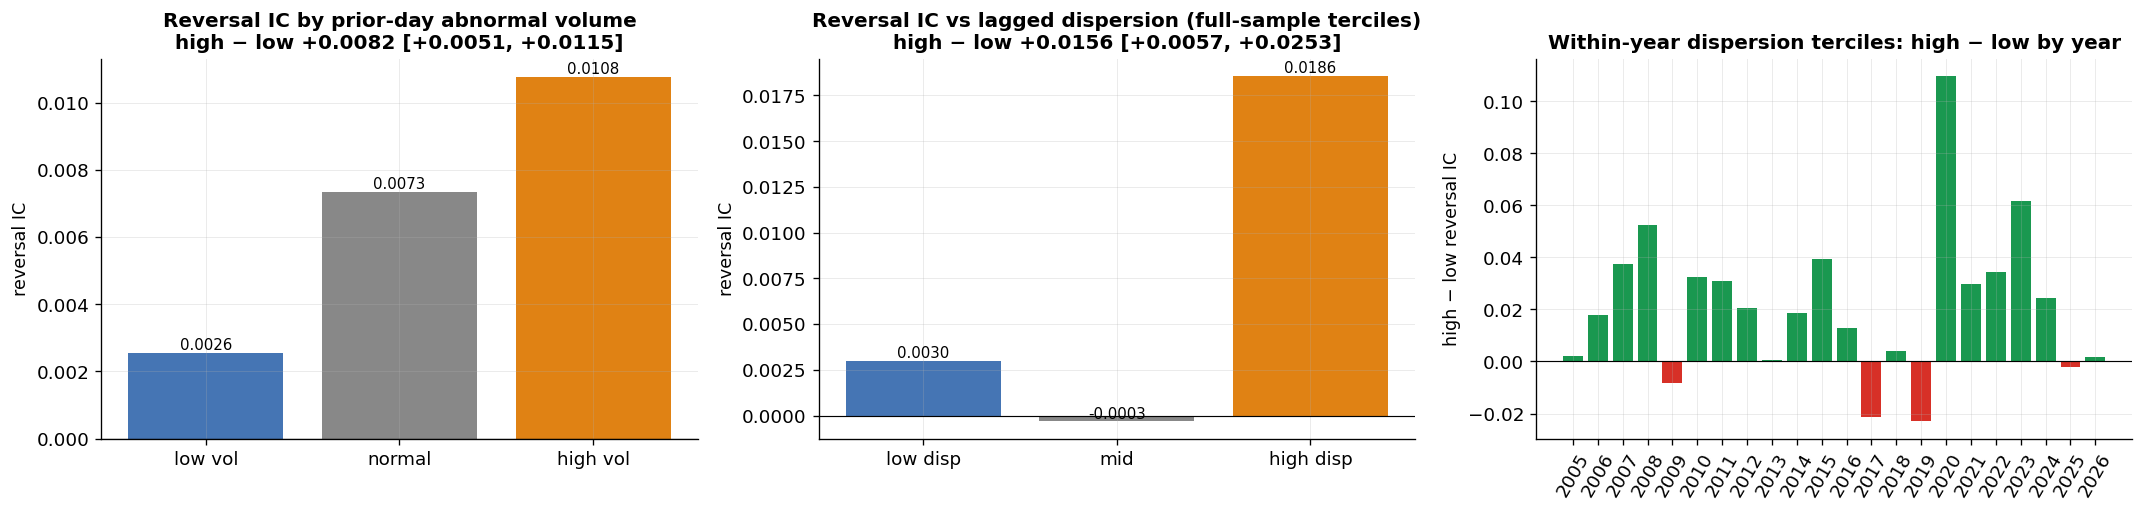

Volume split: {'low vol': 0.0026, 'normal': 0.0073, 'high vol': 0.0108}
  high − low abnormal volume (paired by date): +0.0082, 95% CI [+0.0051, +0.0115]
Dispersion terciles: {'low disp': 0.003, 'mid': -0.0003, 'high disp': 0.0186}
  high − low dispersion (full-sample terciles; descriptive): +0.0156, 95% CI [+0.0057, +0.0253]
  expanding-past terciles: {'low disp': 0.0042, 'mid': -0.0028, 'high disp': 0.0147}
  high − low dispersion (expanding past-only thresholds): +0.0105, 95% CI [+0.0012, +0.0194]
  2008-09, 2020, 2022 hold 39% of high-dispersion days and 40% of their summed reversal IC
  high − low excluding 2008-09, 2020, 2022: +0.0152, 95% CI [+0.0045, +0.0248]
  top-3 contributing years [2020, 2025, 2008]; high − low excluding them: +0.0132, 95% CI [+0.0032, +0.0232]
  within-year terciles: high − low +0.0220, 95% CI [+0.0125, +0.0323]; positive in 18 of 22 years


,high_disp_days,high_disp_rev_IC,share_of_high_disp_IC_sum
year,,,
2005,17,0.0013,0.0007
2006,34,0.0223,0.0226
2007,48,0.0508,0.0727
2008,202,0.0157,0.0947
2009,155,0.0083,0.0383
2010,16,0.0471,0.0224
2011,38,0.0606,0.0686
2012,23,0.0202,0.0139
2013,10,0.0245,0.0073


In [36]:
# (1) Formation-day abnormal volume: build the lagged volume statistic on FULL history first.
prev_map, _ = make_market_date_maps(full["date"])
adj_prev = prev_adjacent_mask(full, prev_map)
gfull = full.groupby("ticker", sort=False)

formation_dv = gfull["dollar_vol"].shift(1).where(adj_prev)
# Benchmark excludes the formation day itself: median of the preceding 20 observed sessions.
prior_dv_med = gfull["dollar_vol"].transform(
    lambda s:s.rolling(20,min_periods=10).median().shift(2)
)
full["volratio_formation"] = formation_dv / prior_dv_med

mv=full.loc[full["in_universe"]].copy()
mv["rev_r"]=xs_rank(mv["rev"],mv["date"])
mv["fwd_xs"]=mv["fwd_ret"]-mv.groupby("date")["fwd_ret"].transform("mean")
mv["volratio"] = full.loc[mv.index, "volratio_formation"]

vrank = mv.groupby("date")["volratio"].rank(pct=True)
mv["vbucket"] = pd.cut(
    vrank,[0,1/3,2/3,1],labels=["low vol","normal","high vol"],include_lowest=True
)

# Daily reversal IC inside each abnormal-volume bucket; every date has all three buckets, so high − low is PAIRED.
vol_ic = {b: daily_ic(mv[mv["vbucket"] == b], "rev_r", "fwd_xs", minn=30) for b in ["low vol","normal","high vol"]}
volsplit = {b: s.mean() for b, s in vol_ic.items()}
vc = vol_ic["high vol"].index.intersection(vol_ic["low vol"].index)
ci_vol = block_mean_ci(vol_ic["high vol"].reindex(vc) - vol_ic["low vol"].reindex(vc))

# (2) Lagged cross-sectional dispersion. The lag is a DATE-level lag, so there is no ticker-row jump.
disp = full.loc[full["in_universe"]].groupby("date").apply(
    lambda d:(d["ret_actual"]-d["ret_actual"].mean()).std()
)
disp_lag = disp.shift(1)
# Full-sample terciles are a DESCRIPTIVE diagnostic only.
terc = pd.qcut(disp_lag.rank(pct=True),3,labels=["low disp","mid","high disp"])

# Deployable sensitivity: thresholds estimated from PAST dispersion observations only.
lo_hist = disp_lag.expanding(min_periods=252).quantile(1/3).shift(1)
hi_hist = disp_lag.expanding(min_periods=252).quantile(2/3).shift(1)
terc_exp = pd.Series(index=disp_lag.index, dtype=object)
terc_exp.loc[disp_lag <= lo_hist] = "low disp"
terc_exp.loc[(disp_lag > lo_hist) & (disp_lag < hi_hist)] = "mid"
terc_exp.loc[disp_lag >= hi_hist] = "high disp"

rev_daily = daily_ic(mv, "rev_r", "fwd_xs", minn=50)
lab = terc.reindex(rev_daily.index)
byd = {t: rev_daily[lab == t].mean() for t in ["low disp","mid","high disp"]}

# Terciles fall on DIFFERENT dates, so high − low uses date-block resampling of the labeled daily series.
dd = pd.DataFrame({"ic": rev_daily, "terc": lab.astype(object), "dl": disp_lag.reindex(rev_daily.index)})
dd = dd.dropna().sort_index()
dd["terc"] = dd["terc"].astype(str)
dd["year"] = dd.index.year
ci_disp = block_boot_diff(dd["ic"], dd["terc"], "high disp", "low disp")
lab_exp = terc_exp.reindex(rev_daily.index)
dd_exp = pd.DataFrame({"ic": rev_daily, "terc": lab_exp.astype(object)}).dropna().sort_index()
dd_exp["terc"] = dd_exp["terc"].astype(str)
byd_exp = {t: dd_exp.loc[dd_exp["terc"] == t, "ic"].mean() for t in ["low disp","mid","high disp"]}
ci_disp_exp = block_boot_diff(dd_exp["ic"], dd_exp["terc"], "high disp", "low disp")

# By-year breakdown: where do high-dispersion days, and their reversal IC, come from?
hd = dd[dd["terc"] == "high disp"]
all_years = sorted(dd["year"].unique())
yr_tab = pd.DataFrame({
    "high_disp_days": hd.groupby("year").size().reindex(all_years, fill_value=0),
    "high_disp_rev_IC": hd.groupby("year")["ic"].mean().reindex(all_years),
    "share_of_high_disp_IC_sum": (hd.groupby("year")["ic"].sum() / hd["ic"].sum()).reindex(all_years, fill_value=0),
})
CRISIS = [2008, 2009, 2020, 2022]
crisis_days = hd["year"].isin(CRISIS).mean()
crisis_ic = hd.loc[hd["year"].isin(CRISIS), "ic"].sum() / hd["ic"].sum()
ex_c = dd[~dd["year"].isin(CRISIS)]
ci_disp_ex_crisis = block_boot_diff(ex_c["ic"], ex_c["terc"], "high disp", "low disp")
top_years = yr_tab["share_of_high_disp_IC_sum"].nlargest(3).index.tolist()
ex_t = dd[~dd["year"].isin(top_years)]
ci_disp_ex_top = block_boot_diff(ex_t["ic"], ex_t["terc"], "high disp", "low disp")

# Within-year terciles: rank dispersion inside each year, so crisis years cannot dominate by construction.
r_in_year = dd.groupby("year")["dl"].rank(pct=True)
dd["tiy"] = np.where(r_in_year <= 1/3, "low", np.where(r_in_year > 2/3, "high", "mid"))
wy = dd.groupby("year").apply(lambda g: g.loc[g["tiy"] == "high", "ic"].mean() - g.loc[g["tiy"] == "low", "ic"].mean())
ci_within = block_boot_diff(dd["ic"], dd["tiy"], "high", "low")

fig, ax = plt.subplots(1, 3, figsize=(18, 4.4))
ax[0].bar(list(volsplit), list(volsplit.values()), color=[C_NEU,"#888",C_REV]); ax[0].axhline(0,color="k",lw=0.7)
ax[0].set_ylabel("reversal IC")
ax[0].set_title(f"Reversal IC by prior-day abnormal volume\nhigh − low {ci_vol[0]:+.4f} [{ci_vol[1]:+.4f}, {ci_vol[2]:+.4f}]")
for i, v in enumerate(volsplit.values()):
    ax[0].text(i, v, f"{v:.4f}", ha="center", va="bottom", fontsize=9)
ax[1].bar(list(byd), list(byd.values()), color=[C_NEU,"#888",C_REV]); ax[1].axhline(0,color="k",lw=0.7)
ax[1].set_ylabel("reversal IC")
ax[1].set_title(f"Reversal IC vs lagged dispersion (full-sample terciles)\nhigh − low {ci_disp[0]:+.4f} [{ci_disp[1]:+.4f}, {ci_disp[2]:+.4f}]")
for i, v in enumerate(byd.values()):
    ax[1].text(i, v, f"{v:.4f}", ha="center", va="bottom", fontsize=9)
ax[2].bar(wy.index.astype(str), wy.values, color=[C_GOOD if v > 0 else C_BAD for v in wy.values])
ax[2].axhline(0, color="k", lw=0.7); ax[2].tick_params(axis="x", rotation=60)
ax[2].set_ylabel("high − low reversal IC")
ax[2].set_title("Within-year dispersion terciles: high − low by year")
plt.tight_layout(); plt.show()

fmt = lambda c: f"{c[0]:+.4f}, 95% CI [{c[1]:+.4f}, {c[2]:+.4f}]"
print("Volume split:", {k: round(float(v), 4) for k, v in volsplit.items()})
print("  high − low abnormal volume (paired by date):", fmt(ci_vol))
print("Dispersion terciles:", {k: round(float(v), 4) for k, v in byd.items()})
print("  high − low dispersion (full-sample terciles; descriptive):", fmt(ci_disp))
print("  expanding-past terciles:", {k: round(float(v),4) for k,v in byd_exp.items()})
print("  high − low dispersion (expanding past-only thresholds):", fmt(ci_disp_exp))
print(f"  2008-09, 2020, 2022 hold {crisis_days:.0%} of high-dispersion days and {crisis_ic:.0%} of their summed reversal IC")
print("  high − low excluding 2008-09, 2020, 2022:", fmt(ci_disp_ex_crisis))
print(f"  top-3 contributing years {top_years}; high − low excluding them:", fmt(ci_disp_ex_top))
print(f"  within-year terciles: high − low {fmt(ci_within)}; positive in {int((wy > 0).sum())} of {int(wy.notna().sum())} years")
display(yr_tab.round(4))

RESULTS.update(
    vol_low=float(volsplit["low vol"]), vol_high=float(volsplit["high vol"]),
    vol_hml=float(ci_vol[0]), vol_hml_lo=float(ci_vol[1]), vol_hml_hi=float(ci_vol[2]),
    disp_hml=float(ci_disp[0]), disp_hml_lo=float(ci_disp[1]), disp_hml_hi=float(ci_disp[2]),
    disp_hml_ex_crisis=float(ci_disp_ex_crisis[0]), disp_hml_ex_top3=float(ci_disp_ex_top[0]),
    disp_within=float(ci_within[0]), disp_within_lo=float(ci_within[1]), disp_within_hi=float(ci_within[2]),
    disp_within_pos_years=int((wy > 0).sum()), disp_within_years=int(wy.notna().sum()),
    disp_hml_pastonly=float(ci_disp_exp[0]), disp_hml_pastonly_lo=float(ci_disp_exp[1]),
    disp_hml_pastonly_hi=float(ci_disp_exp[2]),
)


**Result.**

- **Volume.** Reversal IC rises from **0.0026** after low abnormal volume to **0.0108** after high; high − low is
  **+0.0082** [+0.0051, +0.0115]. The sign is consistent with the liquidity-pressure hypothesis and goes against one
  information-dominated benchmark, but abnormal volume does not identify the underlying cause by itself.
- **Dispersion.** High − low is **+0.0156** [+0.0057, +0.0253]. It survives dropping 2008–09, 2020 and 2022 (+0.0152)
  and dropping the three biggest contributing years (+0.0132); within-year ranking gives **+0.0220**, positive in 18 of
  22 years. My prior that the effect would live mainly in crises was wrong.
- **Tradeable-state version.** With thresholds estimated from past data only, the difference shrinks to **+0.0105**
  [+0.0012, +0.0194], only just clear of zero.
- **Interpretation boundary.** These conditional patterns strengthen the case that the reversal signal behaves as a
  liquidity-provision premium, but they remain conditional associations. OHLCV alone cannot establish causality.

---
# 9. Tradeability & transaction costs
### *Full daily book diagnostics, cost sensitivity, and a post-review close→open/open→close implementation test*

The core book is formed exactly as before: top versus bottom signal deciles, inverse-volatility weights, dollar-neutral,
gross exposure one, and weights set without looking at whether an individual stock has a return tomorrow.

Two additions respond directly to faculty review:
1. §9.1 reports the standard backtest statistics explicitly rather than leaving the portfolio evidence buried behind IC.
2. §9.2 uses the same day-`T` weights to compare close→close, close→open and open→close realized P&L.

Neither addition changes or retunes the signal itself.


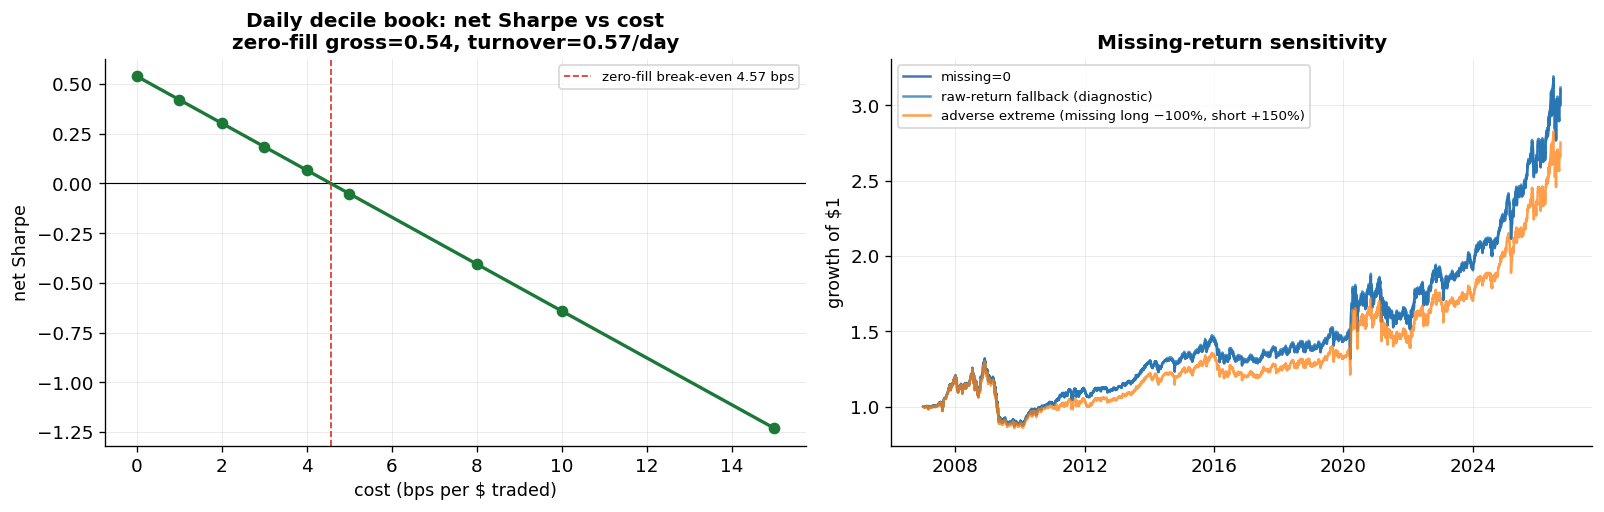

,cost_bps,net_ann_%,net_sharpe
0,0,6.510,0.539
1,1,5.084,0.421
2,2,3.658,0.303
3,3,2.232,0.185
4,4,0.806,0.067
5,5,-0.620,-0.051
6,8,-4.899,-0.405
7,10,-7.751,-0.641
8,15,-14.882,-1.230


No book on 5 date(s) without a next session for most of the universe: 2011-02-16, 2026-05-22, 2026-06-18, 2026-07-02, 2026-09-18
Held position-days with missing CLEAN next-day return: 23 / 984,590 (0.0023% of held position-days).
They represent 0.0019% of total absolute target-weight mass. Raw adjacent fallback exists for 2; |raw_fwd|>150% for 2.
Gross Sharpe: missing=0 0.539; raw-fallback diagnostic 0.540; adverse-threshold stress 0.487.
Zero-fill mean-P&L break-even under target-weight turnover = 4.57 bps per $ traded; turnover=0.57/day.
Weights are formed without looking at fwd_ret; missing returns are counted and stressed, never silently dropped.


In [37]:
live=load_stage("panel_live").sort_values(["ticker","date"]).copy()

# Risk scaling is built on full history before merging into the live universe.
risk=load_stage("panel_clean").sort_values(["ticker","date"]).copy()
risk["vol20"]=risk.groupby("ticker", sort=False)["ret_feature"].transform(
    lambda s:s.rolling(20,min_periods=15).std().shift(1)
)
live = live.drop(columns=["vol20"], errors="ignore").merge(
    risk[["ticker","date","vol20"]], on=["ticker","date"], how="left", validate="one_to_one"
)

# No book on dates without a next session. On the last date of the sample, and before a hole in the feed's calendar
# (§3.3), most of the universe has no next-day return because the data has no next session to trade into. This is a
# market-level calendar fact, the equivalent of knowing the exchange calendar; it never asks whether an individual
# stock's return exists.
next_cov = live["fwd_ret"].notna().groupby(live["date"]).mean()
no_next = next_cov[next_cov < 0.5].index
live = live[~live["date"].isin(no_next)]

# CRITICAL ANTI-LOOKAHEAD RULE: eligibility for a target weight must NOT depend on tomorrow's return existing.
live = live[(live["vol20"]>0)].dropna(subset=["vol20","combo_r"])

def sharpe(x):
    return x.mean()/x.std()*np.sqrt(252) if x.std()>0 else 0.0

def book(g):
    if len(g)<50:
        return None
    hi=g["combo_r"]>=g["combo_r"].quantile(0.9)
    lo=g["combo_r"]<=g["combo_r"].quantile(0.1)
    g=g.copy(); g["w"]=0.0
    inv=1/g["vol20"]
    if hi.sum()>0:
        g.loc[hi,"w"]=inv[hi]/inv[hi].sum()*0.5
    if lo.sum()>0:
        g.loc[lo,"w"]=-inv[lo]/inv[lo].sum()*0.5
    return g[["date","ticker","w","fwd_ret"]]

books=[book(g) for _,g in live.groupby("date")]
bk=pd.concat([b for b in books if b is not None],ignore_index=True)
held = bk["w"].ne(0)
miss = held & bk["fwd_ret"].isna()

# Build a RAW adjacent-session fallback only for diagnostics; it may itself contain a bad print/corporate-action error.
rawret = risk[["ticker","date","ret_raw_adj"]].copy()   # load_stage guarantees the column exists
_, next_map_r = make_market_date_maps(risk["date"])
adj_next_r = next_adjacent_mask(risk, next_map_r)
rawret["raw_fwd"] = rawret.groupby("ticker", sort=False)["ret_raw_adj"].shift(-1).where(adj_next_r)
bk = bk.merge(rawret[["ticker","date","raw_fwd"]], on=["ticker","date"], how="left", validate="one_to_one")

# Three return treatments. None changes TODAY'S weights based on TOMORROW'S availability.
bk["ret_zero"] = bk["fwd_ret"].fillna(0.0)
bk["ret_rawfallback"] = bk["fwd_ret"].where(bk["fwd_ret"].notna(), bk["raw_fwd"]).fillna(0.0)
bk["ret_threshold_stress"] = bk["fwd_ret"]
# Adverse threshold stress for missing held returns: long -> -100%; short -> +150% (the cleaning threshold).
bk.loc[miss & (bk["w"]>0), "ret_threshold_stress"] = -1.0
bk.loc[miss & (bk["w"]<0), "ret_threshold_stress"] = +1.5
bk["ret_threshold_stress"] = bk["ret_threshold_stress"].fillna(0.0)

def pnl_for(col):
    return bk.groupby("date").apply(lambda d:(d["w"]*d[col]).sum()).sort_index()
daily_pnl = pnl_for("ret_zero")
pnl_raw = pnl_for("ret_rawfallback")
pnl_stress = pnl_for("ret_threshold_stress")

wt=bk.pivot_table(index="date",columns="ticker",values="w",fill_value=0.0).sort_index()
turn=wt.diff().abs().sum(axis=1); turn.iloc[0]=wt.iloc[0].abs().sum()
for z in (daily_pnl,pnl_raw,pnl_stress,turn): z.index=pd.to_datetime(z.index)
c=daily_pnl.index.intersection(turn.index)
daily_pnl,turn=daily_pnl.loc[c],turn.loc[c]
pnl_raw,pnl_stress=pnl_raw.reindex(c),pnl_stress.reindex(c)

gs=sharpe(daily_pnl); gs_raw=sharpe(pnl_raw); gs_stress=sharpe(pnl_stress)
at=turn.mean(); be_exact=(daily_pnl.mean()/at)*1e4 if at>0 else np.nan
rows=[]
for bps in [0,1,2,3,4,5,8,10,15]:
    net=daily_pnl-turn*(bps/1e4)
    rows.append((bps,net.mean()*252*100,sharpe(net)))
sweep=pd.DataFrame(rows,columns=["cost_bps","net_ann_%","net_sharpe"])

missing_weight = bk.loc[miss,"w"].abs().sum(); total_weight=bk.loc[held,"w"].abs().sum()
raw_known = bk.loc[miss,"raw_fwd"].notna().sum()
raw_extreme = (bk.loc[miss,"raw_fwd"].abs()>1.5).sum()

fig,ax=plt.subplots(1,2,figsize=(13.5,4.4))
ax[0].axhline(0,color="k",lw=0.7)
ax[0].plot(sweep["cost_bps"],sweep["net_sharpe"],marker="o",color=C_COMBO,lw=2)
if np.isfinite(be_exact):
    ax[0].axvline(be_exact,color=C_BAD,ls="--",lw=1,label=f"zero-fill break-even {be_exact:.2f} bps")
    ax[0].legend(fontsize=8)
ax[0].set_xlabel("cost (bps per $ traded)"); ax[0].set_ylabel("net Sharpe")
ax[0].set_title(f"Daily decile book: net Sharpe vs cost\nzero-fill gross={gs:.2f}, turnover={at:.2f}/day")
ax[1].plot((1+daily_pnl).cumprod(),label="missing=0",color=C_NEU)
ax[1].plot((1+pnl_raw).cumprod(),label="raw-return fallback (diagnostic)",alpha=.75)
ax[1].plot((1+pnl_stress).cumprod(),label="adverse extreme (missing long −100%, short +150%)",alpha=.75)
ax[1].legend(fontsize=8); ax[1].set_title("Missing-return sensitivity"); ax[1].set_ylabel("growth of $1")
plt.tight_layout(); plt.show()

display(sweep.round(3))
print(f"No book on {len(no_next)} date(s) without a next session for most of the universe: "
      + (", ".join(str(pd.Timestamp(d).date()) for d in no_next) or "none"))
print(f"Held position-days with missing CLEAN next-day return: {miss.sum():,} / {held.sum():,} "
      f"({miss.sum()/max(int(held.sum()),1):.4%} of held position-days).")
print(f"They represent {missing_weight/max(total_weight,1e-12):.4%} of total absolute target-weight mass. Raw adjacent fallback exists for {raw_known:,}; |raw_fwd|>150% for {raw_extreme:,}.")
print(f"Gross Sharpe: missing=0 {gs:.3f}; raw-fallback diagnostic {gs_raw:.3f}; adverse-threshold stress {gs_stress:.3f}.")
print(f"Zero-fill mean-P&L break-even under target-weight turnover = {be_exact:.2f} bps per $ traded; turnover={at:.2f}/day.")
print("Weights are formed without looking at fwd_ret; missing returns are counted and stressed, never silently dropped.")

RESULTS.update(gross_sharpe=float(gs), breakeven_bps=float(be_exact), turnover=float(at),
               missing_held_share=float(miss.sum() / max(int(held.sum()), 1)),
               gross_sharpe_rawfill=float(gs_raw), gross_sharpe_stress=float(gs_stress),
               no_next_session_dates=int(len(no_next)), missing_held_n=int(miss.sum()))


**Core close→close result.** The daily decile book (inverse-volatility weights, dollar-neutral) has gross Sharpe about
**0.54**, turnover about 0.57 of the book per day, and a mean-P&L break-even of about **4.6 bps** per dollar traded.
Weights are set without looking at tomorrow's return.

**Missing next-day returns.** On five dates most of the universe has no next-day return: 2011-02-16, the sessions before
the three 2026 holiday rows in §3.3, and the last date of the sample (2026-09-18). No book is formed on those dates.
That is a date-level stand-in for an exchange calendar, not a stock-level filter based on future availability. After that,
only 23 of about 985,000 held position-days lack a clean next-day return. Gross Sharpe is 0.54 with them set to zero,
0.54 with the raw fallback, and 0.49 under the adverse-extreme stress.

The **4.6 bps** break-even is a sensitivity, not an execution estimate: impact, borrow, capacity and auction slippage are
not modeled. §9.2 now tests the stylized close→open implementation directly instead of inferring its economics from the
larger overnight IC alone.

### 9.1 Full portfolio diagnostics

Signal IC answers whether the ordering contains information. A portfolio backtest answers a different question: whether
that information survives sizing, turnover and realized return volatility.

The table below makes the existing close→close backtest explicit with annualized return, volatility, Sharpe, maximum
drawdown, positive-day frequency, long- and short-leg contribution, turnover and year-by-year behavior. This is not a new
strategy; it is a fuller report of the same book already constructed above.

,ann_return_%,ann_vol_%,Sharpe,max_drawdown_%,positive_day_%,days,turnover_per_day,break_even_bps
core close→close,6.51,12.09,0.539,-34.0,53.2,4942,0.566,4.57


,annualized_contribution_%,daily_vol_%
long leg,10.42,0.88
short leg,-3.91,0.82
combined,6.51,0.76


,ann_return_%,ann_vol_%,Sharpe,turnover,days
year,,,,,
2007,18.43,7.60,2.42,0.520,251.0
2008,2.67,16.80,0.16,0.476,253.0
2009,-29.02,15.49,-1.87,0.533,252.0
2010,13.62,7.55,1.80,0.610,252.0
2011,7.92,9.41,0.84,0.642,251.0
2012,1.77,5.11,0.35,0.597,250.0
2013,14.34,4.62,3.11,0.586,252.0
2014,2.35,6.93,0.34,0.588,252.0
2015,8.65,7.93,1.09,0.576,252.0


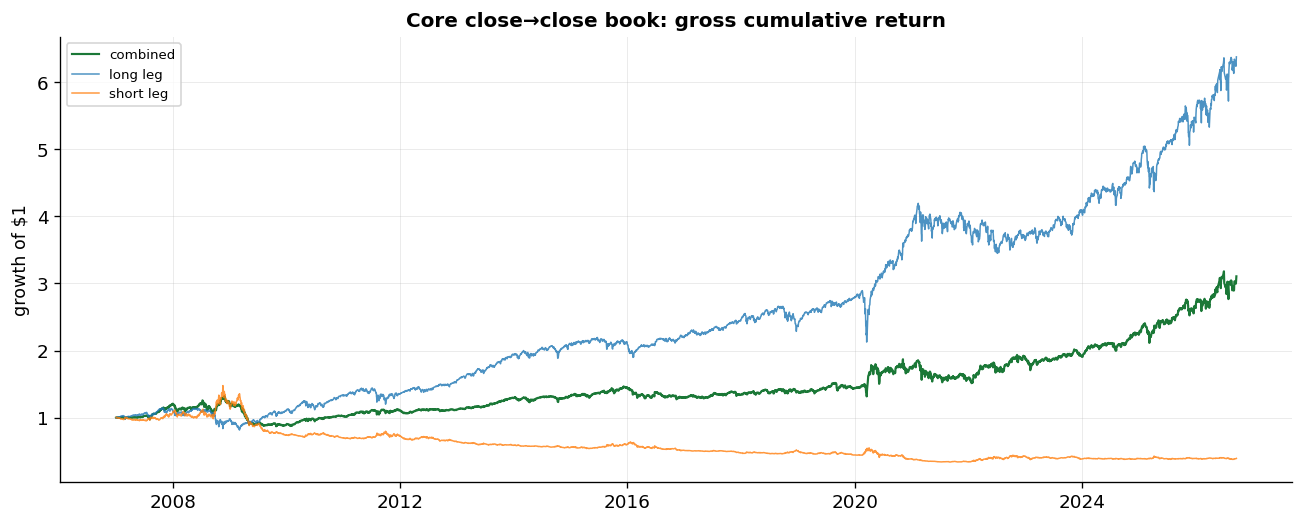

In [38]:
# Expanded diagnostics for the EXISTING close-to-close book. No new weights are formed here.

def perf_stats(pnl, turnover=None):
    pnl = pd.Series(pnl).dropna().sort_index()
    ann_ret = pnl.mean() * 252
    ann_vol = pnl.std() * np.sqrt(252)
    shp = ann_ret / ann_vol if ann_vol > 0 else np.nan
    wealth = (1.0 + pnl).cumprod()
    drawdown = wealth / wealth.cummax() - 1.0
    out = {
        "ann_return_%": ann_ret * 100,
        "ann_vol_%": ann_vol * 100,
        "Sharpe": shp,
        "max_drawdown_%": drawdown.min() * 100,
        "positive_day_%": (pnl > 0).mean() * 100,
        "days": int(len(pnl)),
    }
    if turnover is not None:
        t = pd.Series(turnover).reindex(pnl.index).fillna(0.0)
        out["turnover_per_day"] = t.mean()
        out["break_even_bps"] = pnl.mean() / t.mean() * 1e4 if t.mean() > 0 else np.nan
    return out

core_perf = perf_stats(daily_pnl, turn)
core_perf_tab = pd.DataFrame([core_perf], index=["core close→close"])
display(core_perf_tab.round({
    "ann_return_%": 2, "ann_vol_%": 2, "Sharpe": 3, "max_drawdown_%": 2,
    "positive_day_%": 1, "turnover_per_day": 3, "break_even_bps": 2
}))

# Long and short contributions using the same realized-return treatment as the headline book.
_b = bk.copy()
_b["weighted_ret_zero"] = _b["w"] * _b["ret_zero"]
long_pnl = _b.loc[_b["w"] > 0].groupby("date")["weighted_ret_zero"].sum().reindex(daily_pnl.index).fillna(0.0)
short_pnl = _b.loc[_b["w"] < 0].groupby("date")["weighted_ret_zero"].sum().reindex(daily_pnl.index).fillna(0.0)

leg_tab = pd.DataFrame({
    "annualized_contribution_%": [
        long_pnl.mean() * 252 * 100,
        short_pnl.mean() * 252 * 100,
        daily_pnl.mean() * 252 * 100,
    ],
    "daily_vol_%": [
        long_pnl.std() * 100,
        short_pnl.std() * 100,
        daily_pnl.std() * 100,
    ],
}, index=["long leg", "short leg", "combined"])
display(leg_tab.round(2))

# Year-by-year diagnostics.
_year = pd.DataFrame({"pnl": daily_pnl, "turnover": turn.reindex(daily_pnl.index)})
_year["year"] = _year.index.year
yearly_book = _year.groupby("year").apply(
    lambda d: pd.Series({
        "ann_return_%": d["pnl"].mean() * 252 * 100,
        "ann_vol_%": d["pnl"].std() * np.sqrt(252) * 100,
        "Sharpe": (d["pnl"].mean() / d["pnl"].std() * np.sqrt(252)) if d["pnl"].std() > 0 else np.nan,
        "turnover": d["turnover"].mean(),
        "days": len(d),
    })
)
display(yearly_book.round({"ann_return_%": 2, "ann_vol_%": 2, "Sharpe": 2, "turnover": 3}))

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot((1 + daily_pnl).cumprod().index, (1 + daily_pnl).cumprod().values, lw=1.3, color=C_COMBO, label="combined")
ax.plot((1 + long_pnl).cumprod().index, (1 + long_pnl).cumprod().values, lw=0.9, alpha=0.8, label="long leg")
ax.plot((1 + short_pnl).cumprod().index, (1 + short_pnl).cumprod().values, lw=0.9, alpha=0.8, label="short leg")
ax.set_title("Core close→close book: gross cumulative return")
ax.set_ylabel("growth of $1")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

RESULTS.update(
    core_book_maxdd=float(core_perf["max_drawdown_%"] / 100),
    core_book_annvol=float(core_perf["ann_vol_%"] / 100),
    core_book_positive_day=float(core_perf["positive_day_%"] / 100),
)


### 9.2 Post-review implementation test: close→open versus open→close

§8.3 found a much larger **rank IC** overnight than intraday. That does **not** automatically imply that an overnight-only
strategy is economically better. This cell tests the idea directly using the **same weights formed at the close of day
`T`**:

- **Close→close:** the existing continuously held book.
- **Close→open:** enter at the day-`T` close and flatten at the next open.
- **Open→close:** use the already-known day-`T` signal, enter at the next open and flatten at that close.

The cost convention matters. The close→close book uses **target-to-target turnover** because positions carry across days.
The flat-at-open / flat-at-close books must enter and exit the entire gross book each day, so their implementation turnover
is approximately **2 × gross exposure per day**, even when tomorrow's desired weights are identical. That is a much
harsher cost hurdle than simply reusing the 0.57/day target-to-target turnover.

This is still stylized: the close and open are treated as executable reference prices, with no auction impact, spread,
borrow, capacity or slippage model.

Return-decomposition max abs error: 3.746e-13


,ann_return_%,ann_vol_%,Sharpe,max_drawdown_%,positive_day_%,days,turnover_per_day,break_even_bps
implementation,,,,,,,,
close→close (continuous),6.51,12.09,0.539,-34.00,53.2,4942,0.566,4.57
close→open (flat at open),9.22,5.98,1.543,-13.47,58.4,4942,2.000,1.83
open→close (flat at close),-3.42,10.68,-0.320,-65.08,51.0,4942,2.000,-0.68


implementation,close→close,close→open,open→close
cost_bps_per_dollar_traded,,,
0,0.539,1.543,-0.320
1,0.421,0.700,-0.792
2,0.303,-0.143,-1.264
3,0.185,-0.987,-1.736
4,0.067,-1.830,-2.208
5,-0.051,-2.673,-2.681


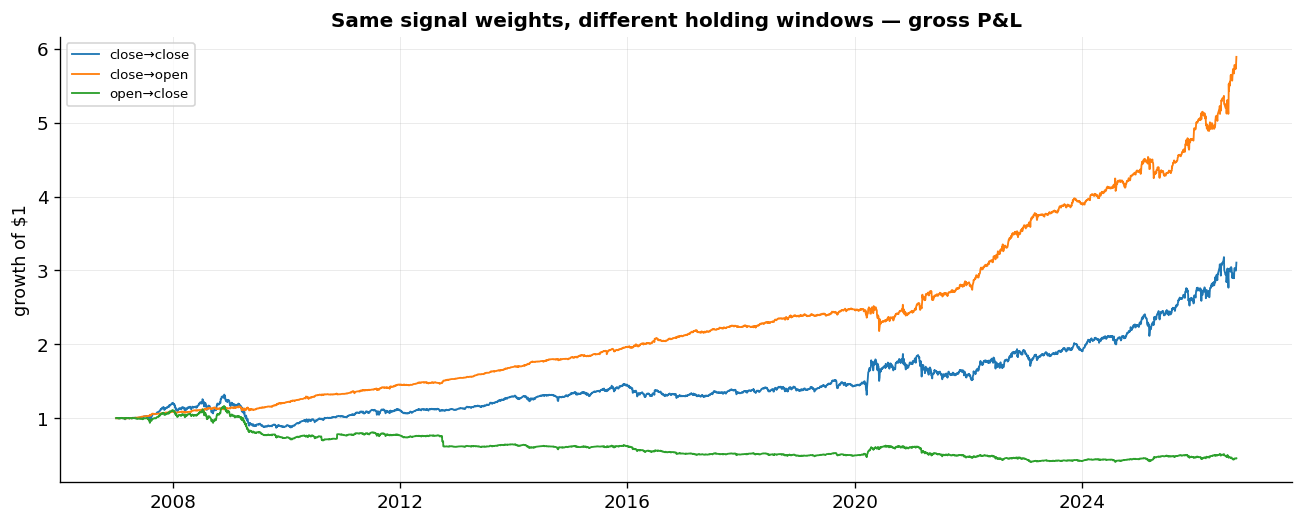

Missing realized leg among held position-days: close→open=0.0023%, open→close=0.0023%
Important: the overnight/intraday books are implementation diagnostics, not auction-execution estimates.


In [39]:
# Build adjacent-session close→open and open→close returns on the full cleaned panel.
px = load_stage("panel_clean").sort_values(["ticker", "date"]).copy()
px["date"] = pd.to_datetime(px["date"])
_, _next_map_px = make_market_date_maps(px["date"])
_adj_next_px = next_adjacent_mask(px, _next_map_px)
gpx = px.groupby("ticker", sort=False)

px["next_open"] = gpx["open"].shift(-1).where(_adj_next_px)
px["next_close"] = gpx["close"].shift(-1).where(_adj_next_px)
px["cc_clean"] = gpx["ret_actual"].shift(-1).where(_adj_next_px)

# Match §8.3: only define the decomposition when the cleaned close→close target exists and prices are positive.
_valid_leg = (
    px["cc_clean"].notna()
    & px["close"].gt(0)
    & px["next_open"].gt(0)
    & px["next_close"].gt(0)
)
px["ret_close_open"] = (px["next_open"] / px["close"] - 1.0).where(_valid_leg)
px["ret_open_close"] = (px["next_close"] / px["next_open"] - 1.0).where(_valid_leg)

# Algebra check on rows where both legs exist.
_chk = px.loc[_valid_leg, ["cc_clean", "ret_close_open", "ret_open_close"]].dropna()
_reconstructed = (1 + _chk["ret_close_open"]) * (1 + _chk["ret_open_close"]) - 1
print(f"Return-decomposition max abs error: {(_reconstructed - _chk['cc_clean']).abs().max():.3e}")

# Merge realized legs AFTER the core weights have already been formed.
bk_legs = bk.merge(
    px[["ticker", "date", "ret_close_open", "ret_open_close", "cc_clean"]],
    on=["ticker", "date"], how="left", validate="one_to_one"
)

# Future-return availability never changes today's weights. Missing realized legs are set to zero only after formation.
bk_legs["ret_on_eval"] = bk_legs["ret_close_open"].fillna(0.0)
bk_legs["ret_id_eval"] = bk_legs["ret_open_close"].fillna(0.0)

pnl_on = bk_legs.groupby("date").apply(lambda d: (d["w"] * d["ret_on_eval"]).sum()).sort_index()
pnl_id = bk_legs.groupby("date").apply(lambda d: (d["w"] * d["ret_id_eval"]).sum()).sort_index()

# Use exactly the core book dates.
idx = daily_pnl.index.intersection(pnl_on.index).intersection(pnl_id.index)
pnl_cc_cmp = daily_pnl.reindex(idx)
pnl_on = pnl_on.reindex(idx)
pnl_id = pnl_id.reindex(idx)

# Continuous close→close turnover versus flat-each-leg round-trip turnover.
gross_daily = bk_legs.groupby("date")["w"].apply(lambda s: s.abs().sum()).reindex(idx).fillna(0.0)
turn_cc = turn.reindex(idx).fillna(0.0)
turn_roundtrip = 2.0 * gross_daily

impl_rows = []
for label, pnl, t in [
    ("close→close (continuous)", pnl_cc_cmp, turn_cc),
    ("close→open (flat at open)", pnl_on, turn_roundtrip),
    ("open→close (flat at close)", pnl_id, turn_roundtrip),
]:
    m = perf_stats(pnl, t)
    m["implementation"] = label
    impl_rows.append(m)

overnight_book_tab = pd.DataFrame(impl_rows).set_index("implementation")
display(overnight_book_tab.round({
    "ann_return_%": 2, "ann_vol_%": 2, "Sharpe": 3, "max_drawdown_%": 2,
    "positive_day_%": 1, "turnover_per_day": 3, "break_even_bps": 2
}))

# Explicit cost sensitivity using the appropriate turnover convention for each implementation.
_cost_rows = []
for bps in [0, 1, 2, 3, 4, 5]:
    for label, pnl, t in [
        ("close→close", pnl_cc_cmp, turn_cc),
        ("close→open", pnl_on, turn_roundtrip),
        ("open→close", pnl_id, turn_roundtrip),
    ]:
        net = pnl - t * (bps / 1e4)
        _cost_rows.append({
            "cost_bps_per_dollar_traded": bps,
            "implementation": label,
            "net_ann_return_%": net.mean() * 252 * 100,
            "net_Sharpe": (net.mean() / net.std() * np.sqrt(252)) if net.std() > 0 else np.nan,
        })
overnight_cost_tab = pd.DataFrame(_cost_rows)
display(overnight_cost_tab.pivot(
    index="cost_bps_per_dollar_traded", columns="implementation", values="net_Sharpe"
).round(3))

fig, ax = plt.subplots(figsize=(11, 4.5))
for label, pnl in [
    ("close→close", pnl_cc_cmp),
    ("close→open", pnl_on),
    ("open→close", pnl_id),
]:
    ax.plot((1 + pnl).cumprod().index, (1 + pnl).cumprod().values, lw=1.1, label=label)
ax.set_title("Same signal weights, different holding windows — gross P&L")
ax.set_ylabel("growth of $1")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

held_leg = bk_legs["w"].ne(0)
print(
    "Missing realized leg among held position-days:",
    f"close→open={bk_legs.loc[held_leg, 'ret_close_open'].isna().mean():.4%},",
    f"open→close={bk_legs.loc[held_leg, 'ret_open_close'].isna().mean():.4%}"
)
print("Important: the overnight/intraday books are implementation diagnostics, not auction-execution estimates.")

RESULTS["postreview_close_open_backtest_built"] = True


---
# 10. Limitations & next steps

**Limitations.**
1. **Survivorship.** The free feed mostly lacks dead stocks, and point-in-time selection can't restore them. The size of
   the bias is unknown; the likely direction inflates reversal and deflates momentum.
2. **Security master.** `panel.parquet` was assembled outside this notebook. Obvious ETFs are absent and current ETF
   flags touch about 0.2% of universe rows, but current flags aren't point-in-time and ticker strings aren't stable
   identifiers (FB/META).
3. **Universe depth.** The top 1,000 reaches far deeper into the eligible set early on (about 54% vs 14%). Holding depth
   constant shrinks the recent-minus-early gap by about 40%, and in the top 250 it disappears (§8.1b); early-period costs
   are also understated.
4. **Corporate actions and calendar.** Split-like moves are rare in the universe, and opens are consistent with their
   bars, but dividend handling of the open relative to the prior close is unverified. The market calendar comes from
   the feed's own dates, and its holes (§3.3) cost data around them; an exchange calendar is the fix.
5. **Risk model.** Momentum is market-demeaned, not beta- or factor-residualized, and the book isn't sector- or
   beta-neutral. The ML neutralization in §6.3 is an **attribution diagnostic**, not a deployment rule; low volatility,
   size and related exposures would need to be explicit choices in a production risk model.
6. **Execution.** §9.2 now distinguishes continuous target-to-target turnover from full daily round-trip turnover for
   close→open/open→close books, but the prices are still stylized reference prices: no impact, borrow, capacity, spread
   model or auction slippage.
7. **Mechanism.** OHLCV locates the edge at the close/overnight boundary but can't separate auction pressure, quote
   bounce and clientele effects without auction and NBBO data.
8. **Researcher degrees of freedom.** The recent period was seen during development; this is exploratory research, and
   the criteria in §7 are fixed in advance only for the next dataset. Faculty-requested horizon/implementation tests are
   explicitly labeled post-review and are not used to retune the frozen core specification.

**What I would do with another month, in order.**
1. Rebuild on a **survivorship-safe historical common-stock security master** and rerun the frozen design against the
   criteria fixed in §7.
2. Verify split/dividend/open/close adjustment conventions against corporate-action metadata.
3. Test the close→open result with closing-auction imbalance and NBBO/trade data.
4. Add beta/sector/size residualization and carry low volatility as an explicit factor.
5. Test scaling reversal by past-only dispersion and by abnormal volume as a live conditioning rule.
6. Build a drift-aware, capacity-aware close/open execution simulator with impact, borrow and auction slippage.

**Conclusion.** Daily OHLCV carries a small, statistically detectable next-day cross-sectional signal: walk-forward IC
**+0.0131**, 95% CI **[+0.0083, +0.0178]**. Most of it is 12–1 momentum; reversal adds a nearly independent piece that
is **consistent with** a liquidity-provision interpretation, with stronger reversal after abnormal volume and high dispersion. Both are realized overnight, as
Lou, Polk & Skouras find in CRSP data. The stronger IC in 2022–26 largely reflects a more liquid universe. The only extra
OHLCV feature with unique information is low volatility, a known factor. The highest-value next step is replicating this frozen design on survivorship-safe data, not mining more features.


---
*Data: Stooq free daily ASCII. Tools: Python (pandas, numpy, scipy, scikit-learn, LightGBM). AI assistance was used for
code scaffolding, debugging and review, consistent with the brief's allowance.*


---
## 11. Appendix — reproducibility check

Every number quoted in the text above is listed here with the section that quotes it, and compared with this run.
The §3.3 and §9 counts are copied from those cells' printed output and repeated as sentences at the end of the check. **OK**
means the text matches the run. **UPDATE** means the text quotes a number this run didn't reproduce: edit it in the
named section, using the "this run" column. The cell also confirms that every intermediate file was built in this session.


In [40]:
if "wf_2022_26" in RESULTS and "wf_2005_17" in RESULTS:
    RESULTS["wf_era_gap"] = RESULTS["wf_2022_26"] - RESULTS["wf_2005_17"]

# (key in RESULTS, where the text quotes it, value in the text, tolerance)
QUOTED = [
    ("raw_rows_m",              "§0, §2.2",       20.6,    0.05),
    ("raw_tickers",             "§2.2",           9500,    300),
    ("names_2004",              "§3.5",           308,     150),
    ("names_2005",              "§3.5",           1975,    150),
    ("top20_moves_jul_sep_2026","§3.3",           14,      0),
    ("aapl_split_volume_ratio", "§3.3",           1.13,    0.006),
    ("ic_mom",                  "§0, §4.2",       0.0129,  6e-5),
    ("ir_mom",                  "§4.2",           1.02,    0.006),
    ("ir_rev",                  "§4.2",           0.70,    0.006),
    ("years_pos_mom",           "§4.2",           18,      0),
    ("years_pos_rev",           "§4.2",           18,      0),
    ("years_pos_combo",         "§4.2",           19,      0),
    ("ic_rev",                  "§0, §4.2",       0.0071,  6e-5),
    ("ic_combo",                "§0, §4.2",       0.0132,  6e-5),
    ("ir_combo",                "§0",             1.20,    0.006),
    ("corr_mom_rev",            "§0, §4.2",      -0.017,   6e-4),
    ("skip0",                   "§0, §4.4, §5.3", 0.0109,  6e-5),
    ("skip1",                   "§0, §4.4, §5.3", 0.0070,  6e-5),
    ("skip2",                   "§0, §4.4",       0.0068,  6e-5),
    ("rank_ac_lag1",            "§5.3",          -0.0101,  6e-5),
    ("rank_ac_lags_7_to_20_positive", "§5.3",     True,    0),
    ("rank_lag1_positive_years","§6.0",           3,       0),
    ("obvious_etfs_in_panel",   "§3.4a",          0,       0),
    ("current_etf_row_share",   "§0, §3.4a",      0.002,   6e-4),
    ("current_etf_tickers_in_universe", "§3.4a",  35,      0),
    ("top1000_frac_first_year", "§0, §3.4a, §10", 0.54,    0.006),
    ("top1000_frac_last_year",  "§0, §3.4a",      0.14,    0.006),
    ("adv1000_first_year_musd", "§0, §3.4a",      2.0,     0.6),
    ("adv1000_last_year_musd",  "§0, §3.4a",      89.0,    2.0),
    ("split_like_in_universe",  "§3.4a",          5,       0),
    ("ic_gapfade",              "§6.1",           0.0035,  6e-5),
    ("ic_idvol",                "§6.2",           0.0110,  6e-5),
    ("ic_max",                  "§6.2",           0.0102,  6e-5),
    ("ic_skew",                 "§6.2, §6.4",     0.0038,  6e-5),
    ("uniq_idvol",              "§0, §6.2b",      0.0109,  6e-5),
    ("uniq_max",                "§0, §6.2b",      0.0091,  6e-5),
    ("uniq_skew",               "§6.2b",          0.0035,  6e-5),
    ("fwer_skew",               "§0, §6.2b",      0.19,    0.006),
    ("corr_max_idvol",          "§0, §6.2b",      0.68,    0.006),
    ("fixedw_idvol",            "§6.2b",          0.0037,  6e-5),
    ("fixedw_max",              "§6.2b",          0.0027,  6e-5),
    ("ml_simple",               "§6.3",           0.0124,  6e-5),
    ("ml_ridge_core",           "§6.3",           0.0124,  6e-5),
    ("ml_ridge_cond",           "§6.3",           0.0159,  6e-5),
    ("ml_gbm",                  "§6.3",           0.0173,  6e-5),
    ("ml_cond_gain",            "§6.3",           0.0035,  6e-5),
    ("ml_cond_gain_neutral",    "§6.3",           0.0004,  6e-5),
    ("ml_gbm_minus_ridge",      "§0, §6.3",       0.0014,  6e-5),
    ("ml_total_neutral",        "§0, §6.3",       0.0010,  6e-5),
    ("ml_total_neutral_lo",     "§0, §6.3",      -0.0002,  6e-5),
    ("ml_total_neutral_hi",     "§0, §6.3",       0.0023,  6e-5),
    ("wf_ic",                   "§0, §7, §10",    0.0131,  6e-5),
    ("wf_ir",                   "§0, §7",         1.09,    0.006),
    ("wf_days",                 "§0, §7",         4943,    0),
    ("wf_ci_lo",                "§0, §7, §10",    0.0083,  6e-5),
    ("wf_ci_hi",                "§0, §7, §10",    0.0178,  6e-5),
    ("wf_2005_17",              "§7",             0.0103,  6e-5),
    ("wf_2018_21",              "§7",             0.0125,  6e-5),
    ("wf_2022_26",              "§0, §7",         0.0203,  6e-5),
    ("recent_ci_lo",            "§7.2",           0.0105,  6e-5),
    ("recent_ci_hi",            "§7.2",           0.0288,  6e-5),
    ("baseline_ic",             "§8.1",           0.0132,  6e-5),
    ("top250_ic",               "§8.1",           0.0165,  6e-5),
    ("top500_ic",               "§8.1",           0.0150,  6e-5),
    ("top1500_ic",              "§8.1",           0.0126,  6e-5),
    ("ic_ex_current_etfs",      "§0, §8.1",       0.0132,  6e-5),
    ("ic_null_split_like",      "§8.1",           0.0132,  6e-5),
    ("era_2005_17_top1000",     "§8.1b",          0.0115,  6e-5),
    ("era_2022_26_top1000",     "§8.1b",          0.0190,  6e-5),
    ("era_2005_17_top250",      "§8.1b",          0.0177,  6e-5),
    ("era_2022_26_top250",      "§8.1b",          0.0183,  6e-5),
    ("era_gap_top1000",         "§0, §8.1b",      0.0074,  6e-5),
    ("era_gap_const_depth",     "§0, §8.1b",      0.0042,  6e-5),
    ("era_gap_top250",          "§0, §7, §8.1b",  0.0006,  6e-5),
    ("wf_era_gap",              "§8.1b",          0.0100,  6e-5),
    ("rev_skip1",               "§8.2",           0.0070,  6e-5),
    ("rev_skip2",               "§8.2",           0.0068,  6e-5),
    ("rank_q1",                 "§0, §8.2",      -0.022,   0.0015),
    ("rank_q5",                 "§0, §8.2",      -0.014,   0.0015),
    ("rank_q1_is_most_negative","§0, §8.2",       True,    0),
    ("on_blend",                "§8.3",           0.0344,  6e-5),
    ("id_blend",                "§8.3",          -0.0001,  6e-5),
    ("on_momentum",             "§0, §8.3",       0.0350,  6e-5),
    ("id_momentum",             "§0, §8.3",       0.0013,  6e-5),
    ("on_reversal",             "§0, §8.3",       0.0137,  6e-5),
    ("id_reversal",             "§0, §8.3",      -0.0003,  6e-5),
    ("all_rebalance_cis_span_zero", "§0, §8.3",   True,    0),
    ("n_events_russell",        "§0, §8.3",       22,      0),
    ("n_events_sp",             "§0, §8.3",       85,      0),
    ("sp_pm2_share_days",       "§8.3",           0.078,   6e-4),
    ("sp_pm2_share_ic",         "§8.3",           0.087,   6e-4),
    ("sp_close_ic_blend",       "§8.3",           0.063,   6e-4),
    ("other_ic_blend",          "§8.3",           0.034,   6e-4),
    ("vol_low",                 "§8.4",           0.0026,  6e-5),
    ("vol_high",                "§8.4",           0.0108,  6e-5),
    ("vol_hml",                 "§0, §8.4",       0.0082,  6e-5),
    ("vol_hml_lo",              "§0, §8.4",       0.0051,  6e-5),
    ("vol_hml_hi",              "§0, §8.4",       0.0115,  6e-5),
    ("disp_hml",                "§0, §8.4",       0.0156,  6e-5),
    ("disp_hml_lo",             "§0, §8.4",       0.0057,  6e-5),
    ("disp_hml_hi",             "§0, §8.4",       0.0253,  6e-5),
    ("disp_hml_ex_crisis",      "§8.4",           0.0152,  6e-5),
    ("disp_hml_ex_top3",        "§8.4",           0.0132,  6e-5),
    ("disp_within",             "§0, §8.4",       0.0220,  6e-5),
    ("disp_within_pos_years",   "§0, §8.4",       18,      0),
    ("disp_hml_pastonly",       "§0, §8.4",       0.0105,  6e-5),
    ("disp_hml_pastonly_lo",    "§0, §8.4",       0.0012,  6e-5),
    ("disp_hml_pastonly_hi",    "§0, §8.4",       0.0194,  6e-5),
    ("gross_sharpe",            "§0, §9",         0.54,    0.015),
    ("breakeven_bps",           "§0, §9",         4.6,     0.1),
    ("turnover",                "§9",             0.57,    0.01),
]

rows = []
for key, where, q, tol in QUOTED:
    v = RESULTS.get(key, None)
    if v is None:
        status = "not computed"
    elif isinstance(q, bool):
        status = "OK" if bool(v) == q else "UPDATE"
    else:
        status = "OK" if (np.isfinite(v) and abs(float(v) - q) <= tol) else "UPDATE"
    rows.append(dict(quoted_in=where, key=key, text_says=q, this_run=v, status=status))
chk = pd.DataFrame(rows)
display(chk)
bad = chk[chk["status"] == "UPDATE"]
if bad.empty:
    print("Every number quoted in the text matches this run.")
else:
    print(f"{len(bad)} number(s) in the text need updating:")
    for r in bad.itertuples(index=False):
        print(f"  {r.quoted_in}: {r.key} — text says {r.text_says}, this run gives {r.this_run}")
na = chk[chk["status"] == "not computed"]
if not na.empty:
    print("Not computed in this run (e.g. no internet for the ETF directory):", ", ".join(na["key"]))

# Results the text describes but deliberately doesn't quote: optional sentences to paste.
print("\nOptional sentences with this run's exact numbers:")
if "feed_calendar_holes" in RESULTS:
    print(f"  §3.3 reading: the calendar check flags {RESULTS['feed_calendar_holes']} date(s) since 2005 "
          "(a thin date and the session after it each count).")
if "missing_held_n" in RESULTS:
    print(f"  §9 reading: no book on {RESULTS['no_next_session_dates']} date(s) without a next session; "
          f"{RESULTS['missing_held_n']:,} held position-days ({RESULTS['missing_held_share']:.3%}) still lack a clean "
          f"next-day return. Gross Sharpe is {RESULTS['gross_sharpe']:.2f} with them at zero, "
          f"{RESULTS['gross_sharpe_rawfill']:.2f} with the raw return and {RESULTS['gross_sharpe_stress']:.2f} at the "
          "adverse extreme.")

# Every intermediate file should come from this session.
print("\nStage provenance:")
stale, prev_t = False, ""
for name in ["panel_continuous", "panel_clean", "panel_feat", "panel_live"]:
    meta = json.load(open(f"{OUT}/{name}.manifest.json"))
    same = meta["session"] == SESSION_ID
    in_order = meta["written_utc"] >= prev_t          # each stage must be newer than the one it was built from
    stale |= (not same) or (not in_order)
    prev_t = meta["written_utc"]
    print(f"  {name:17s} {meta['rows']:>12,} rows, written {meta['written_utc']} UTC"
          + ("" if same else "   ← earlier session") + ("" if in_order else "   ← older than its input"))
print("All stages were built in this session, in order." if not stale else
      "Some stages are stale or out of order: Restart and Run all before submitting.")


,quoted_in,key,text_says,this_run,status
0,"§0, §2.2",raw_rows_m,20.6,20.609355,OK
1,§2.2,raw_tickers,9500,9530,OK
2,§3.5,names_2004,308,311,OK
3,§3.5,names_2005,1975,1975,OK
4,§3.3,top20_moves_jul_sep_2026,14,14,OK
...,...,...,...,...,...
106,"§0, §8.4",disp_hml_pastonly_lo,0.0012,0.001176,OK
107,"§0, §8.4",disp_hml_pastonly_hi,0.0194,0.019438,OK
108,"§0, §9",gross_sharpe,0.54,0.538634,OK
109,"§0, §9",breakeven_bps,4.6,4.565096,OK


Every number quoted in the text matches this run.

Optional sentences with this run's exact numbers:
  §3.3 reading: the calendar check flags 8 date(s) since 2005 (a thin date and the session after it each count).
  §9 reading: no book on 5 date(s) without a next session; 23 held position-days (0.002%) still lack a clean next-day return. Gross Sharpe is 0.54 with them at zero, 0.54 with the raw return and 0.49 at the adverse extreme.

Stage provenance:
  panel_continuous    20,385,519 rows, written 2026-09-26 23:10:12 UTC
  panel_clean         20,385,519 rows, written 2026-09-26 23:11:54 UTC
  panel_feat           5,404,412 rows, written 2026-09-26 23:13:16 UTC
  panel_live           4,904,981 rows, written 2026-09-26 23:47:21 UTC
All stages were built in this session, in order.
